# ¿A qué precio vender? Regresión lineal (OLS) sobre `secondary_market`

**Decisiones de este notebook**
- Pregunta única: *a qué precio vender* (dataset principal `secondary_market.csv`).
- **Sin transformación logarítmica**: el target es `price_rub` en su escala original.
- **Sin variables nuevas**: solo columnas originales (no hay uniones ni columnas derivadas en `df`).
- **Outliers:** se quitan los anuncios cuyo precio supera Q3 + 1,5·IQR **dentro de su okrug**, en una sola pasada.
- **Baseline:** 4 numéricas + 4 categóricas, elegidas con el EDA.

**Orden:** 0. Setup → 1. EDA por archivo → 2. Univariado → 3. Bivariado → 4. Outliers → 5. Baseline (MLflow).

Corré las celdas de arriba hacia abajo. Dependencias: EDA-11 usa `M` de EDA-6; la sección 5 usa `df` ya filtrado.

## 0. Setup

### Instalación (solo si falta algo)

In [2]:
%pip install -q mlflow statsmodels scikit-learn scipy matplotlib pandas seaborn

Note: you may need to restart the kernel to use updated packages.


### Imports y experimento MLflow

In [31]:
%matplotlib inline
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.stattools import durbin_watson, jarque_bera, omni_normtest
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import mlflow

BASE_DIR = "/home/facucasa/Regresion_parcial"
EXPERIMENT_NAME = "Parcial_Regresion_Ventas"

os.makedirs(f"{BASE_DIR}/mlartifacts", exist_ok=True)

# Metadatos de las corridas (parámetros, métricas, tags) en SQLite
mlflow.set_tracking_uri(f"sqlite:///{BASE_DIR}/mlflow.db")

# Artefactos (gráficos, summary.txt, coefficients.csv) en la misma carpeta.
# El artifact_location solo se define al crear el experimento.
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(EXPERIMENT_NAME, artifact_location=f"file://{BASE_DIR}/mlartifacts")
mlflow.set_experiment(EXPERIMENT_NAME)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Artifacts en:", mlflow.get_experiment_by_name(EXPERIMENT_NAME).artifact_location)

Tracking URI: sqlite:////home/facucasa/Regresion_parcial/mlflow.db
Artifacts en: file:///home/facucasa/Regresion_parcial/mlartifacts


### Carga de los 5 CSV

In [32]:
RUTA = "/home/facucasa/Regresion_parcial/dataset/"   # carpeta donde están los 5 CSV (ajustala)

df  = pd.read_csv(RUTA + "secondary_market.csv")           # tabla principal: anuncios de venta
dpm = pd.read_csv(RUTA + "district_prices_monthly.csv")    # panel distrito × mes
ms  = pd.read_csv(RUTA + "metro_stations.csv")             # catálogo de estaciones
nb  = pd.read_csv(RUTA + "new_builds.csv")                 # anuncios de obra nueva
rn  = pd.read_csv(RUTA + "rentals.csv")                    # anuncios de alquiler

TARGET = "price_rub"

for nombre, d in [("secondary_market (df)", df), ("district_prices_monthly (dpm)", dpm),
                  ("metro_stations (ms)", ms), ("new_builds (nb)", nb), ("rentals (rn)", rn)]:
    print(f"{nombre:32s} {d.shape[0]:>7,} filas × {d.shape[1]:>2} columnas")

secondary_market (df)             50,000 filas × 26 columnas
district_prices_monthly (dpm)      9,804 filas × 13 columnas
metro_stations (ms)                  104 filas ×  6 columnas
new_builds (nb)                    8,000 filas × 25 columnas
rentals (rn)                      20,000 filas × 22 columnas


### Funciones reutilizables

In [33]:
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display

sns.set_theme(style="whitegrid")

def millions(ax, axis="x"):
    fmt = FuncFormatter(lambda v, _: f"{v/1e6:,.0f}M")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)

def show(tbl, p_cols=(), dec=3):
    t = tbl.copy()
    for c in p_cols:
        t[c] = t[c].map(lambda v: f"{v:.2e}")
    display(t.round(dec))

def iqr_stats(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    return {"n": int(s.count()), "media": s.mean(), "desv": s.std(), "min": s.min(),
            "q1": q1, "mediana": s.median(), "q3": q3, "max": s.max(),
            "asimetria": s.skew(), "curtosis": s.kurt(), "iqr": iqr,
            "lim_inf": lo, "lim_sup": hi, "n_outliers": n_out,
            "%_outliers": 100 * n_out / s.count()}

def perfil_calidad(data, nombre):
    """Tamaño, duplicados, tipos, nulos y valores únicos de cada columna."""
    print(f"\n{'=' * 70}\n{nombre}: {len(data):,} filas × {data.shape[1]} columnas | "
          f"filas duplicadas: {data.duplicated().sum()}")
    t = pd.DataFrame({"tipo": data.dtypes.astype(str), "nulos": data.isna().sum(),
                      "%_nulos": 100 * data.isna().mean(), "únicos": data.nunique()})
    show(t, dec=2)

def eda_univariado(data, nombre, num_cont=(), num_disc=(), cat_nom=(), bin_cols=(),
                   top_n=15, en_millones=()):
    """EDA univariado de una tabla: misma lógica que EDA-2 a EDA-5, parametrizada."""
    perfil_calidad(data, nombre)

    rows = {}
    for col in num_cont:
        s = data[col].dropna()
        fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True,
                                 gridspec_kw={"height_ratios": [3, 1, 1.6]})
        sns.histplot(s, bins=60, kde=True, ax=axes[0])
        axes[0].axvline(s.mean(), color="red", ls="--", lw=1.2, label=f"media = {s.mean():,.1f}")
        axes[0].axvline(s.median(), color="green", ls="-", lw=1.2, label=f"mediana = {s.median():,.1f}")
        axes[0].legend()
        axes[0].set_title(f"[{nombre}] {col}: histograma + KDE, boxplot y violin")
        sns.boxplot(x=s, ax=axes[1], fliersize=2, color="lightsteelblue")
        sns.violinplot(x=s, ax=axes[2], cut=0, inner="quartile", color="lightsteelblue")
        axes[1].set_xlabel("")
        if col in en_millones:
            millions(axes[2], "x")
            axes[2].set_xlabel(f"{col} (millones)")
        plt.tight_layout()
        plt.show()
        rows[col] = iqr_stats(s)
    if rows:
        print(f"[{nombre}] Numéricas continuas: estadísticos y outliers por IQR")
        show(pd.DataFrame.from_dict(rows, orient="index"))

    rows = {}
    for col in num_disc:
        s = data[col].dropna()
        vc = s.value_counts().sort_index()
        pct = 100 * vc / vc.sum()
        fig, axes = plt.subplots(2, 1, figsize=(10, 6), gridspec_kw={"height_ratios": [3, 1]})
        bars = axes[0].bar(vc.index.astype(str), vc.values, color="steelblue")
        axes[0].bar_label(bars, labels=[f"{p:.1f}%" for p in pct], fontsize=7)
        axes[0].set(title=f"[{nombre}] {col}: frecuencia por valor y boxplot", ylabel="Frecuencia")
        sns.boxplot(x=s, ax=axes[1], fliersize=3, color="lightsteelblue")
        plt.tight_layout()
        plt.show()
        rows[col] = {"n_valores": s.nunique()} | iqr_stats(s)
    if rows:
        print(f"[{nombre}] Numéricas discretas: estadísticos y outliers por IQR")
        show(pd.DataFrame.from_dict(rows, orient="index"))

    rows = {}
    for col in cat_nom:
        vc = data[col].value_counts()
        pct = 100 * vc / vc.sum()
        plot_vc = vc.head(top_n).copy()
        if len(vc) > top_n:
            plot_vc["Otras"] = vc.iloc[top_n:].sum()
        plot_pct = 100 * plot_vc / vc.sum()
        fig, ax = plt.subplots(figsize=(9, max(3, 0.38 * len(plot_vc) + 1)))
        bars = ax.barh(plot_vc.index.astype(str), plot_vc.values, color="steelblue")
        if "Otras" in plot_vc.index:
            bars[-1].set_color("lightgray")
        ax.invert_yaxis()
        ax.bar_label(bars, labels=[f"{p:.1f}%  (n={n:,})" for p, n in zip(plot_pct, plot_vc)],
                     fontsize=8, padding=3)
        ax.margins(x=0.22)
        titulo = f"[{nombre}] {col}: {len(vc)} categorías"
        if len(vc) > top_n:
            titulo += f" (top {top_n} + 'Otras')"
        ax.set(title=titulo, xlabel="Frecuencia")
        plt.tight_layout()
        plt.show()
        rows[col] = {"n_categorias": len(vc), "moda": vc.index[0], "moda_%": pct.iloc[0],
                     "top3_%acum": pct.head(3).sum(),
                     "menos_frecuente": vc.index[-1], "menos_frecuente_%": pct.iloc[-1]}
    if rows:
        print(f"[{nombre}] Categóricas nominales")
        show(pd.DataFrame.from_dict(rows, orient="index"), dec=2)

    if bin_cols:
        fig, axes = plt.subplots(1, len(bin_cols), figsize=(5 * len(bin_cols), 4.5), squeeze=False)
        rows = []
        for ax, col in zip(axes[0], bin_cols):
            vc = data[col].value_counts().sort_index()
            pct = 100 * vc / vc.sum()
            bars = ax.bar(vc.index.astype(str), pct.values, color=["lightgray", "steelblue"][:len(vc)])
            ax.bar_label(bars, labels=[f"{p:.1f}%\n(n={n:,})" for p, n in zip(pct, vc)], fontsize=9)
            ax.set(title=col, ylabel="% de filas", ylim=(0, 100))
            for v, n, p in zip(vc.index, vc.values, pct.values):
                rows.append({"variable": col, "valor": str(v), "n": n, "%": p})
        fig.suptitle(f"[{nombre}] Variables binarias: % por valor")
        plt.tight_layout()
        plt.show()
        show(pd.DataFrame(rows).set_index(["variable", "valor"]), dec=2)

### EDA-1: configuración y clasificación de variables

In [6]:
from scipy.stats import chi2_contingency
from statsmodels.formula.api import ols as smf_ols
from statsmodels.stats.anova import anova_lm

SEED = 42
RNG = np.random.default_rng(SEED)
TOP_N = 15        # máximo de categorías a dibujar en variables con muchas categorías
SAMPLE_N = 8000   # muestra solo para dibujar scatter/lmplot (las pruebas usan todo el dataset)

eda = df          # el EDA usa df tal cual: no se crea ninguna columna nueva

# --- Clasificación de variables (todas son columnas originales de secondary_market) ---
NUM_CONT = ["price_rub", "price_per_sqm", "total_area", "living_area", "kitchen_area",
            "building_year", "metro_distance_min", "to_center_km", "lat", "lon"]
NUM_DISC = ["rooms", "floor", "total_floors", "ceiling_height", "mortgage_rate_at_listing"]
CAT_NOM = ["okrug", "district", "building_type", "renovation", "metro_line", "metro_station"]
BIN = ["has_balcony", "seller_type", "metro_distance_type"]

# price_per_sqm = price_rub / total_area: deriva del target, se excluye del bivariado
BIV_EXCLUDE = ["price_per_sqm"]

sin_clasificar = set(eda.columns) - set(NUM_CONT + NUM_DISC + CAT_NOM + BIN) - {"id", "date_posted"}
print("Variables sin clasificar:", sin_clasificar or "ninguna")

def millones_pairplot(pp):
    """Muestra el precio en millones en los ejes del pairplot (sin crear columnas)."""
    for ax in pp.axes.flat:
        if ax is None:
            continue
        if ax.get_xlabel() == TARGET:
            millions(ax, "x")
        if ax.get_ylabel() == TARGET:
            millions(ax, "y")

Variables sin clasificar: ninguna


## 1. EDA por archivo

Perfil de calidad y univariado de las variables propias de cada archivo auxiliar (contexto; el modelo usa solo `secondary_market`).

### new_builds


new_builds: 8,000 filas × 25 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,únicos
id,str,0,0.0,8000
date_posted,str,0,0.0,1910
complex_id,str,0,0.0,250
complex_name,str,0,0.0,20
developer,str,0,0.0,11
complex_class,str,0,0.0,4
district,str,0,0.0,109
okrug,str,0,0.0,11
lat,float64,0,0.0,249
lon,float64,0,0.0,250


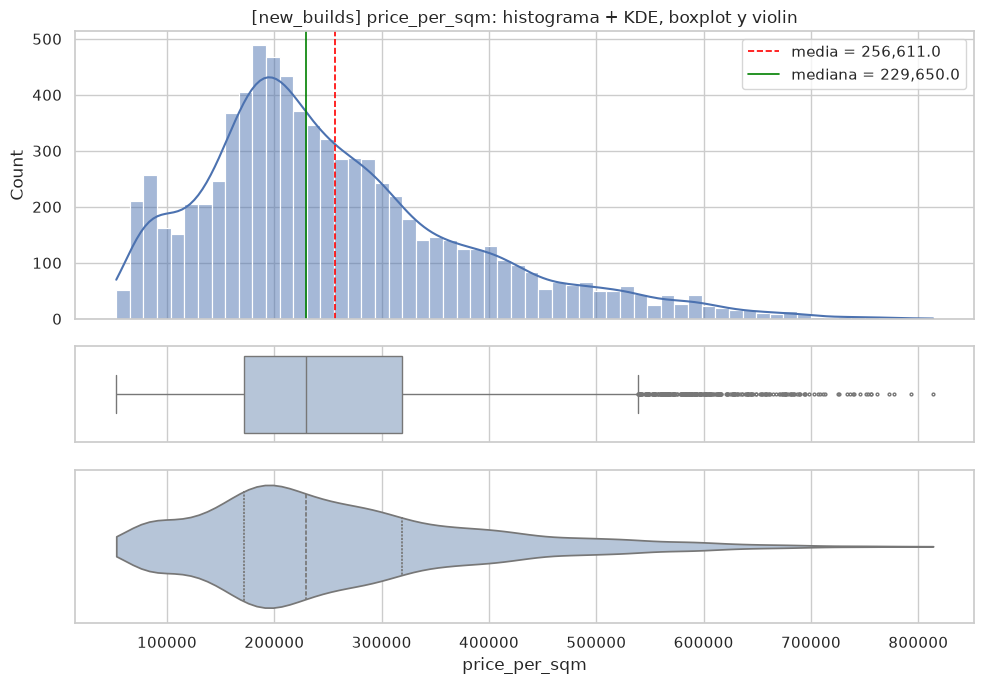

[new_builds] Numéricas continuas: estadísticos y outliers por IQR


,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
price_per_sqm,8000,256610.95,126395.896,52700,171775.0,229650.0,318625.0,813800,1.002,0.947,146850.0,-48500.0,538900.0,291,3.638


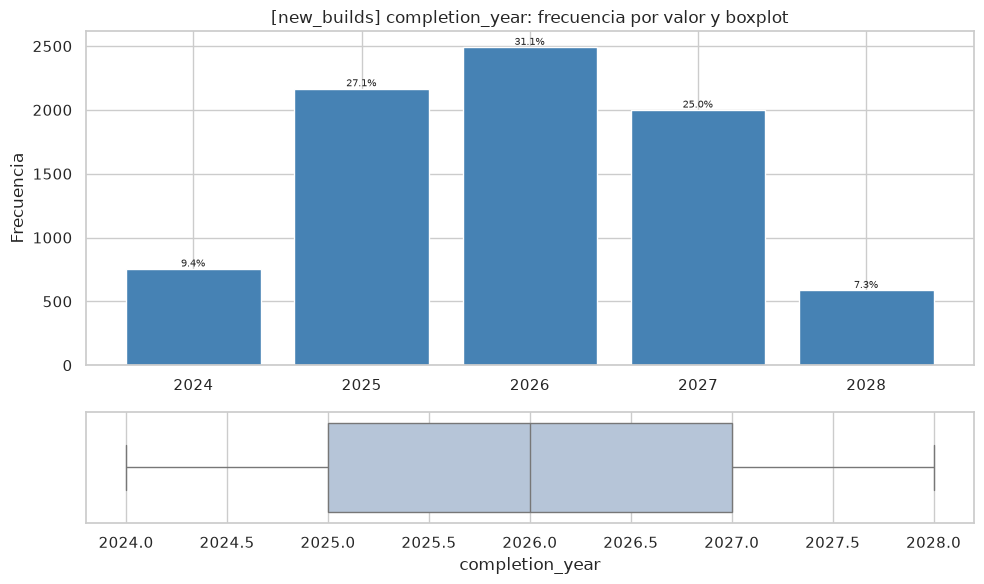

[new_builds] Numéricas discretas: estadísticos y outliers por IQR


,n_valores,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
completion_year,5,8000,2025.937,1.09,2024,2025.0,2026.0,2027.0,2028,0.027,-0.742,2.0,2022.0,2030.0,0,0.0


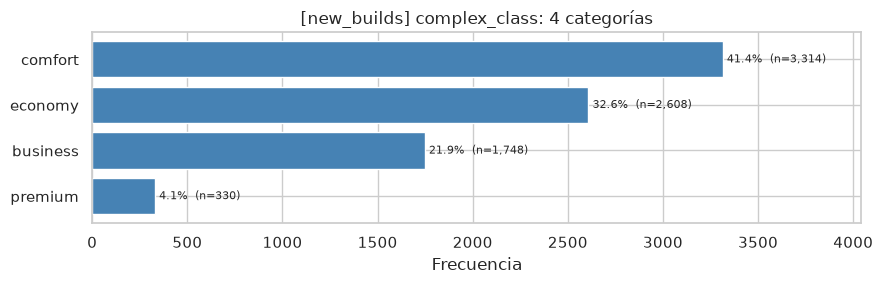

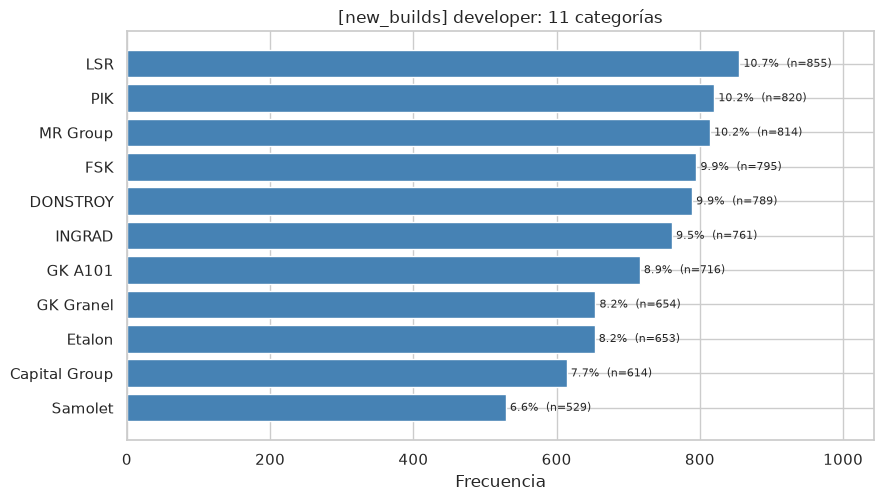

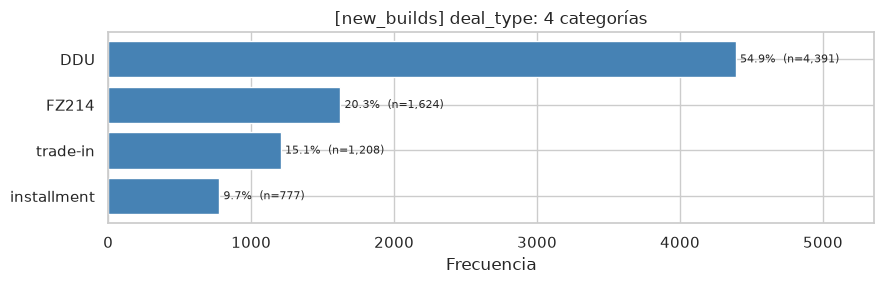

[new_builds] Categóricas nominales


,n_categorias,moda,moda_%,top3_%acum,menos_frecuente,menos_frecuente_%
complex_class,4,comfort,41.42,95.88,premium,4.12
developer,11,LSR,10.69,31.11,Samolet,6.61
deal_type,4,DDU,54.89,90.29,installment,9.71


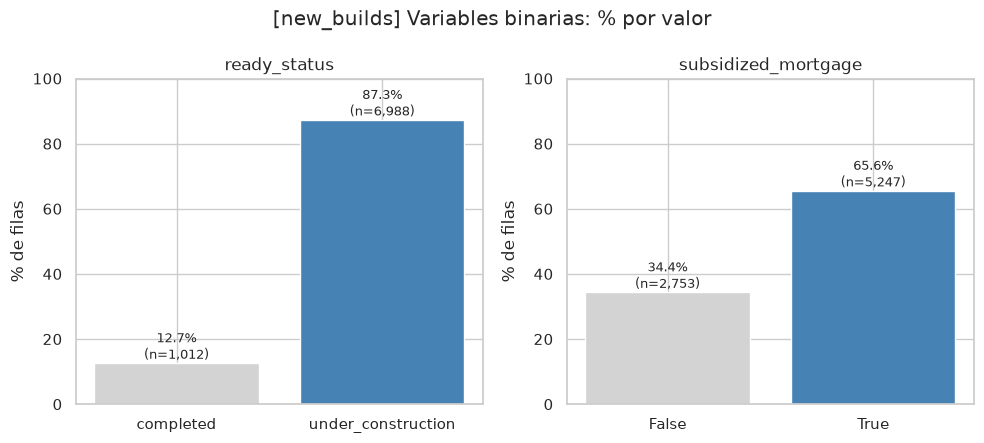

n      %
variable            valor                          
ready_status        completed           1012  12.65
                    under_construction  6988  87.35
subsidized_mortgage False               2753  34.41
                    True                5247  65.59

In [7]:
# --- new_builds: solo variables propias (price_per_sqm queda para comparar con ventas) ---
eda_univariado(
    nb, "new_builds",
    num_cont=["price_per_sqm"],
    num_disc=["completion_year"],
    cat_nom=["complex_class", "developer", "deal_type"],
    bin_cols=["ready_status", "subsidized_mortgage"])

### district_prices_monthly


district_prices_monthly: 9,804 filas × 13 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,únicos
year_month,str,0,0.00,76
district,str,0,0.00,129
okrug,str,0,0.00,11
secondary_price_per_sqm,int64,0,0.00,3886
newbuild_price_per_sqm,int64,0,0.00,4088
rental_price_per_sqm_monthly,int64,0,0.00,2154
secondary_mom_change_pct,float64,129,1.32,1737
newbuild_mom_change_pct,float64,129,1.32,2259
n_listings_secondary,int64,0,0.00,180
n_listings_newbuild,int64,0,0.00,75


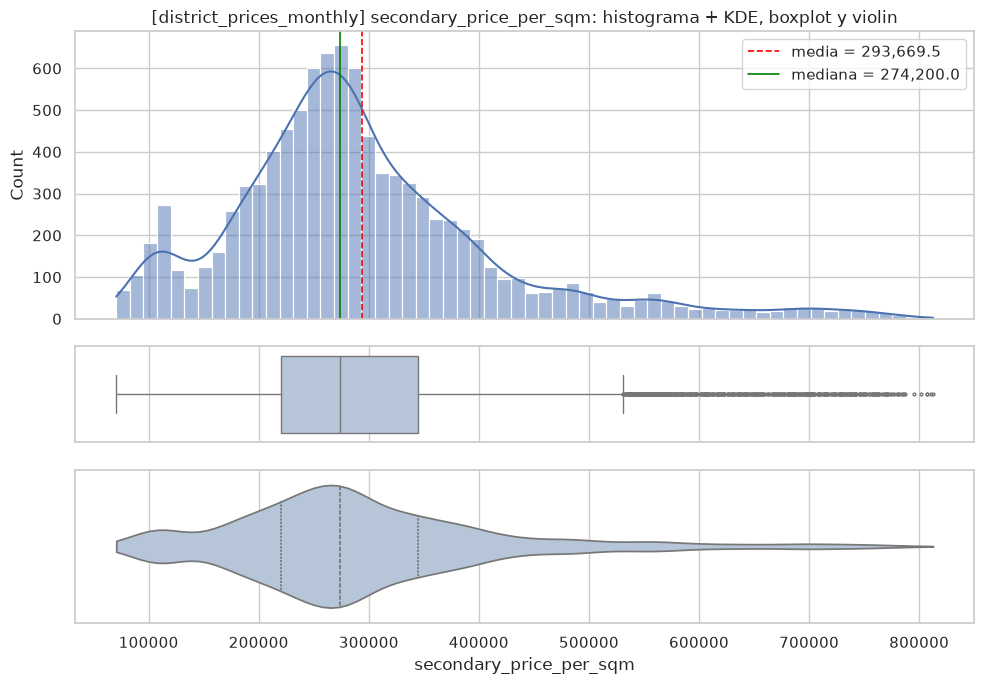

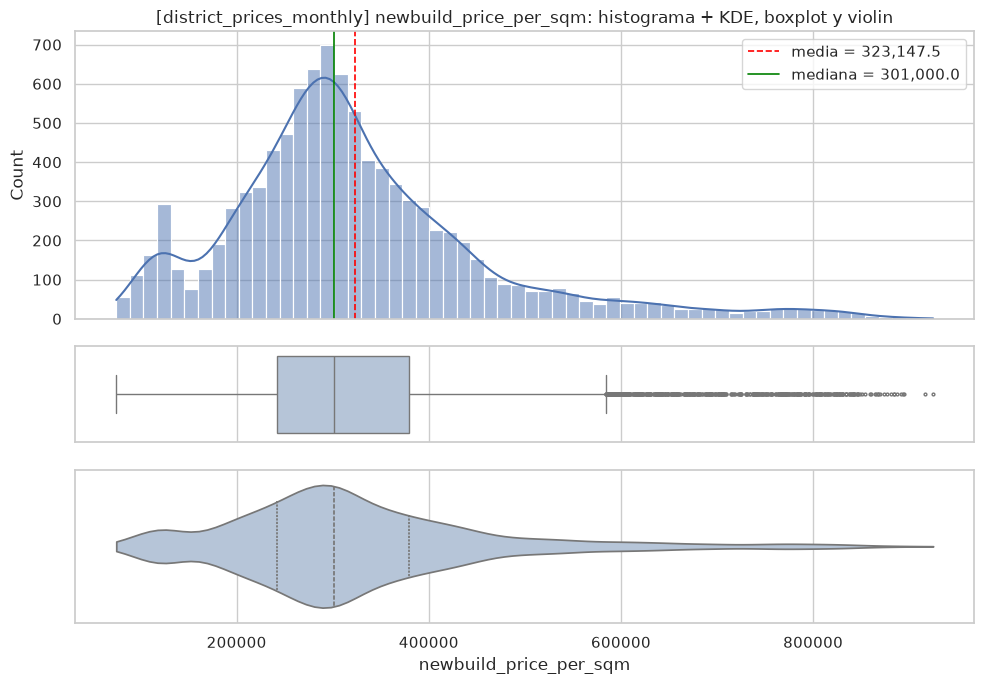

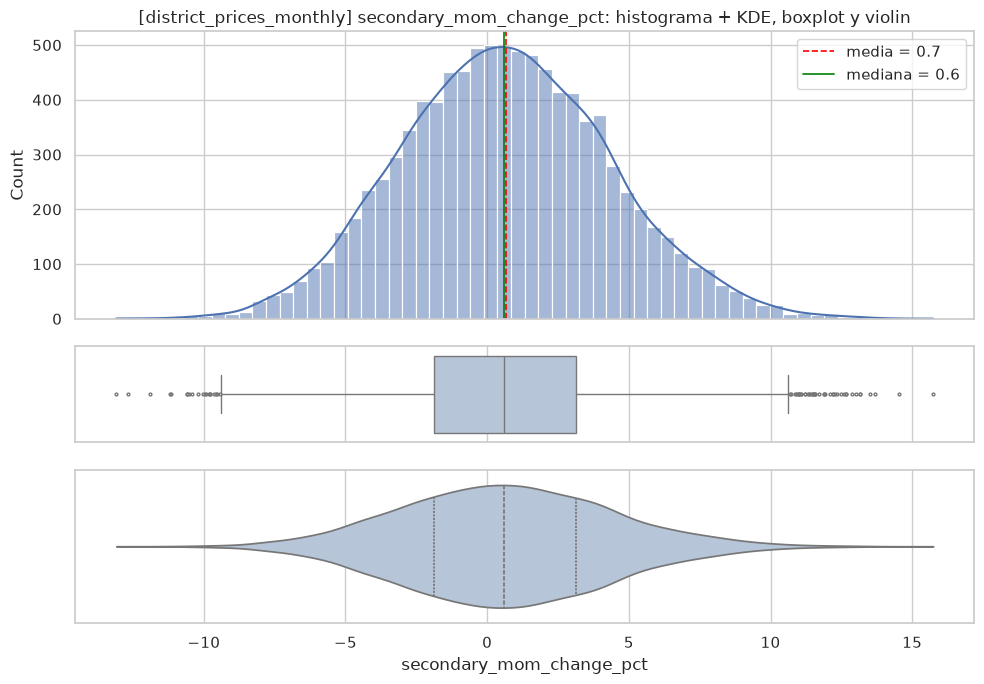

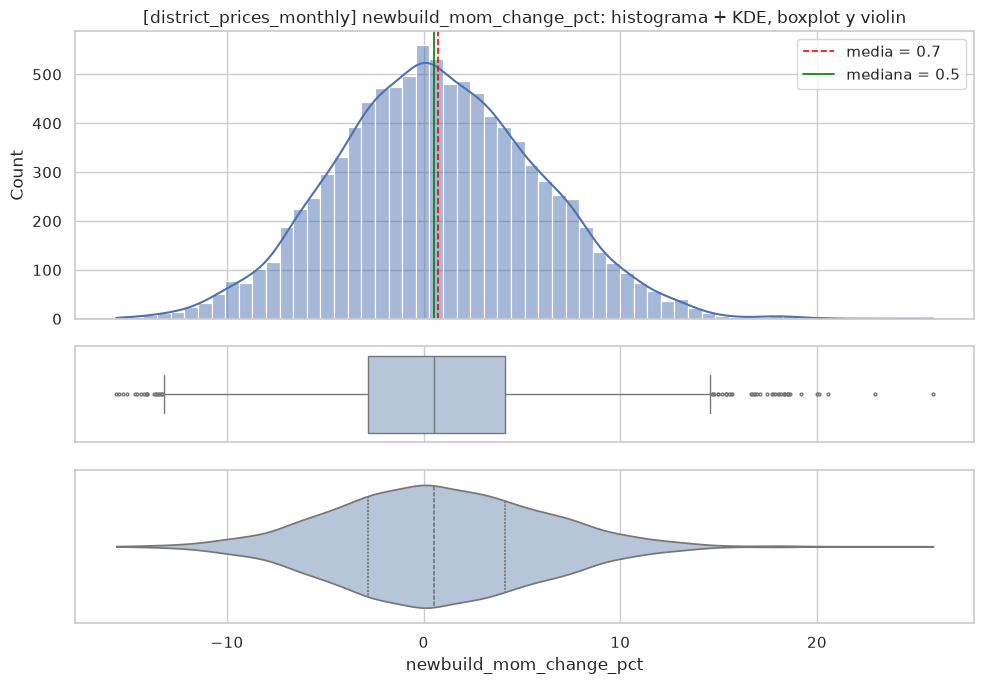

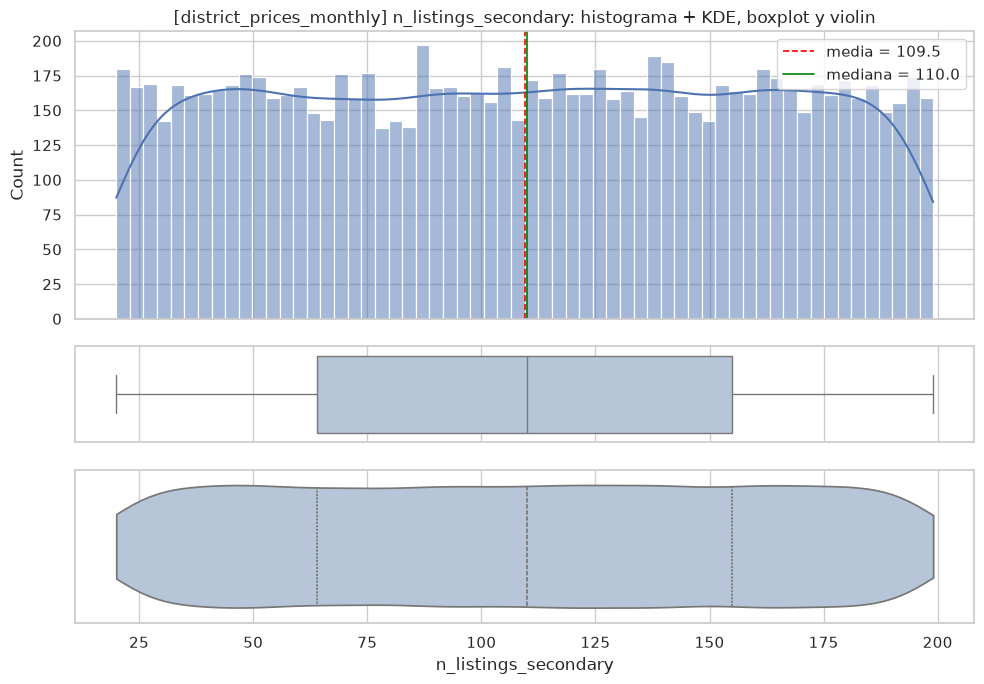

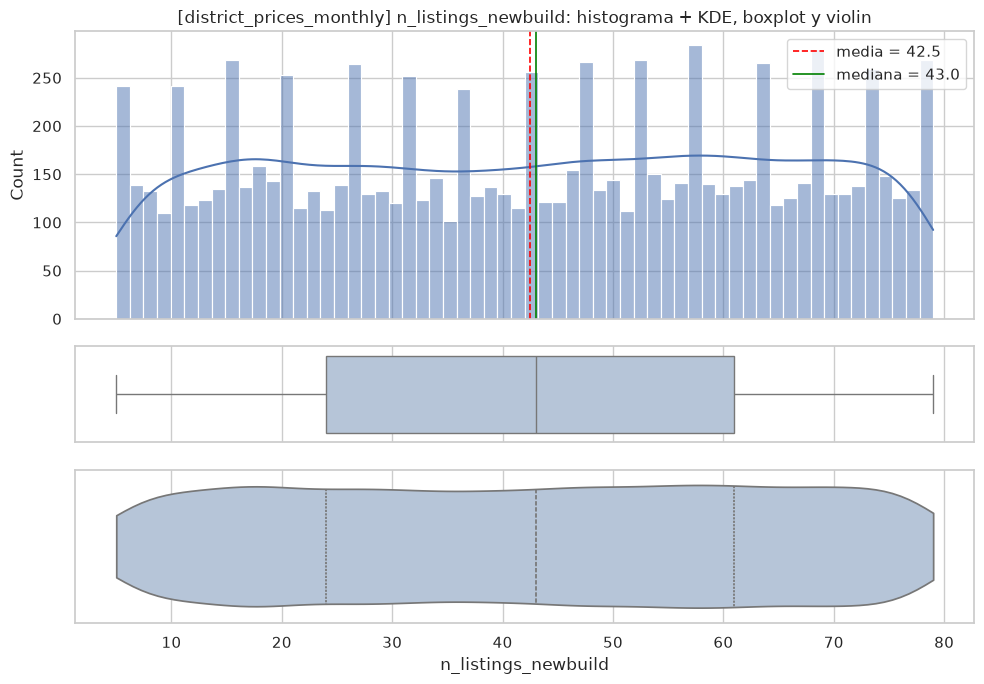

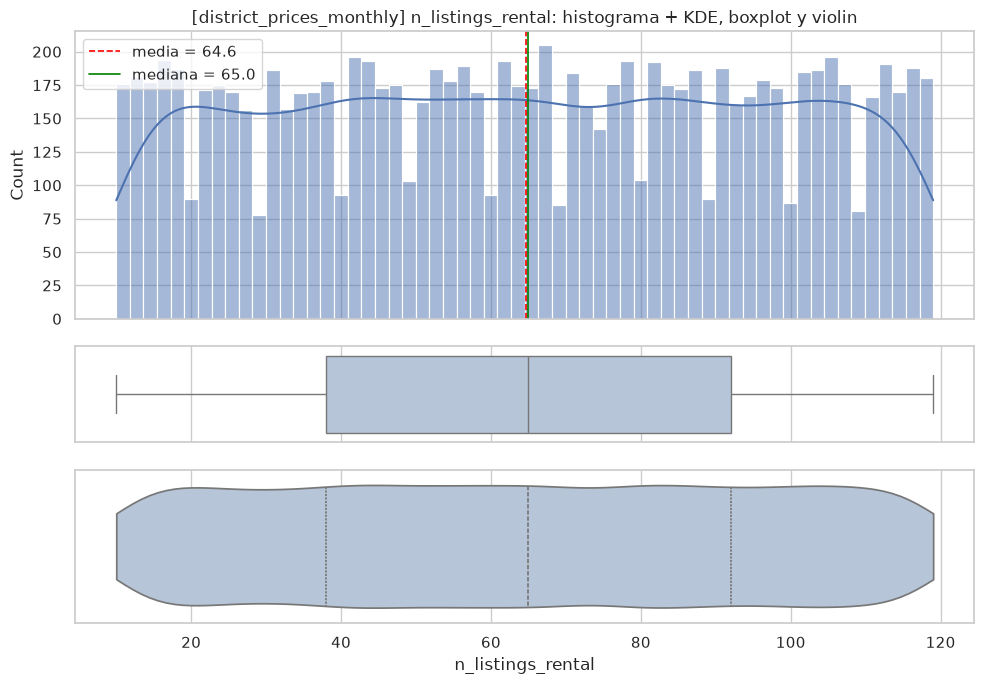

[district_prices_monthly] Numéricas continuas: estadísticos y outliers por IQR


,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
secondary_price_per_sqm,9804,293669.543,123593.450,70600.00,220400.00,274200.00,344600.00,812700.00,1.217,2.269,124200.00,34100.000,530900.000,553,5.641
newbuild_price_per_sqm,9804,323147.460,136415.279,74700.00,242375.00,301000.00,379000.00,924900.00,1.227,2.319,136625.00,37437.500,583937.500,555,5.661
secondary_mom_change_pct,9675,0.654,3.693,-13.09,-1.89,0.60,3.13,15.74,0.115,0.002,5.02,-9.420,10.660,62,0.641
newbuild_mom_change_pct,9675,0.713,5.150,-15.63,-2.82,0.52,4.15,25.91,0.135,0.042,6.97,-13.275,14.605,57,0.589
n_listings_secondary,9804,109.478,52.001,20.00,64.00,110.00,155.00,199.00,-0.009,-1.200,91.00,-72.500,291.500,0,0.000
n_listings_newbuild,9804,42.461,21.656,5.00,24.00,43.00,61.00,79.00,-0.029,-1.210,37.00,-31.500,116.500,0,0.000
n_listings_rental,9804,64.639,31.758,10.00,38.00,65.00,92.00,119.00,-0.006,-1.192,54.00,-43.000,173.000,0,0.000


In [8]:
# --- district_prices_monthly: sin las tasas ni okrug (redundantes con ventas) ---
eda_univariado(
    dpm, "district_prices_monthly",
    num_cont=["secondary_price_per_sqm", "newbuild_price_per_sqm",
              "secondary_mom_change_pct", "newbuild_mom_change_pct",
              "n_listings_secondary", "n_listings_newbuild", "n_listings_rental"])

### metro_stations


metro_stations: 104 filas × 6 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,únicos
station_name,str,0,0.0,104
line,str,0,0.0,12
lat,float64,0,0.0,98
lon,float64,0,0.0,98
year_opened,int64,0,0.0,44
to_center_km,float64,0,0.0,103


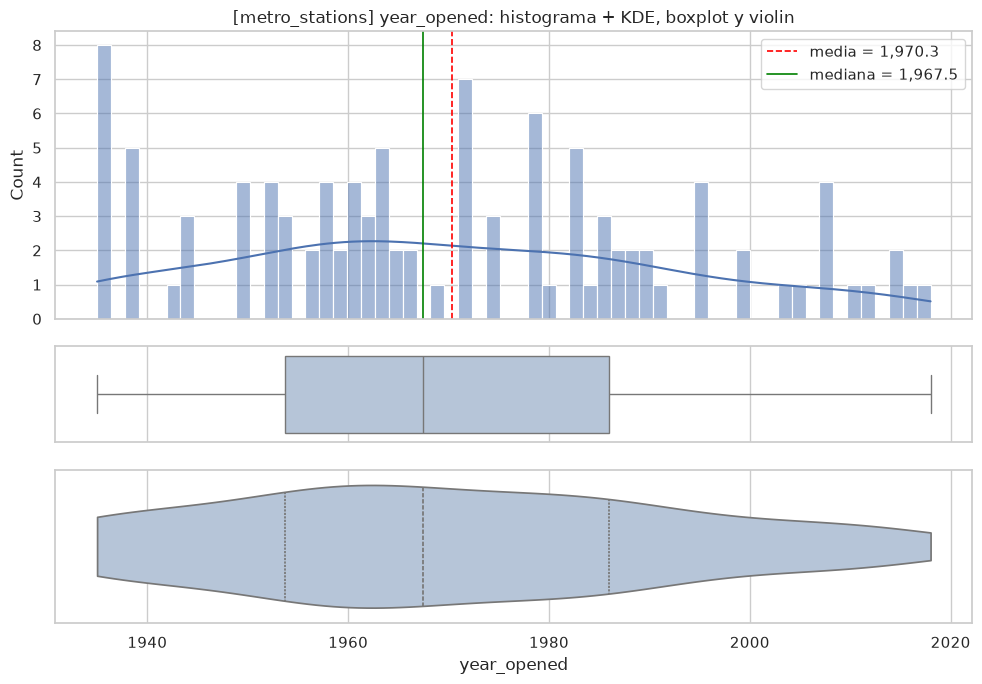

[metro_stations] Numéricas continuas: estadísticos y outliers por IQR


,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
year_opened,104,1970.317,22.487,1935,1953.75,1967.5,1986.0,2018,0.244,-0.747,32.25,1905.375,2034.375,0,0.0


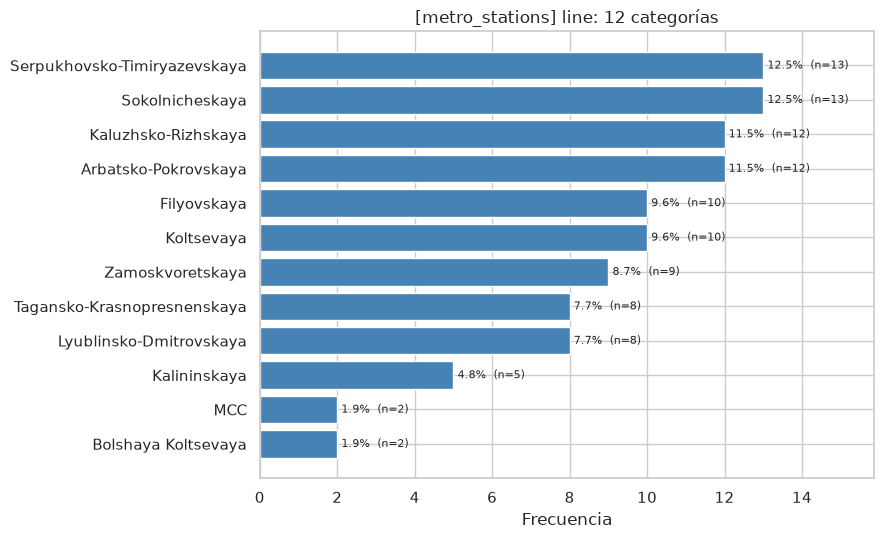

[metro_stations] Categóricas nominales


,n_categorias,moda,moda_%,top3_%acum,menos_frecuente,menos_frecuente_%
line,12,Serpukhovsko-Timiryazevskaya,12.5,36.54,Bolshaya Koltsevaya,1.92


In [9]:
# --- metro_stations ---
eda_univariado(ms, "metro_stations", num_cont=["year_opened"], cat_nom=["line"])

### rentals (solo contexto)


rentals: 20,000 filas × 22 columnas | filas duplicadas: 0


,tipo,nulos,%_nulos,únicos
id,str,0,0.0,20000
date_posted,str,0,0.0,1945
district,str,0,0.0,129
okrug,str,0,0.0,11
lat,float64,0,0.0,15985
lon,float64,0,0.0,16678
total_area,float64,0,0.0,695
rooms,int64,0,0.0,4
floor,int64,0,0.0,22
total_floors,int64,0,0.0,5


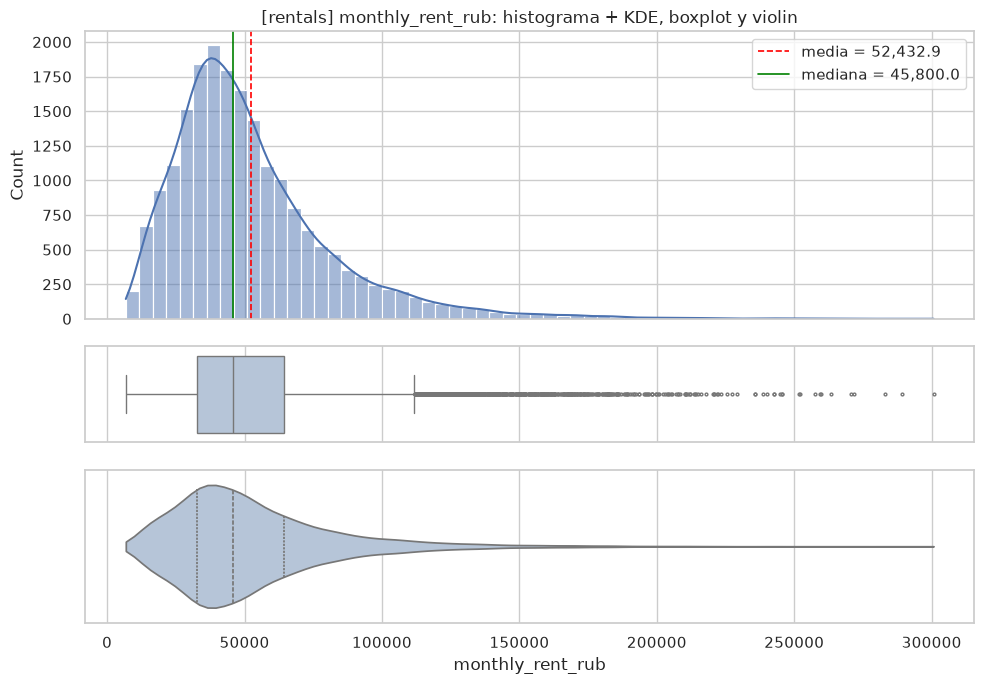

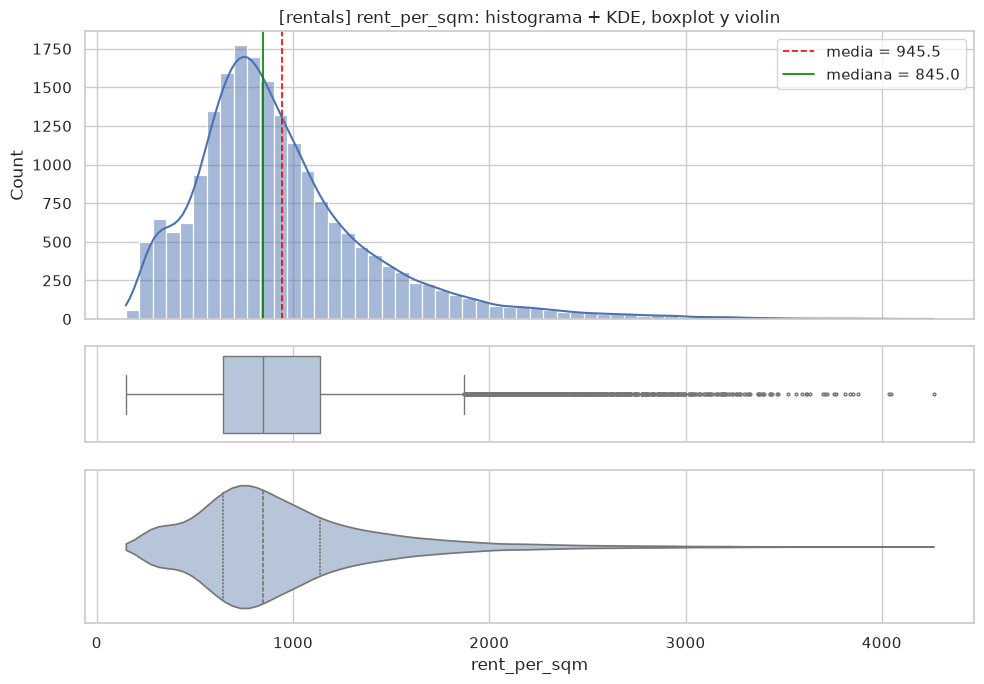

[rentals] Numéricas continuas: estadísticos y outliers por IQR


,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
monthly_rent_rub,20000,52432.855,30003.240,6800,32800.0,45800.0,64400.0,300700,1.820,5.565,31600.0,-14600.0,111800.0,936,4.680
rent_per_sqm,20000,945.461,480.537,148,644.0,845.0,1135.0,4264,1.593,4.020,491.0,-92.5,1871.5,1001,5.005


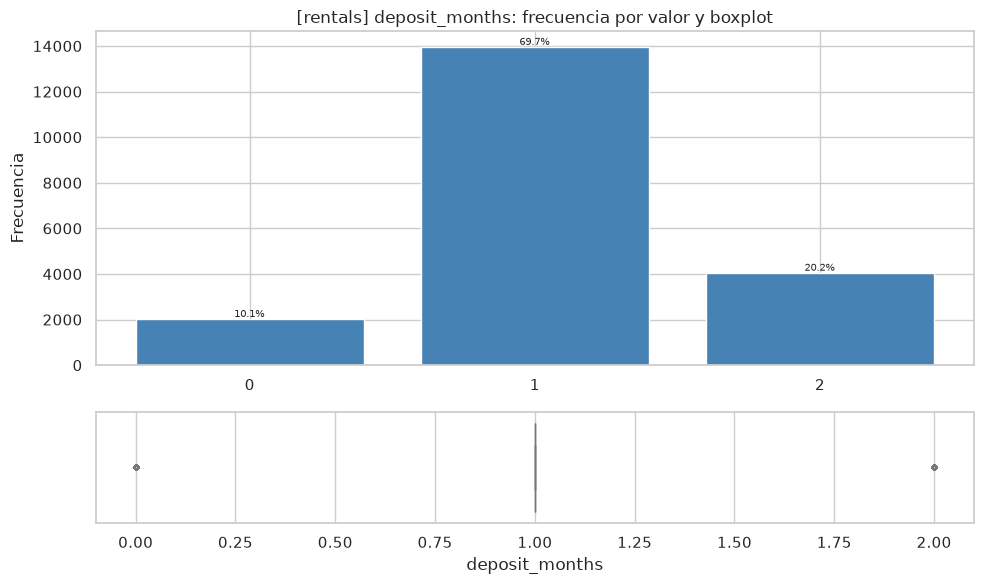

[rentals] Numéricas discretas: estadísticos y outliers por IQR


,n_valores,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
deposit_months,3,20000,1.101,0.541,0,1.0,1.0,1.0,2,0.072,0.275,0.0,1.0,1.0,6053,30.265


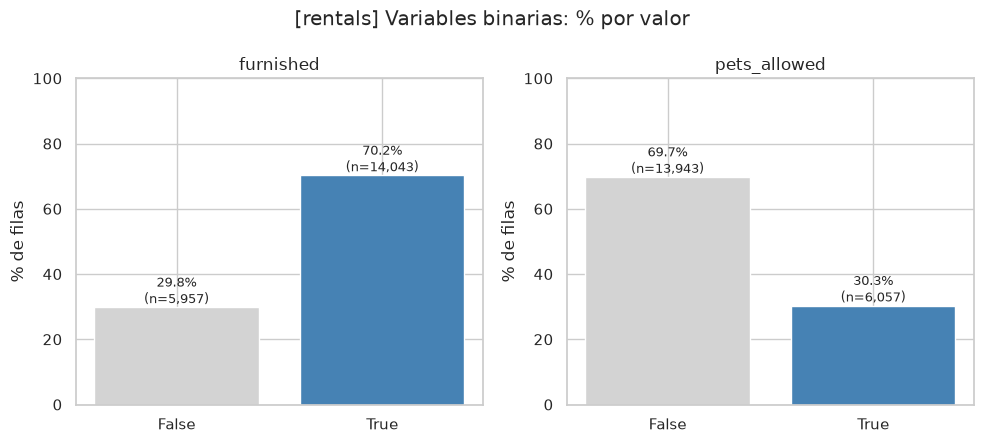

n      %
variable     valor              
furnished    False   5957  29.78
             True   14043  70.22
pets_allowed False  13943  69.72
             True    6057  30.28

In [10]:
# --- rentals: solo variables propias ---
eda_univariado(rn, "rentals", num_cont=["monthly_rent_rub", "rent_per_sqm"],
               num_disc=["deposit_months"], bin_cols=["furnished", "pets_allowed"])

### Serie temporal del panel

Solo agrega una tabla mensual para graficar; no modifica `df`.

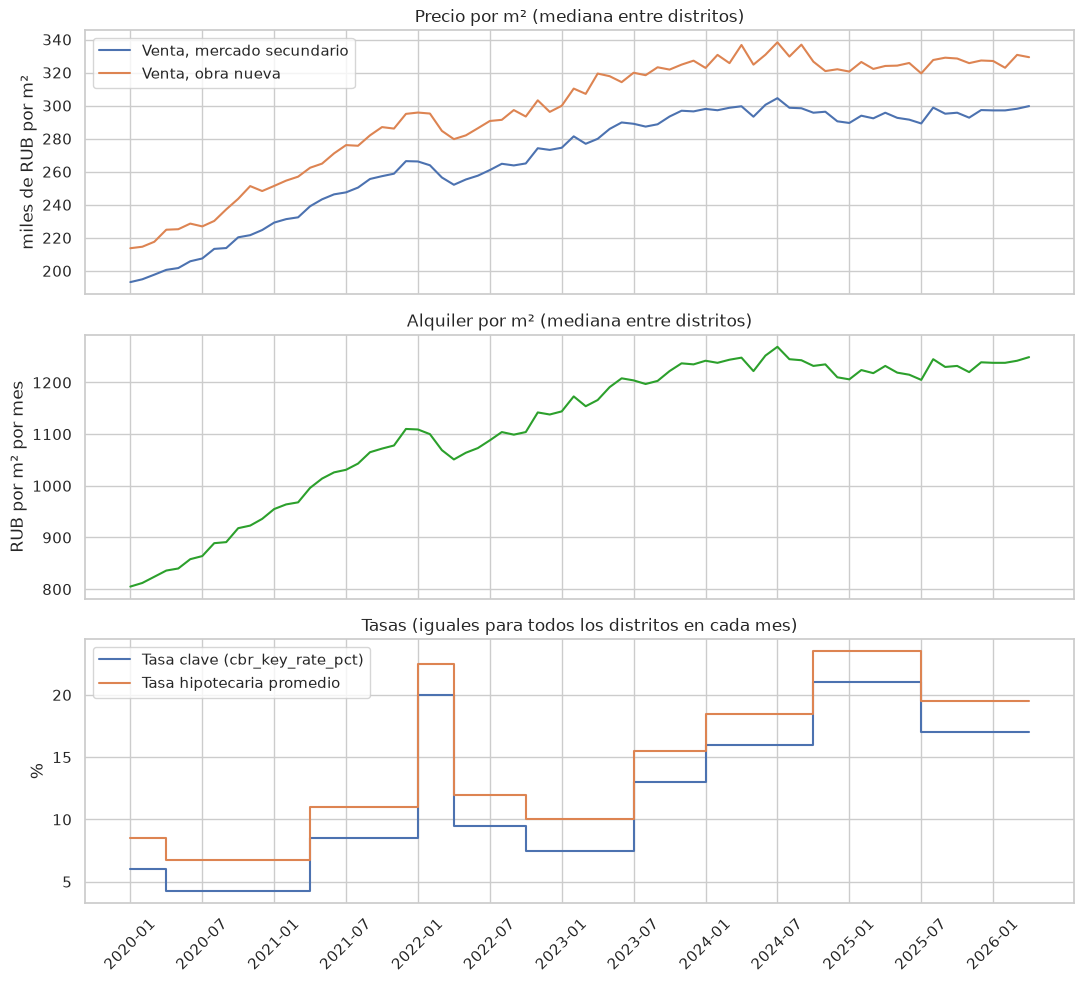

Alquiler mensual / precio de venta por m²: media = 0.00417 (x12 = 0.050 al año), desvío = 0.000001
Correlación entre series (a nivel distrito-mes):


,secondary_price_per_sqm,newbuild_price_per_sqm,rental_price_per_sqm_monthly
secondary_price_per_sqm,1.0000,0.9979,1.0000
newbuild_price_per_sqm,0.9979,1.0000,0.9979
rental_price_per_sqm_monthly,1.0000,0.9979,1.0000


In [11]:
# Serie temporal del panel (mediana entre distritos de cada mes). Solo para graficar: no toca df.
mensual = (dpm.groupby("year_month")
              .agg(venta=("secondary_price_per_sqm", "median"),
                   obra_nueva=("newbuild_price_per_sqm", "median"),
                   alquiler=("rental_price_per_sqm_monthly", "median"),
                   tasa_cbr=("cbr_key_rate_pct", "first"),
                   tasa_hipoteca=("avg_mortgage_rate_pct", "first"))
              .reset_index())
x = np.arange(len(mensual))
ticks = x[::6]

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
axes[0].plot(x, mensual["venta"] / 1e3, label="Venta, mercado secundario")
axes[0].plot(x, mensual["obra_nueva"] / 1e3, label="Venta, obra nueva")
axes[0].set(ylabel="miles de RUB por m²", title="Precio por m² (mediana entre distritos)")
axes[0].legend()
axes[1].plot(x, mensual["alquiler"], color="tab:green")
axes[1].set(ylabel="RUB por m² por mes", title="Alquiler por m² (mediana entre distritos)")
axes[2].step(x, mensual["tasa_cbr"], where="post", label="Tasa clave (cbr_key_rate_pct)")
axes[2].step(x, mensual["tasa_hipoteca"], where="post", label="Tasa hipotecaria promedio")
axes[2].set(ylabel="%", title="Tasas (iguales para todos los distritos en cada mes)")
axes[2].legend()
axes[2].set_xticks(ticks)
axes[2].set_xticklabels(mensual["year_month"].iloc[ticks], rotation=45)
plt.tight_layout()
plt.show()

# Chequeo de redundancia entre las series del panel
ratio = dpm["rental_price_per_sqm_monthly"] / dpm["secondary_price_per_sqm"]
print(f"Alquiler mensual / precio de venta por m²: media = {ratio.mean():.5f} "
      f"(x12 = {12 * ratio.mean():.3f} al año), desvío = {ratio.std():.6f}")
print("Correlación entre series (a nivel distrito-mes):")
show(dpm[["secondary_price_per_sqm", "newbuild_price_per_sqm", "rental_price_per_sqm_monthly"]].corr(), dec=4)

## 2. EDA univariado (secondary_market, todos los anuncios)

### EDA-2: numéricas continuas

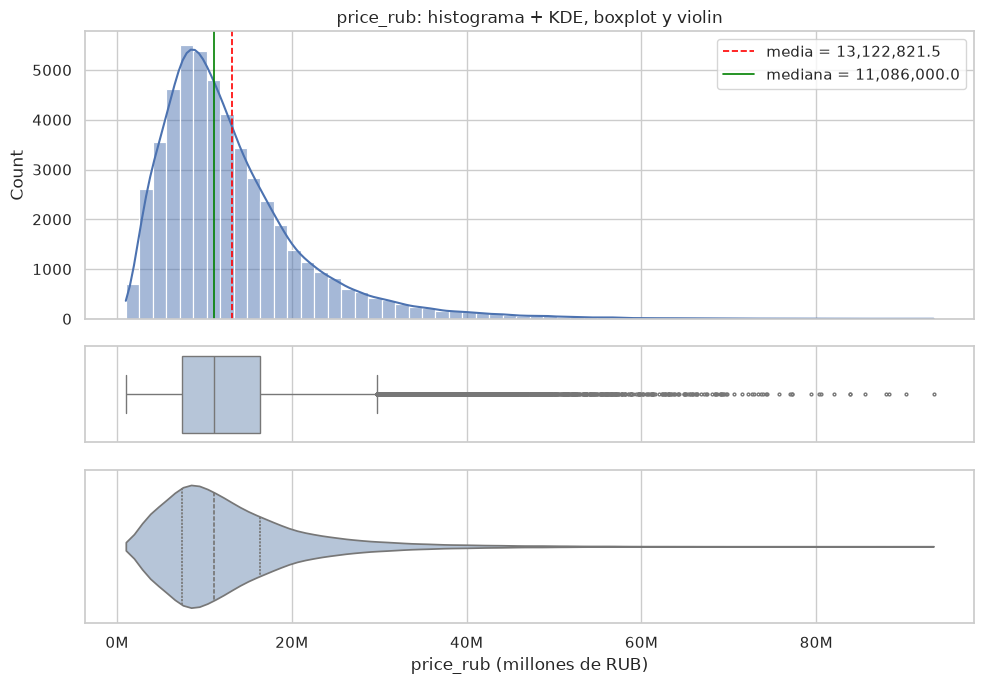

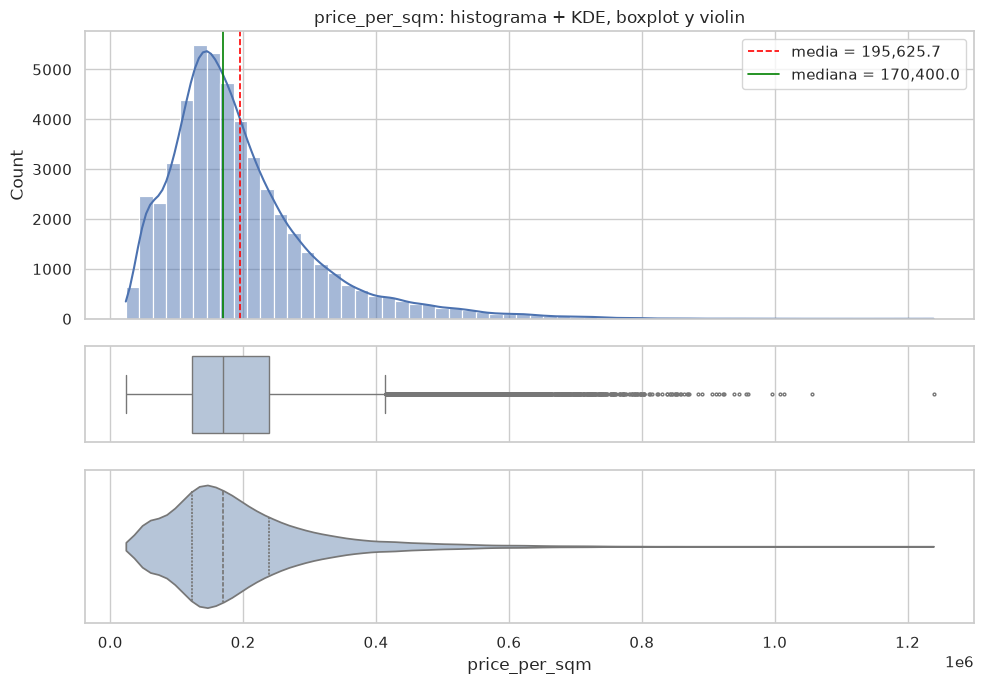

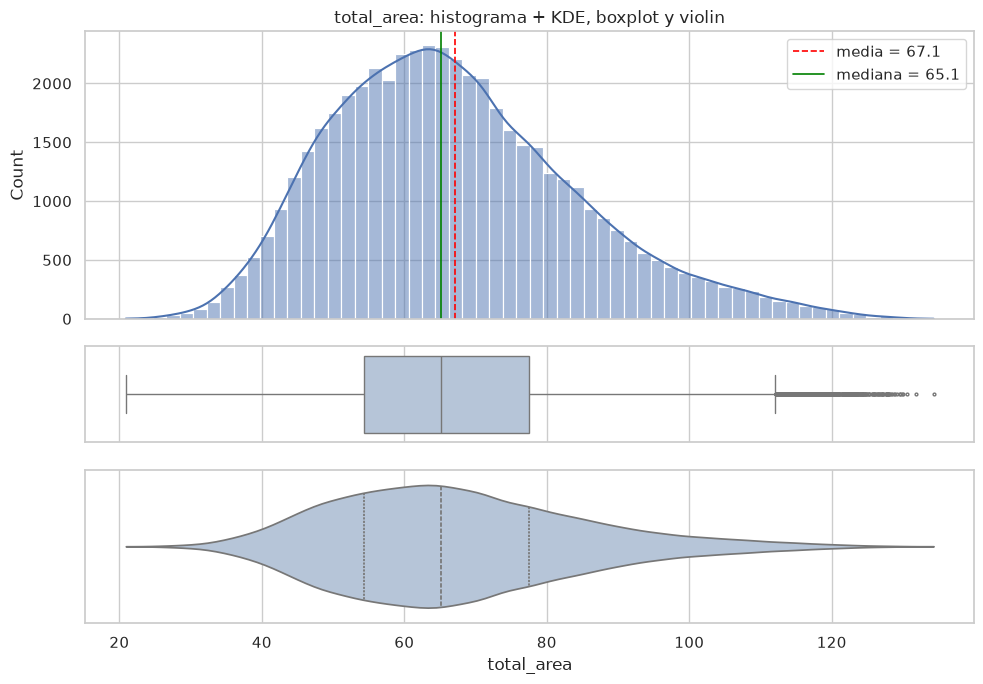

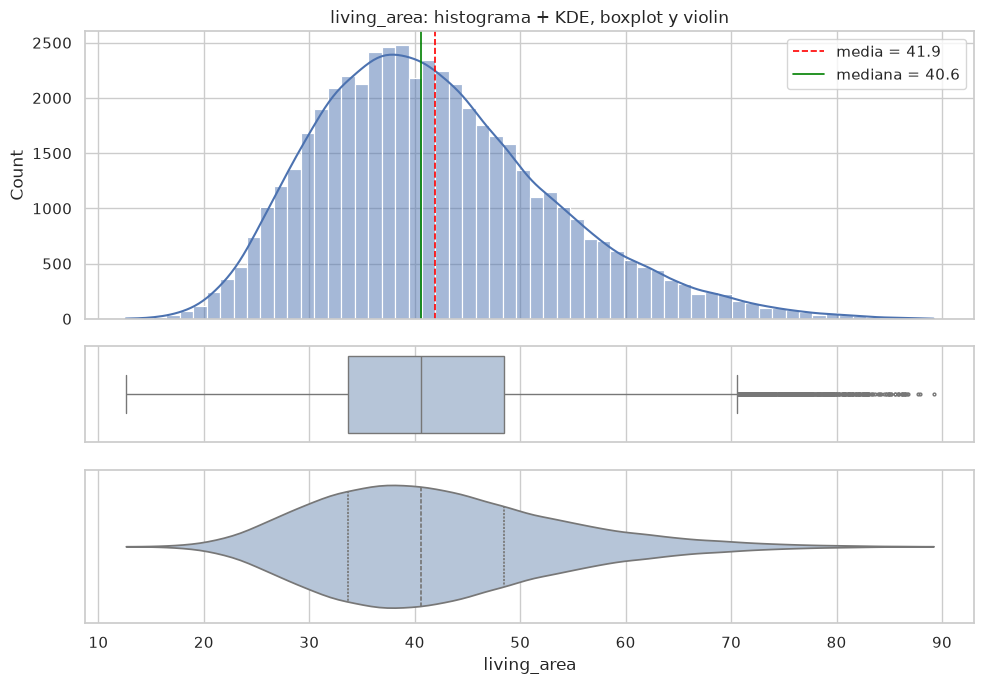

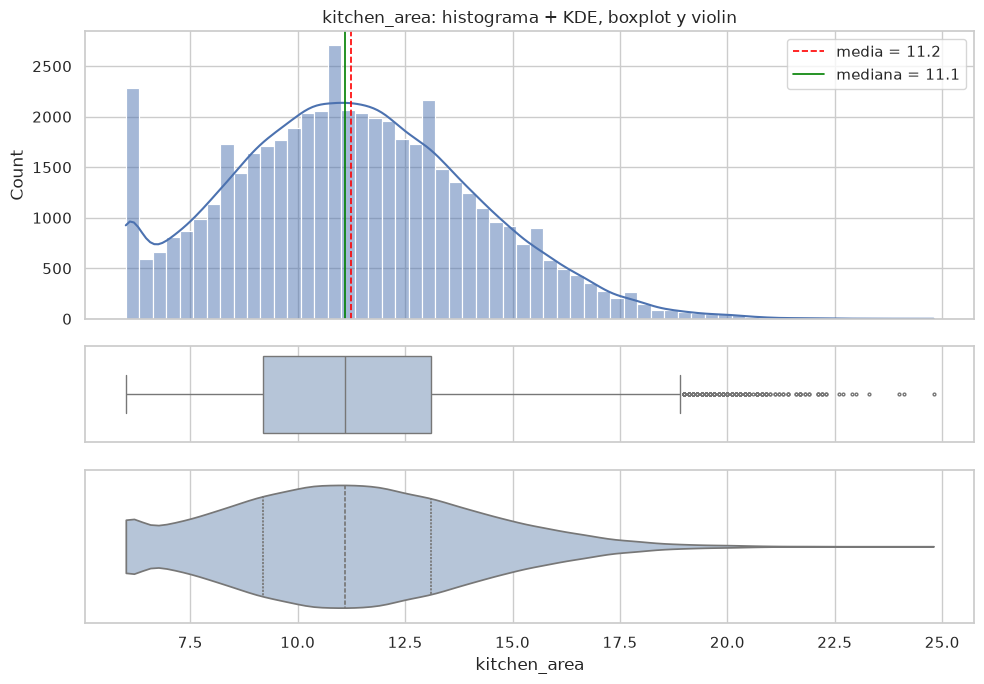

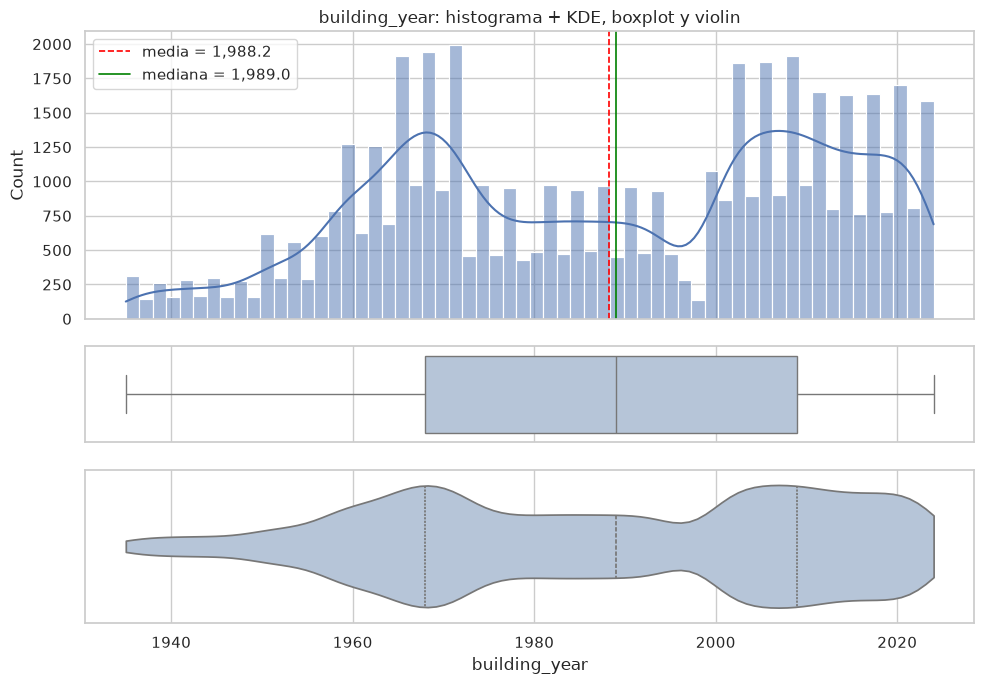

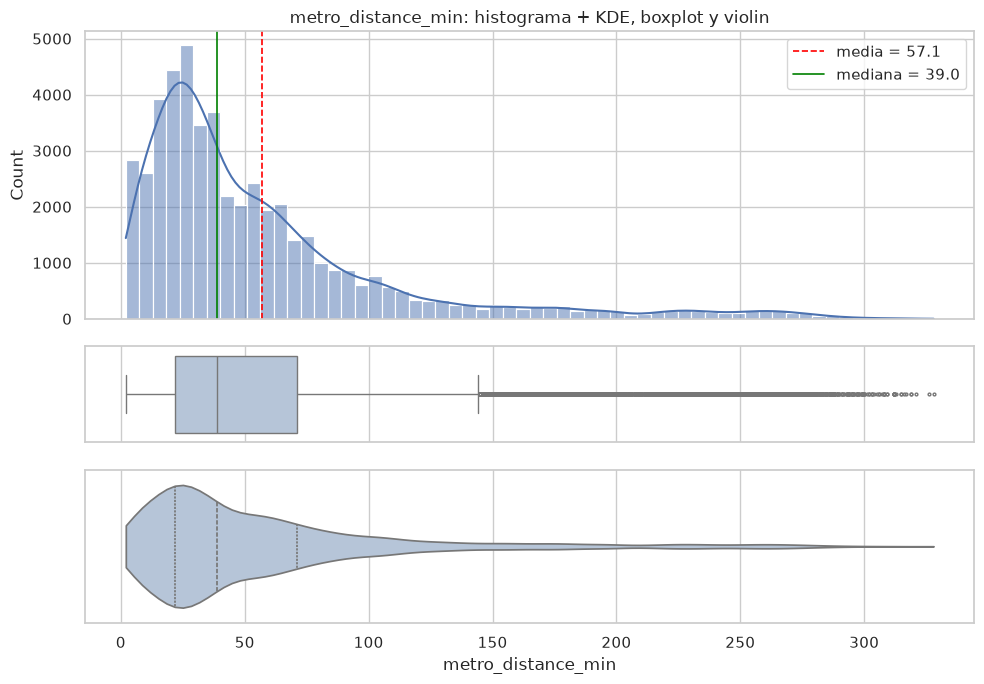

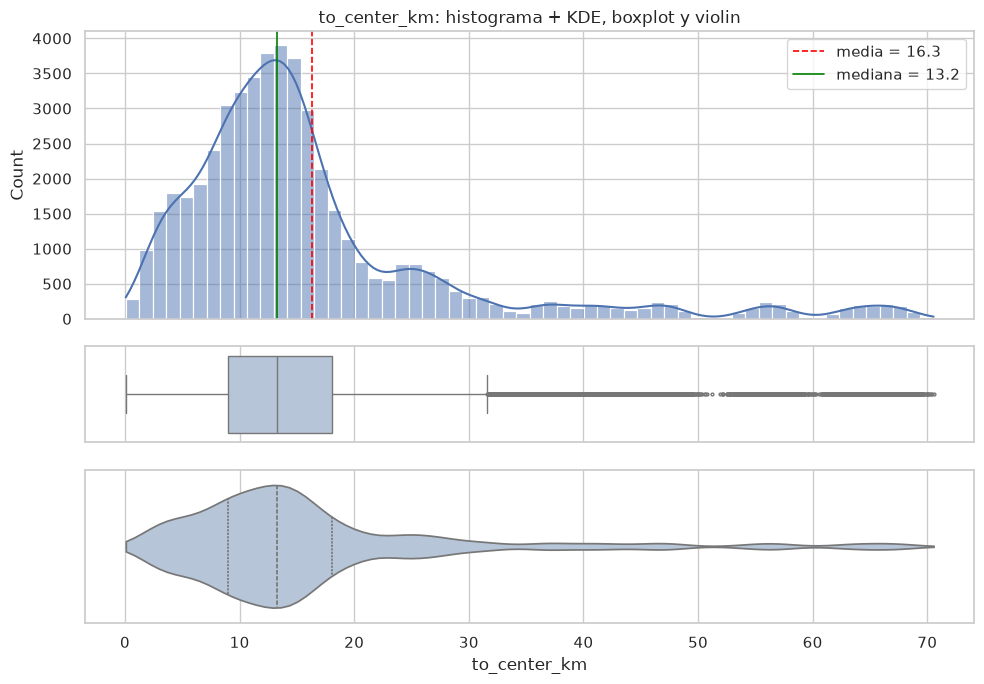

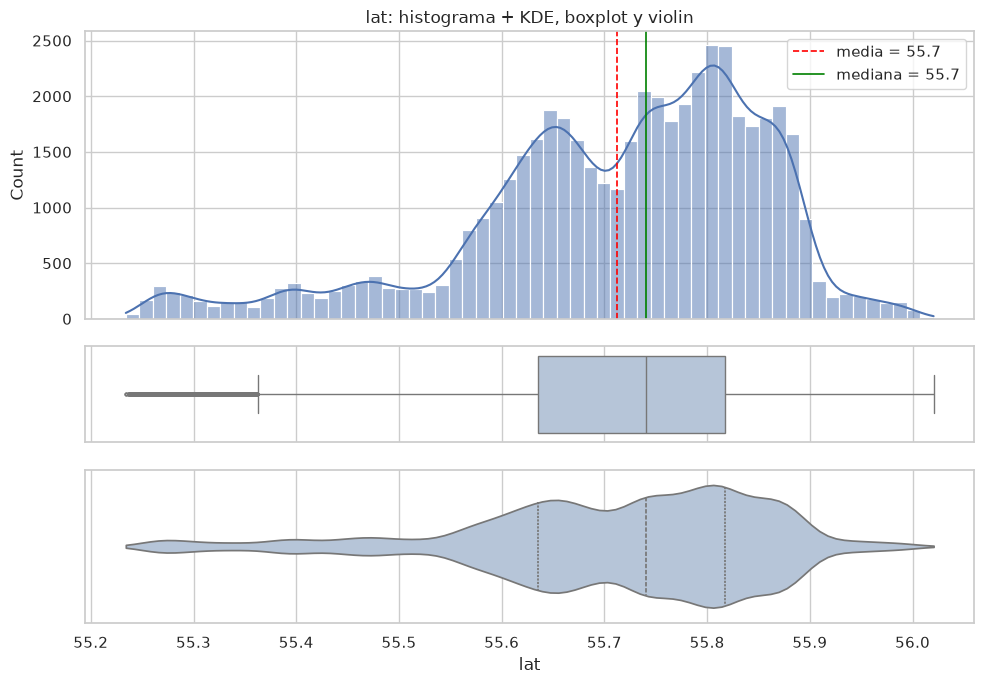

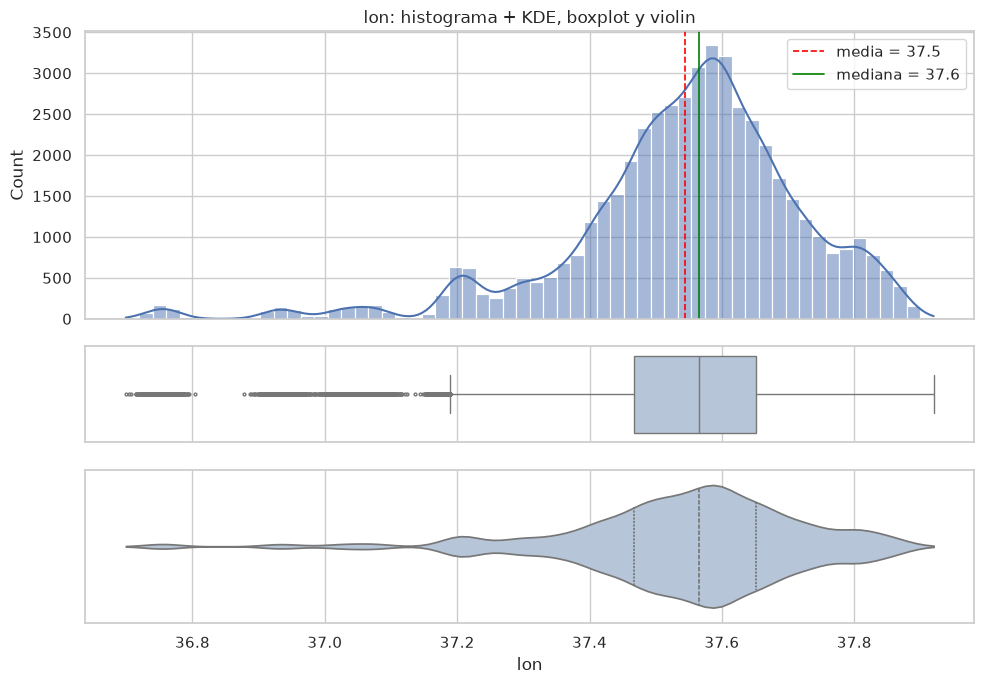

Estadísticos y outliers por IQR (límites = Q1 - 1.5·IQR y Q3 + 1.5·IQR)


,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
price_rub,50000,1.312282e+07,8564072.983,1019000.000,7481750.000,1.108600e+07,1.638725e+07,93437000.00,1.997,6.558,8905500.000,-5876500.000,2.974550e+07,2459,4.918
price_per_sqm,50000,1.956257e+05,113270.873,23400.000,123000.000,1.704000e+05,2.395000e+05,1239100.00,1.687,4.315,116500.000,-51750.000,4.142500e+05,2696,5.392
total_area,50000,6.705300e+01,17.310,20.900,54.400,6.510000e+01,7.750000e+01,134.30,0.582,0.168,23.100,19.750,1.121500e+02,687,1.374
living_area,50000,4.188400e+01,11.209,12.600,33.700,4.060000e+01,4.850000e+01,89.20,0.638,0.332,14.800,11.500,7.070000e+01,767,1.534
kitchen_area,50000,1.124500e+01,2.856,6.000,9.200,1.110000e+01,1.310000e+01,24.80,0.273,-0.173,3.900,3.350,1.895000e+01,287,0.574
building_year,50000,1.988220e+03,23.571,1935.000,1968.000,1.989000e+03,2.009000e+03,2024.00,-0.204,-1.156,41.000,1906.500,2.070500e+03,0,0.000
metro_distance_min,50000,5.706400e+01,54.483,2.000,22.000,3.900000e+01,7.100000e+01,328.00,2.038,4.384,49.000,-51.500,1.445000e+02,3893,7.786
to_center_km,50000,1.632600e+01,12.738,0.070,9.028,1.323000e+01,1.806000e+01,70.55,2.115,4.832,9.032,-4.521,3.160900e+01,4672,9.344
lat,50000,5.571300e+01,0.144,55.234,55.635,5.574000e+01,5.581700e+01,56.02,-0.961,0.873,0.182,55.362,5.609100e+01,1632,3.264
lon,50000,3.754400e+01,0.180,36.699,37.467,3.756600e+01,3.765200e+01,37.92,-1.231,3.055,0.185,37.190,3.792900e+01,1906,3.812


In [12]:
rows = {}
for col in NUM_CONT:
    s = eda[col]
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1, 1.6]})
    sns.histplot(s, bins=60, kde=True, ax=axes[0])
    axes[0].axvline(s.mean(), color="red", ls="--", lw=1.2, label=f"media = {s.mean():,.1f}")
    axes[0].axvline(s.median(), color="green", ls="-", lw=1.2, label=f"mediana = {s.median():,.1f}")
    axes[0].legend()
    axes[0].set_title(f"{col}: histograma + KDE, boxplot y violin")
    sns.boxplot(x=s, ax=axes[1], fliersize=2, color="lightsteelblue")
    sns.violinplot(x=s, ax=axes[2], cut=0, inner="quartile", color="lightsteelblue")
    axes[1].set_xlabel("")
    if col == "price_rub":
        millions(axes[2], "x")
        axes[2].set_xlabel("price_rub (millones de RUB)")
    plt.tight_layout()
    plt.show()
    rows[col] = iqr_stats(s)

print("Estadísticos y outliers por IQR (límites = Q1 - 1.5·IQR y Q3 + 1.5·IQR)")
show(pd.DataFrame.from_dict(rows, orient="index"))

### EDA-3: numéricas discretas

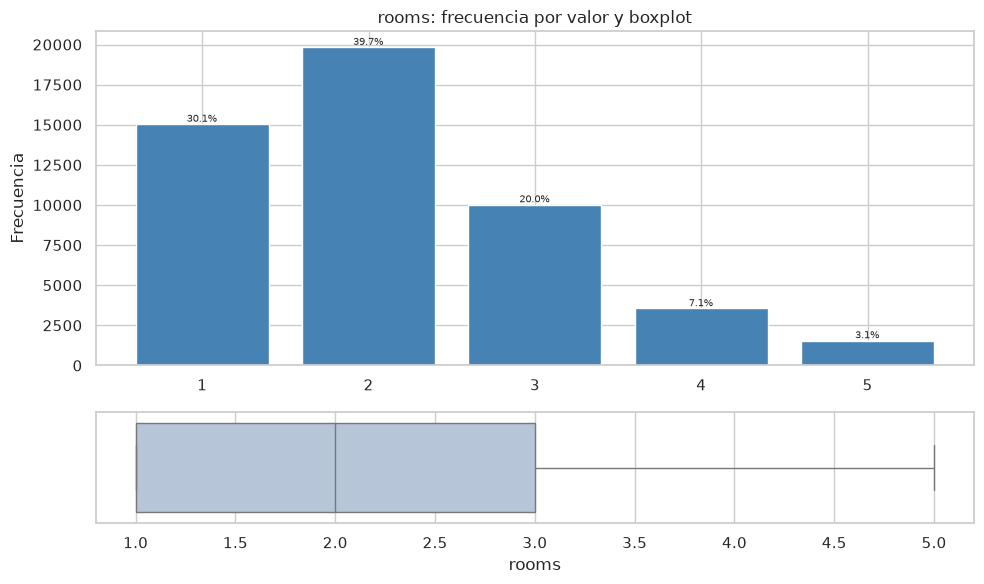

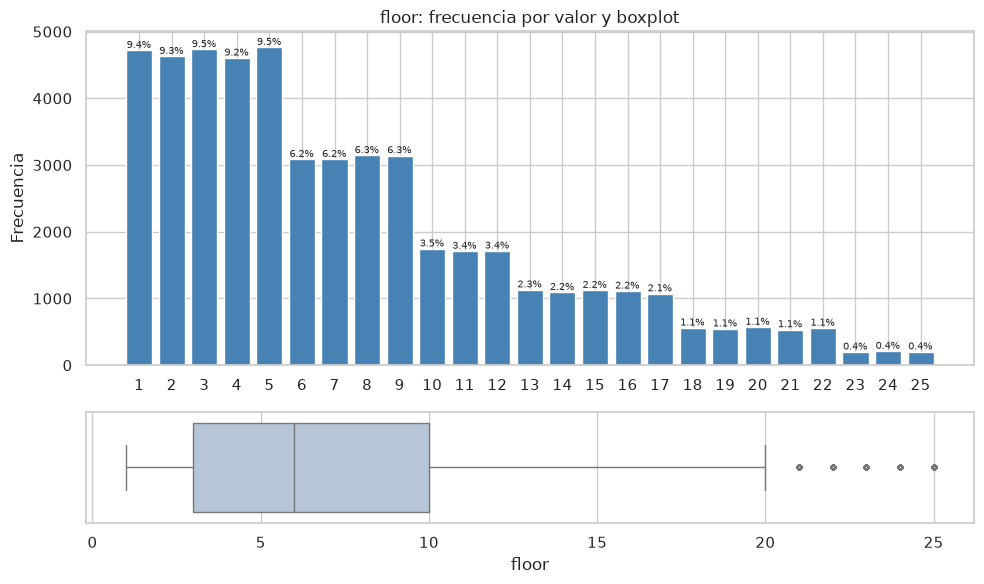

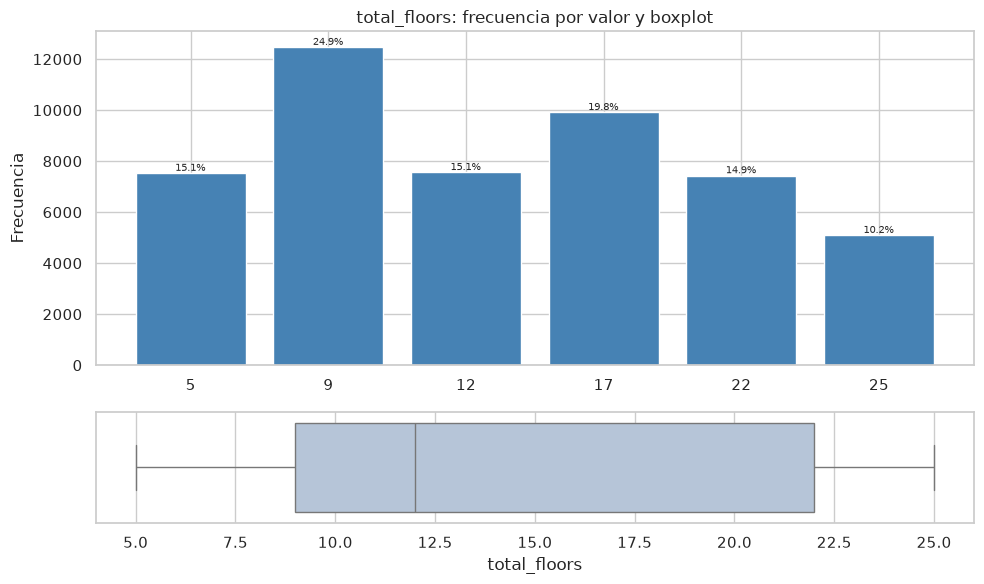

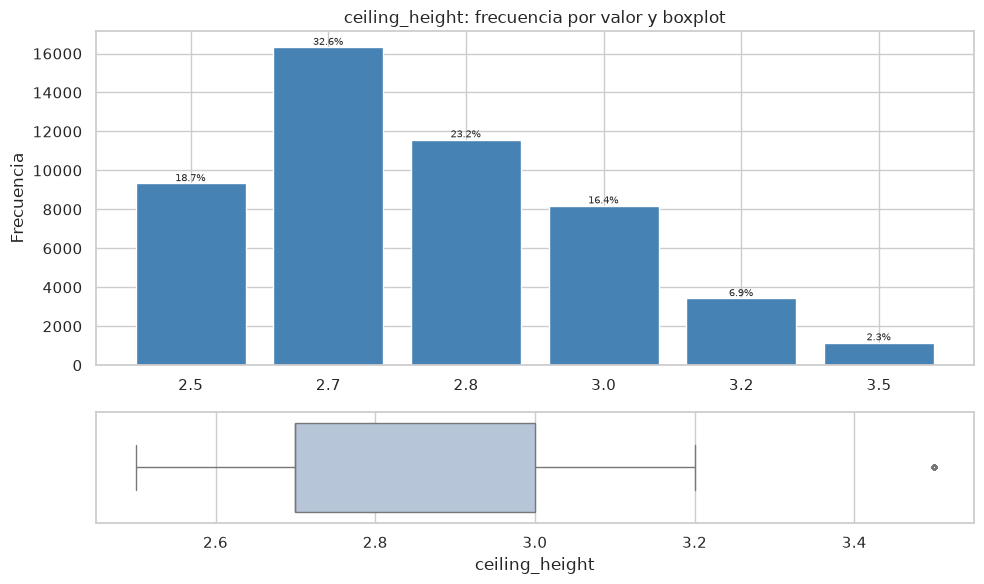

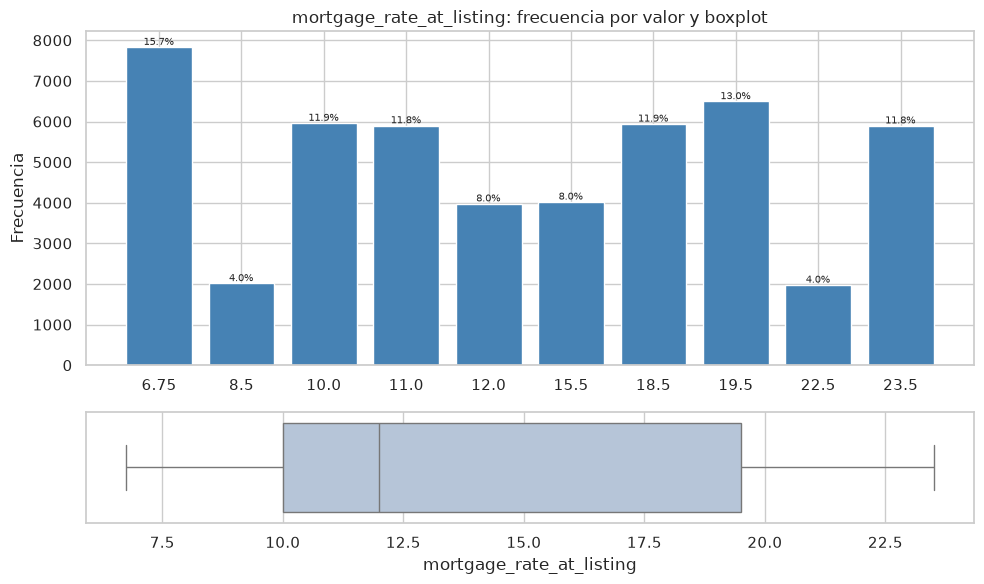

Estadísticos y outliers por IQR


,n_valores,n,media,desv,min,q1,mediana,q3,max,asimetria,curtosis,iqr,lim_inf,lim_sup,n_outliers,%_outliers
rooms,5,50000,2.135,1.023,1.00,1.0,2.0,3.0,5.0,0.822,0.253,2.0,-2.00,6.00,0,0.000
floor,25,50000,7.475,5.530,1.00,3.0,6.0,10.0,25.0,1.010,0.361,7.0,-7.50,20.50,1703,3.406
total_floors,6,50000,14.001,6.532,5.00,9.0,12.0,22.0,25.0,0.269,-1.208,13.0,-10.50,41.50,0,0.000
ceiling_height,6,50000,2.788,0.221,2.50,2.7,2.7,3.0,3.5,0.935,1.024,0.3,2.25,3.45,1158,2.316
mortgage_rate_at_listing,10,50000,14.479,5.702,6.75,10.0,12.0,19.5,23.5,0.180,-1.358,9.5,-4.25,33.75,0,0.000


In [13]:
rows = {}
for col in NUM_DISC:
    s = eda[col]
    vc = s.value_counts().sort_index()
    pct = 100 * vc / vc.sum()
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), gridspec_kw={"height_ratios": [3, 1]})
    bars = axes[0].bar(vc.index.astype(str), vc.values, color="steelblue")
    axes[0].bar_label(bars, labels=[f"{p:.1f}%" for p in pct], fontsize=7)
    axes[0].set(title=f"{col}: frecuencia por valor y boxplot", ylabel="Frecuencia")
    sns.boxplot(x=s, ax=axes[1], fliersize=3, color="lightsteelblue")
    plt.tight_layout()
    plt.show()
    rows[col] = {"n_valores": s.nunique()} | iqr_stats(s)

print("Estadísticos y outliers por IQR")
show(pd.DataFrame.from_dict(rows, orient="index"))

### EDA-4: categóricas nominales

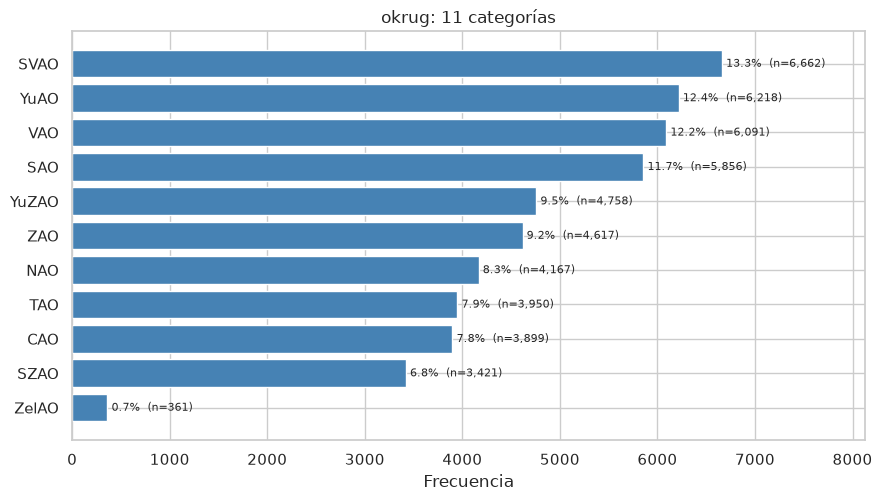

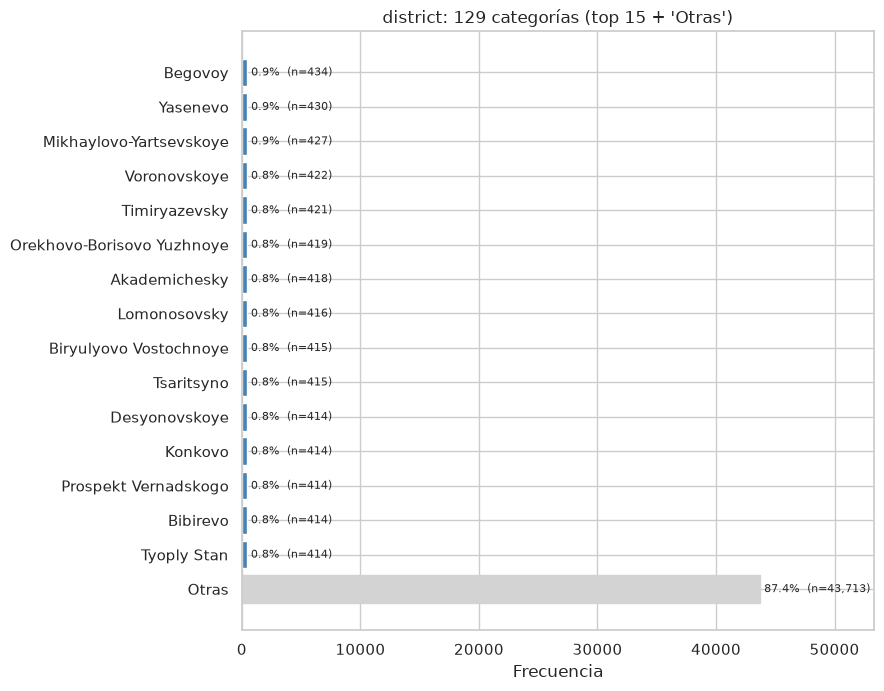

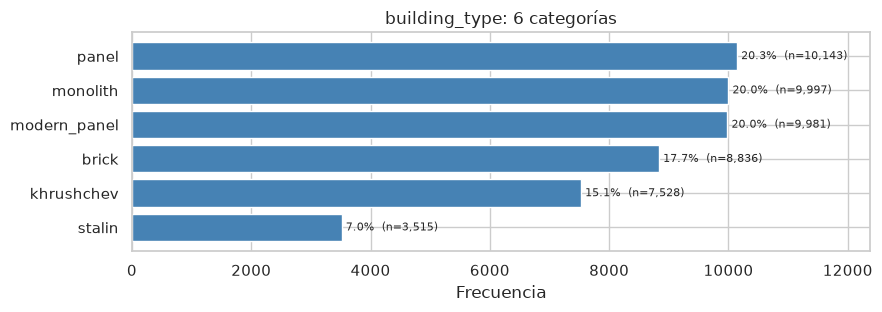

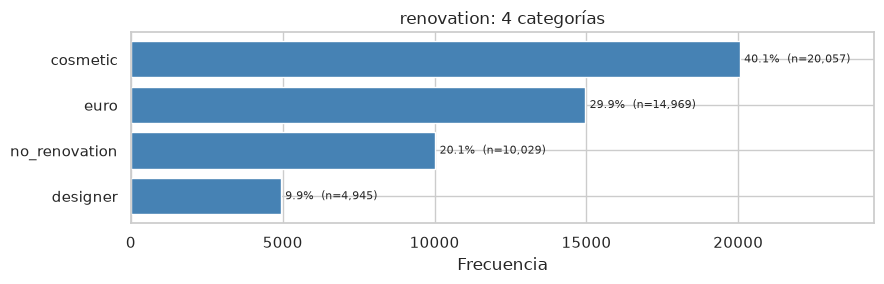

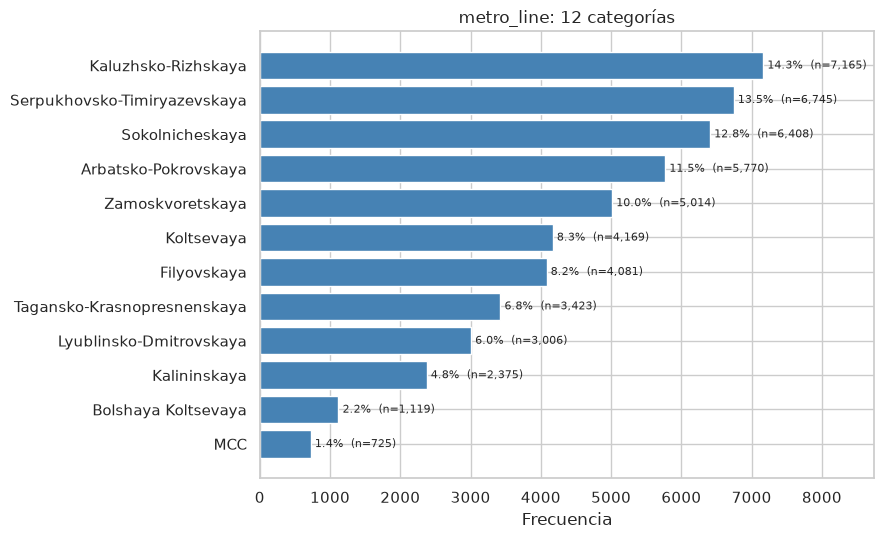

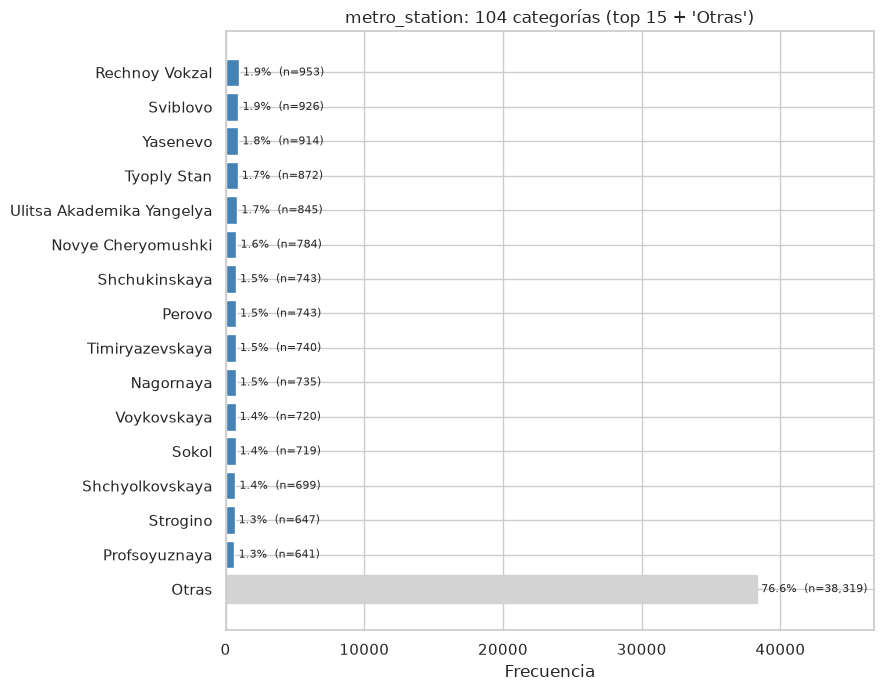

,n_categorias,moda,moda_%,top3_%acum,menos_frecuente,menos_frecuente_%
okrug,11,SVAO,13.32,37.94,ZelAO,0.72
district,129,Begovoy,0.87,2.58,Maryina Roshcha,0.68
building_type,6,panel,20.29,60.24,stalin,7.03
renovation,4,cosmetic,40.11,90.11,designer,9.89
metro_line,12,Kaluzhsko-Rizhskaya,14.33,40.64,MCC,1.45
metro_station,104,Rechnoy Vokzal,1.91,5.59,Kitay-Gorod,0.60


In [14]:
rows = {}
for col in CAT_NOM:
    vc = eda[col].value_counts()
    pct = 100 * vc / vc.sum()
    plot_vc = vc.head(TOP_N).copy()
    if len(vc) > TOP_N:
        plot_vc["Otras"] = vc.iloc[TOP_N:].sum()
    plot_pct = 100 * plot_vc / vc.sum()

    fig, ax = plt.subplots(figsize=(9, max(3, 0.38 * len(plot_vc) + 1)))
    bars = ax.barh(plot_vc.index.astype(str), plot_vc.values, color="steelblue")
    if "Otras" in plot_vc.index:
        bars[-1].set_color("lightgray")
    ax.invert_yaxis()
    ax.bar_label(bars, labels=[f"{p:.1f}%  (n={n:,})" for p, n in zip(plot_pct, plot_vc)],
                 fontsize=8, padding=3)
    ax.margins(x=0.22)
    titulo = f"{col}: {len(vc)} categorías"
    if len(vc) > TOP_N:
        titulo += f" (top {TOP_N} + 'Otras')"
    ax.set(title=titulo, xlabel="Frecuencia")
    plt.tight_layout()
    plt.show()
    rows[col] = {"n_categorias": len(vc), "moda": vc.index[0], "moda_%": pct.iloc[0],
                 "top3_%acum": pct.head(3).sum(),
                 "menos_frecuente": vc.index[-1], "menos_frecuente_%": pct.iloc[-1]}

show(pd.DataFrame.from_dict(rows, orient="index"), dec=2)

### EDA-5: binarias

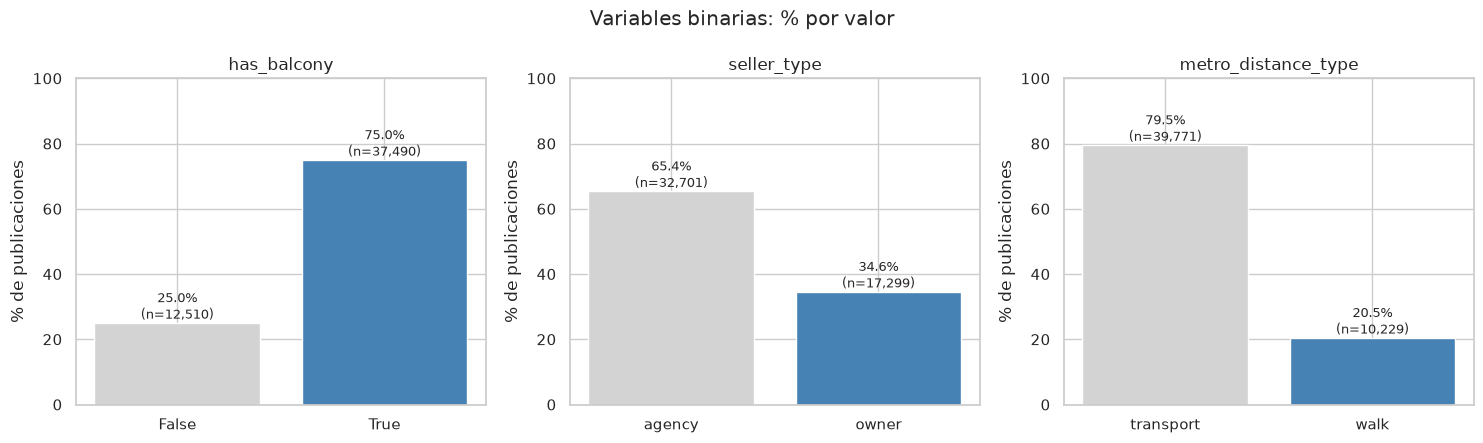

n      %
variable            valor                  
has_balcony         False      12510  25.02
                    True       37490  74.98
seller_type         agency     32701  65.40
                    owner      17299  34.60
metro_distance_type transport  39771  79.54
                    walk       10229  20.46

In [15]:
fig, axes = plt.subplots(1, len(BIN), figsize=(5 * len(BIN), 4.5))
rows = []
for ax, col in zip(axes, BIN):
    vc = eda[col].value_counts().sort_index()
    pct = 100 * vc / vc.sum()
    bars = ax.bar(vc.index.astype(str), pct.values, color=["lightgray", "steelblue"])
    ax.bar_label(bars, labels=[f"{p:.1f}%\n(n={n:,})" for p, n in zip(pct, vc)], fontsize=9)
    ax.set(title=col, ylabel="% de publicaciones", ylim=(0, 100))
    for v, n, p in zip(vc.index, vc.values, pct.values):
        rows.append({"variable": col, "valor": str(v), "n": n, "%": p})
fig.suptitle("Variables binarias: % por valor")
plt.tight_layout()
plt.show()
show(pd.DataFrame(rows).set_index(["variable", "valor"]), dec=2)

## 3. EDA bivariado (precio vs resto)

### EDA-6: matriz de asociación mixta (todas × todas)

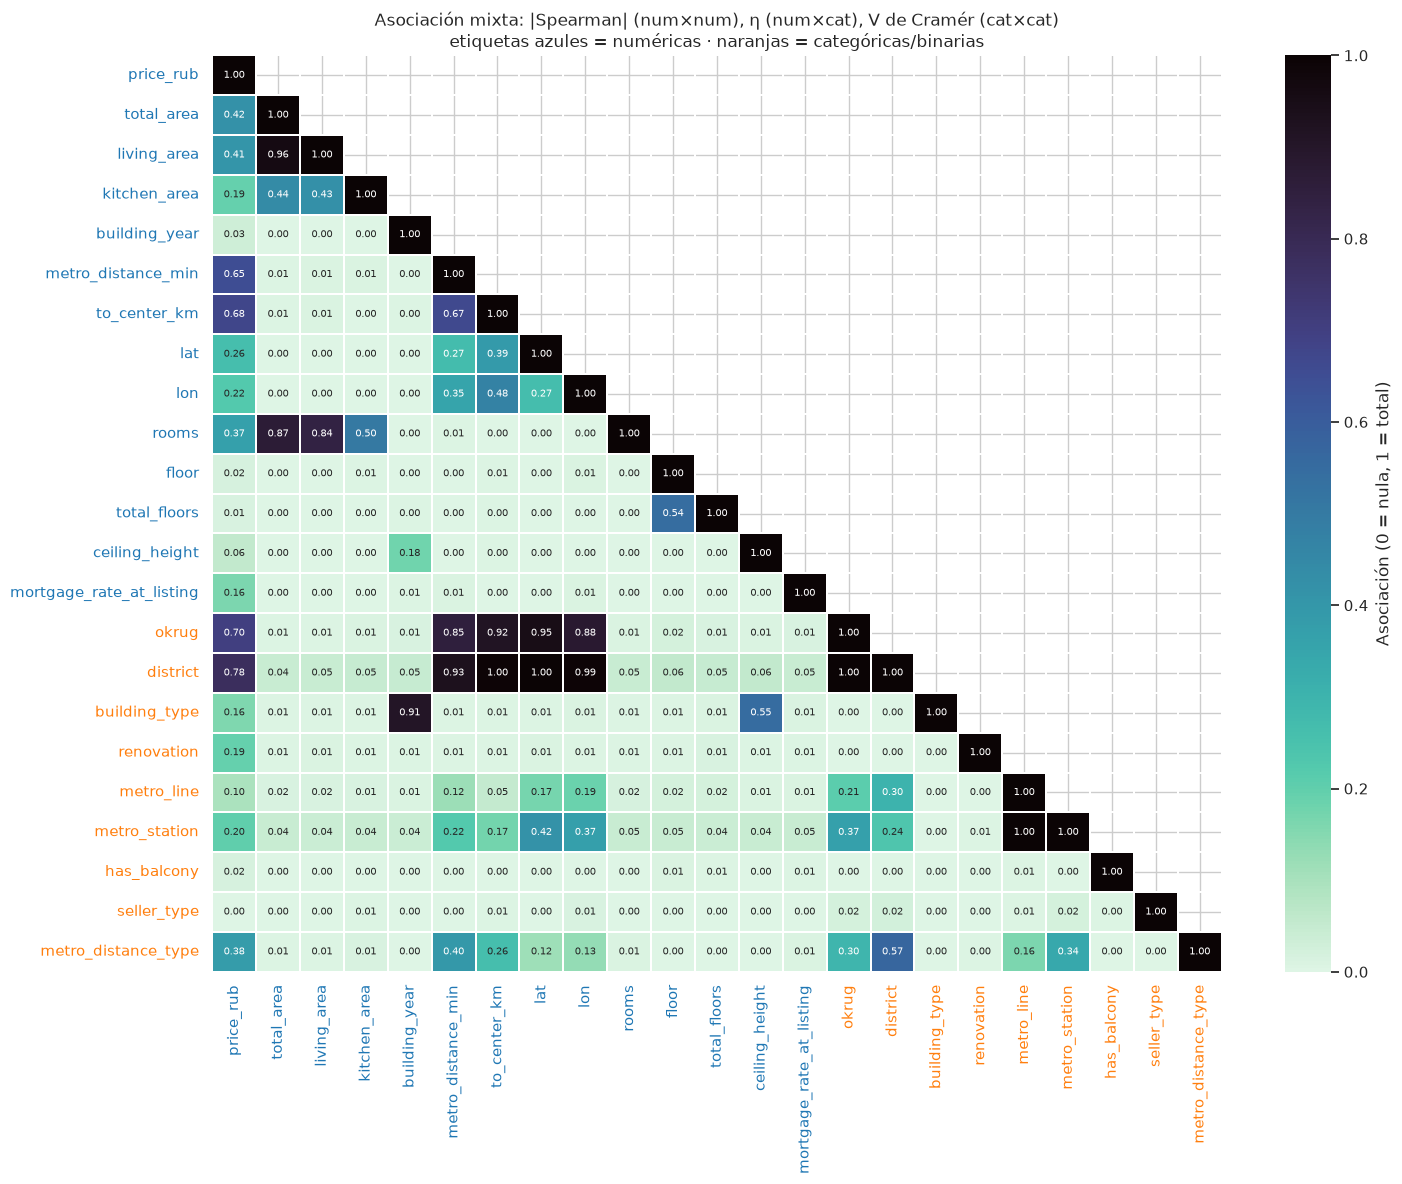

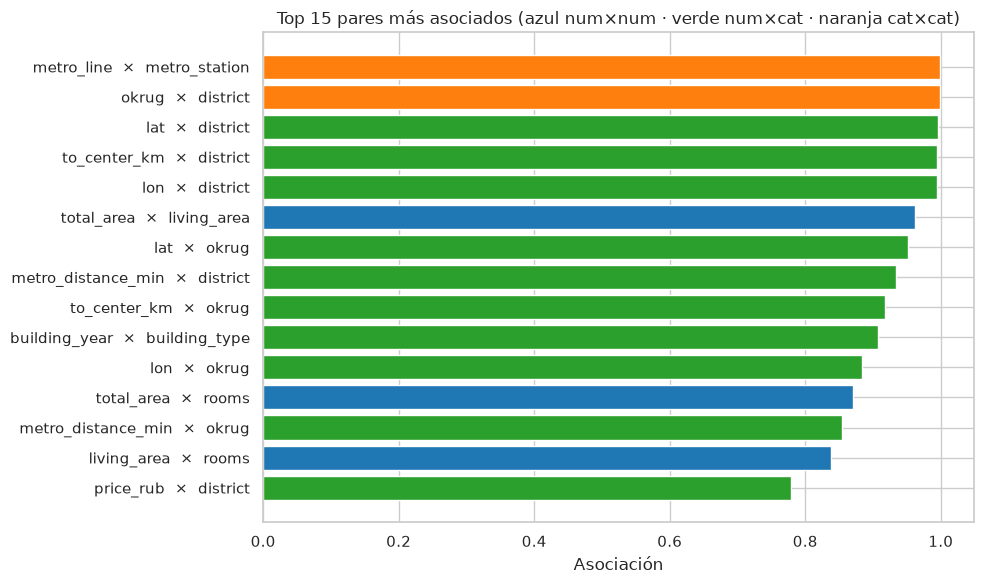

Top 20 pares más asociados


,var_1,var_2,tipo,medida,asociación
1,metro_line,metro_station,cat×cat,V de Cramér,0.999
2,okrug,district,cat×cat,V de Cramér,0.999
3,lat,district,num×cat,η,0.997
4,to_center_km,district,num×cat,η,0.995
5,lon,district,num×cat,η,0.995
6,total_area,living_area,num×num,|Spearman|,0.962
7,lat,okrug,num×cat,η,0.952
8,metro_distance_min,district,num×cat,η,0.933
9,to_center_km,okrug,num×cat,η,0.918
10,building_year,building_type,num×cat,η,0.907


Asociación de cada variable con price_rub


,variable,tipo,medida,asociación
0,district,num×cat,η,0.778
1,okrug,num×cat,η,0.700
2,to_center_km,num×num,|Spearman|,0.678
3,metro_distance_min,num×num,|Spearman|,0.652
4,total_area,num×num,|Spearman|,0.421
5,living_area,num×num,|Spearman|,0.409
6,metro_distance_type,num×cat,η,0.379
7,rooms,num×num,|Spearman|,0.368
8,lat,num×num,|Spearman|,0.263
9,lon,num×num,|Spearman|,0.224


In [16]:
def cramers_v(x, y):
    """V de Cramér con corrección de sesgo (Bergsma 2013). Rango 0-1."""
    ct = pd.crosstab(x, y)
    r, k = ct.shape
    if r < 2 or k < 2:
        return np.nan
    n = ct.values.sum()
    chi2 = chi2_contingency(ct, correction=False)[0]
    phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    denom = min(kc - 1, rc - 1)
    return np.sqrt(phi2c / denom) if denom > 0 else np.nan

def corr_ratio(cat, num):
    """Razón de correlación η (numérica vs categórica). Rango 0-1.
    Con una binaria equivale a |correlación punto-biserial|."""
    g = num.groupby(cat)
    ss_between = (g.count() * (g.mean() - num.mean()) ** 2).sum()
    ss_total = ((num - num.mean()) ** 2).sum()
    return np.sqrt(ss_between / ss_total)

NUM_ALL = [c for c in NUM_CONT + NUM_DISC if c not in BIV_EXCLUDE]   # incluye el target
CAT_ALL = CAT_NOM + BIN
cols = [TARGET] + [c for c in NUM_ALL if c != TARGET] + CAT_ALL

M = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
spear = eda[NUM_ALL].corr(method="spearman").abs()
pairs = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        if a in NUM_ALL and b in NUM_ALL:
            v, medida, tipo = spear.loc[a, b], "|Spearman|", "num×num"
        elif a in NUM_ALL:
            v, medida, tipo = corr_ratio(eda[b], eda[a]), "η", "num×cat"
        elif b in NUM_ALL:
            v, medida, tipo = corr_ratio(eda[a], eda[b]), "η", "num×cat"
        else:
            v, medida, tipo = cramers_v(eda[a], eda[b]), "V de Cramér", "cat×cat"
        M.loc[a, b] = M.loc[b, a] = v
        pairs.append({"var_1": a, "var_2": b, "tipo": tipo, "medida": medida, "asociación": v})

# --- Gráfico principal: heatmap de asociación mixta ---
fig, ax = plt.subplots(figsize=(15, 12))
mask = np.triu(np.ones_like(M, dtype=bool), k=1)
sns.heatmap(M, mask=mask, vmin=0, vmax=1, cmap="mako_r", annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.3,
            cbar_kws={"label": "Asociación (0 = nula, 1 = total)"}, ax=ax)
for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_color("tab:blue" if lbl.get_text() in NUM_ALL else "tab:orange")
ax.set_title("Asociación mixta: |Spearman| (num×num), η (num×cat), V de Cramér (cat×cat)\n"
             "etiquetas azules = numéricas · naranjas = categóricas/binarias")
plt.tight_layout()
plt.show()

# --- Complemento: ranking de los pares más asociados ---
rank = pd.DataFrame(pairs).sort_values("asociación", ascending=False).reset_index(drop=True)
rank.index += 1

top = rank.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
colores = {"num×num": "tab:blue", "num×cat": "tab:green", "cat×cat": "tab:orange"}
ax.barh(top["var_1"] + "  ×  " + top["var_2"], top["asociación"], color=top["tipo"].map(colores))
ax.set(xlabel="Asociación", title="Top 15 pares más asociados (azul num×num · verde num×cat · naranja cat×cat)")
plt.tight_layout()
plt.show()

print("Top 20 pares más asociados")
show(rank.head(20), dec=3)

print(f"Asociación de cada variable con {TARGET}")
vs_target = rank[(rank["var_1"] == TARGET) | (rank["var_2"] == TARGET)].copy()
vs_target["variable"] = np.where(vs_target["var_1"] == TARGET, vs_target["var_2"], vs_target["var_1"])
show(vs_target[["variable", "tipo", "medida", "asociación"]].reset_index(drop=True), dec=3)

### EDA-7: numérica × numérica (vs precio)

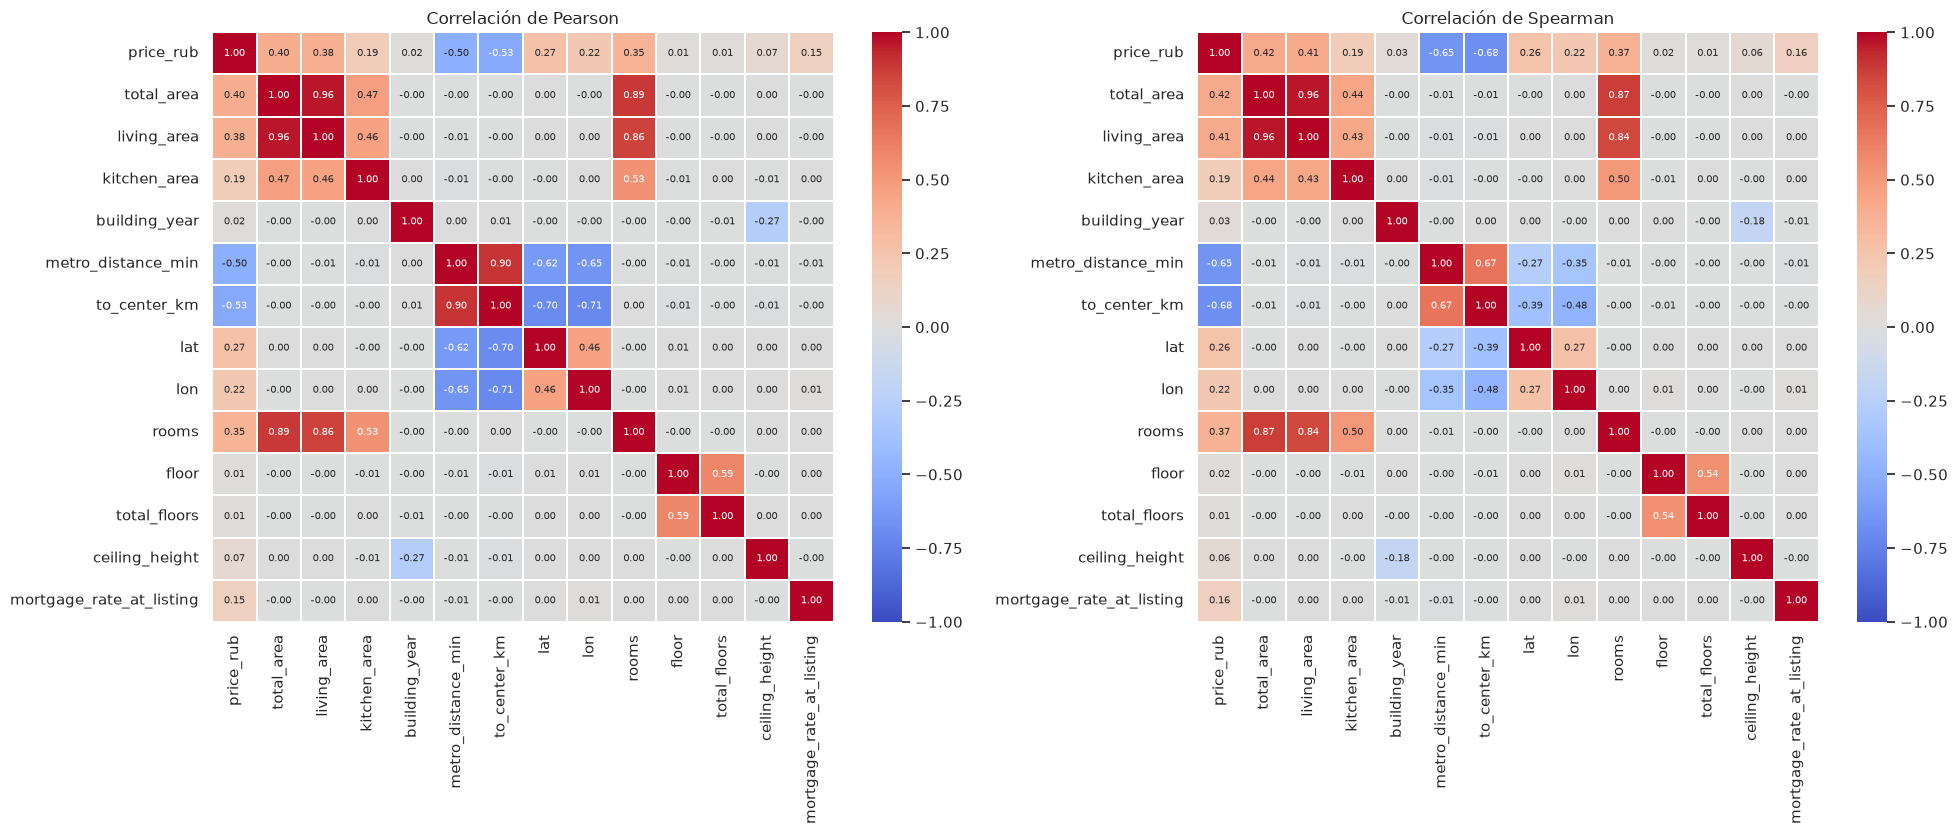

Pruebas de correlación vs price_rub (H0: correlación = 0)


,pearson_r,pearson_p,spearman_rho,spearman_p
variable,,,,
to_center_km,-0.533,0.00e+00,-0.678,0.00e+00
metro_distance_min,-0.496,0.00e+00,-0.652,0.00e+00
total_area,0.398,0.00e+00,0.421,0.00e+00
living_area,0.385,0.00e+00,0.409,0.00e+00
rooms,0.355,0.00e+00,0.368,0.00e+00
lat,0.266,0.00e+00,0.263,0.00e+00
lon,0.224,0.00e+00,0.224,0.00e+00
kitchen_area,0.193,0.00e+00,0.193,0.00e+00
mortgage_rate_at_listing,0.149,3.17e-245,0.164,1.49e-298


Top 5 por |Spearman|: ['to_center_km', 'metro_distance_min', 'total_area', 'living_area', 'rooms']


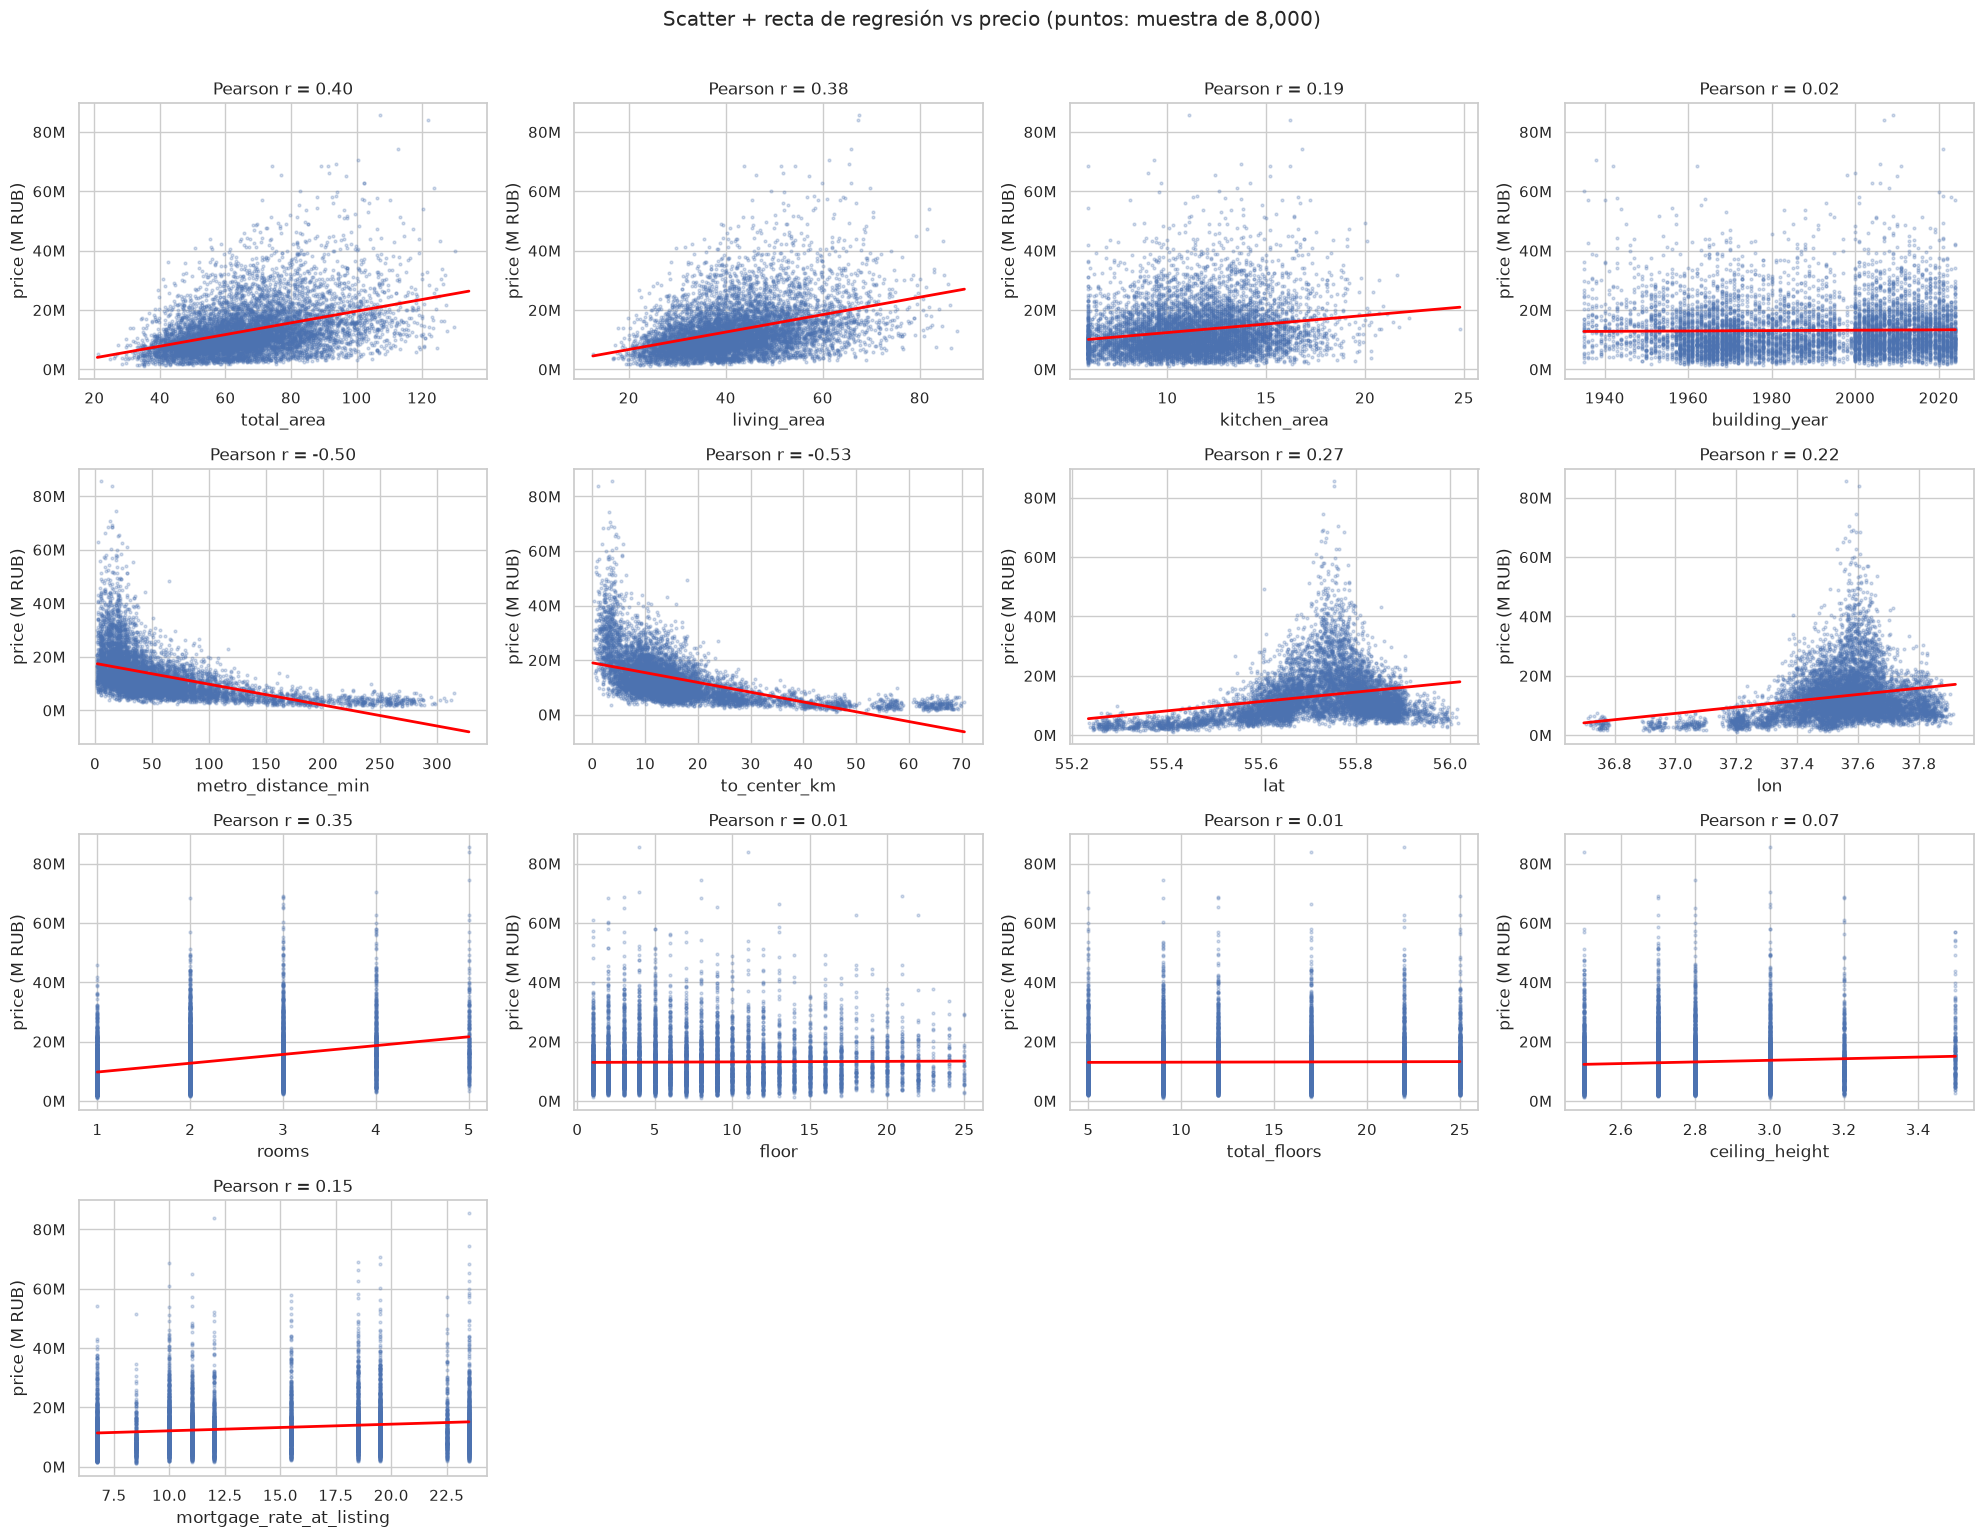

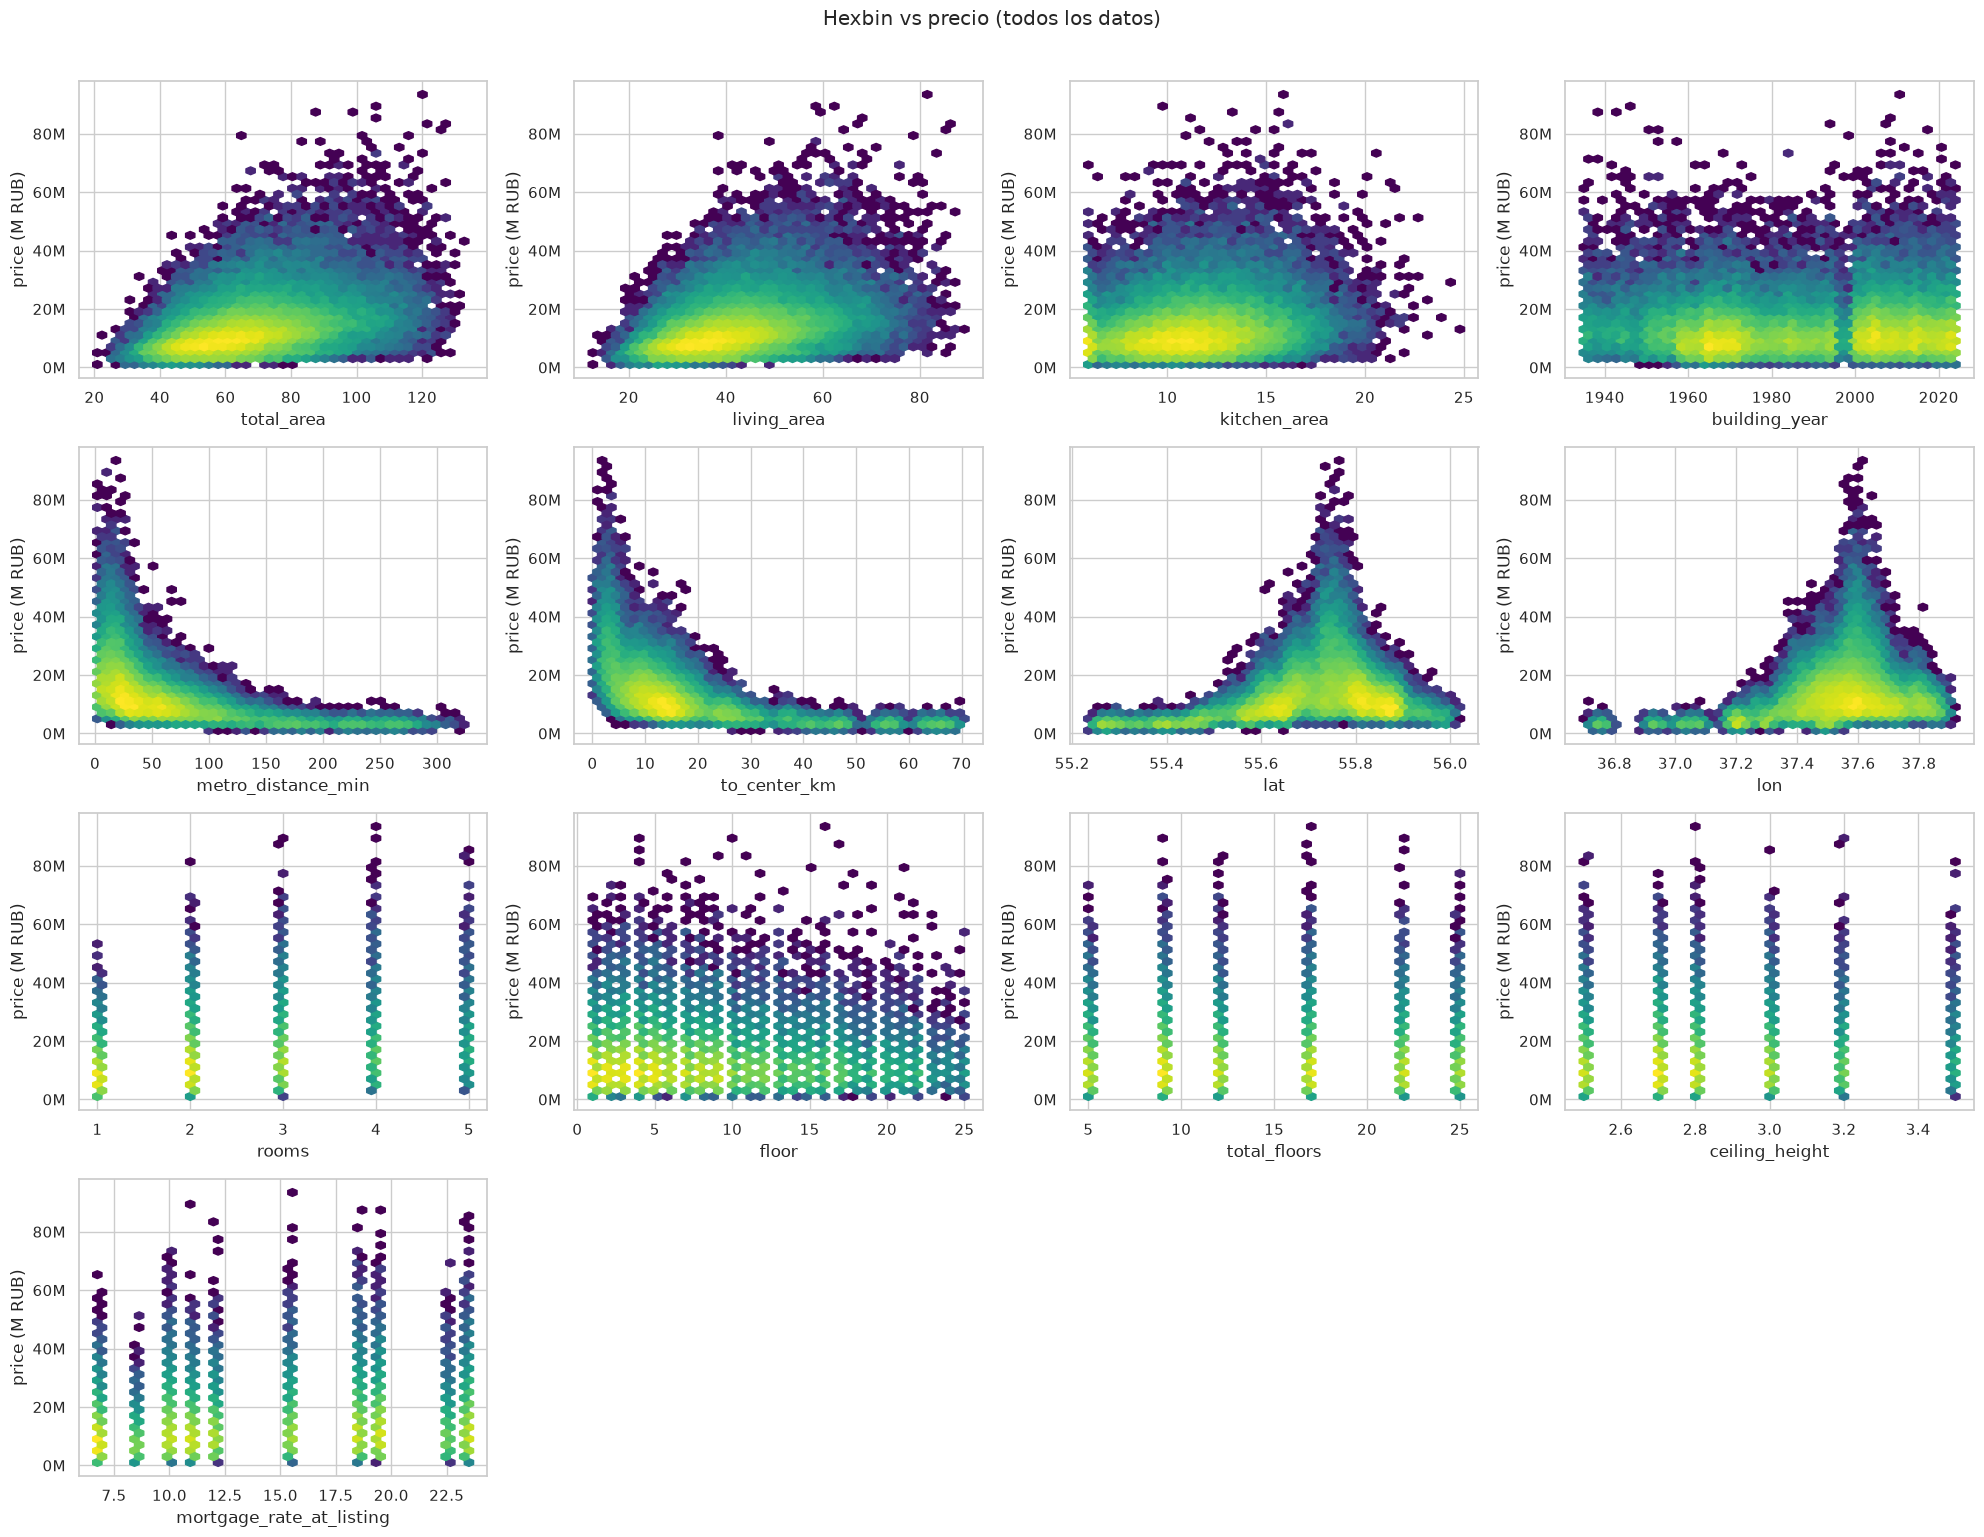

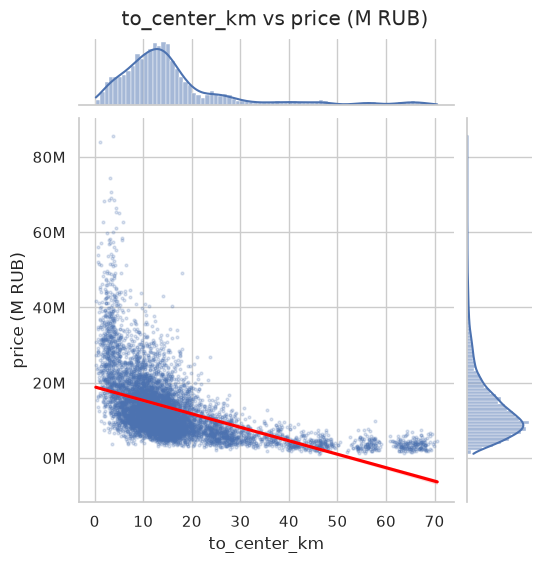

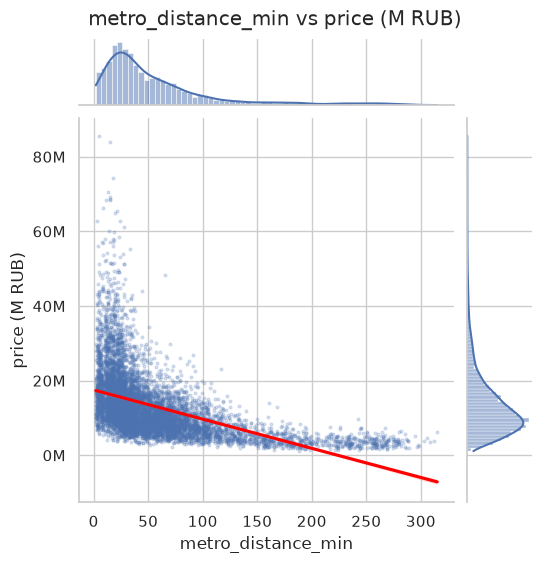

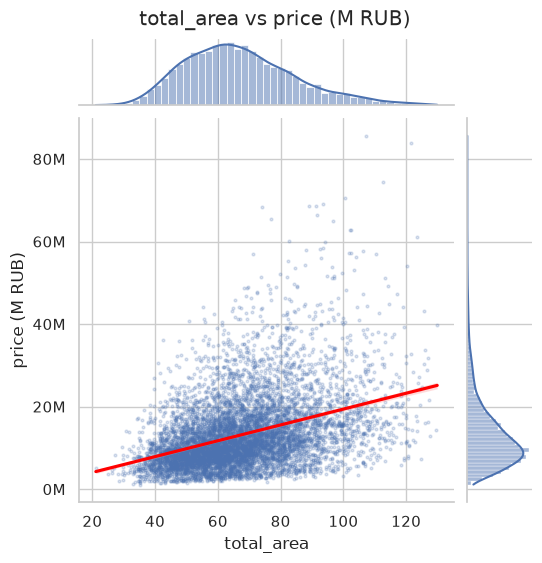

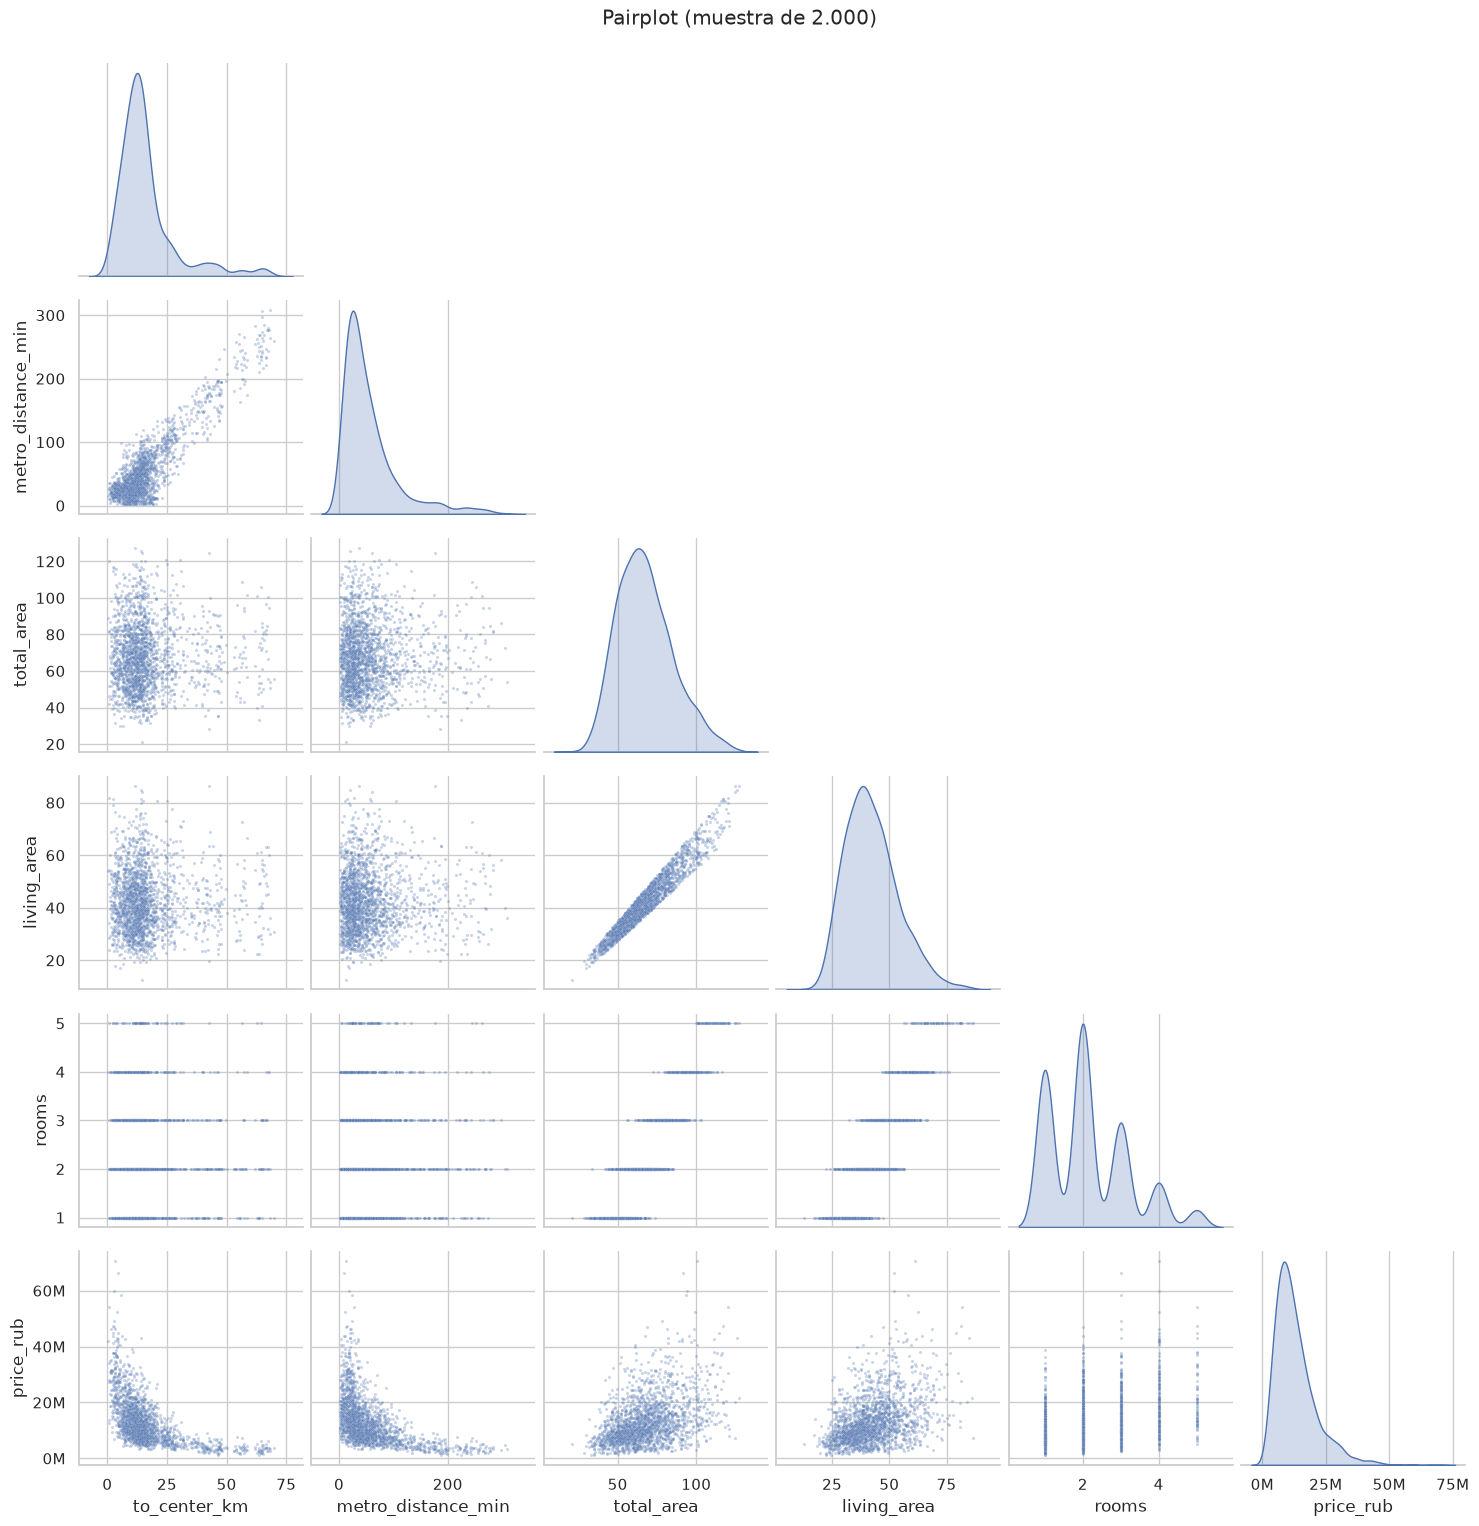

In [17]:
NUM_X = [c for c in NUM_ALL if c != TARGET]     # numéricas (continuas + discretas) sin el target
corr_cols = [TARGET] + NUM_X

# --- Gráfico principal: heatmaps de correlación ---
fig, axes = plt.subplots(1, 2, figsize=(20, 8.5))
for ax, met in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(eda[corr_cols].corr(method=met), annot=True, fmt=".2f", annot_kws={"size": 7},
                cmap="coolwarm", vmin=-1, vmax=1, center=0, linewidths=0.3, ax=ax)
    ax.set_title(f"Correlación de {met.capitalize()}")
plt.tight_layout()
plt.show()

# --- Prueba estadística: cada numérica vs precio ---
res = []
for c in NUM_X:
    r, p_r = stats.pearsonr(eda[c], eda[TARGET])
    rho, p_s = stats.spearmanr(eda[c], eda[TARGET])
    res.append({"variable": c, "pearson_r": r, "pearson_p": p_r,
                "spearman_rho": rho, "spearman_p": p_s})
tbl_num = (pd.DataFrame(res).set_index("variable")
           .sort_values("spearman_rho", key=lambda s: s.abs(), ascending=False))
print("Pruebas de correlación vs price_rub (H0: correlación = 0)")
show(tbl_num, p_cols=["pearson_p", "spearman_p"])
TOP_NUM = tbl_num.index[:5].tolist()     # las 5 más correlacionadas, se reusan abajo
print("Top 5 por |Spearman|:", TOP_NUM)

# --- Complemento 1: scatter + recta (la recta se ajusta con TODOS los datos) ---
samp = eda.sample(SAMPLE_N, random_state=SEED)
ncols = 4
nrows = int(np.ceil(len(NUM_X) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows))
axes = axes.ravel()
for ax, c in zip(axes, NUM_X):
    ax.scatter(samp[c], samp[TARGET], s=4, alpha=0.25)
    b, a = np.polyfit(eda[c], eda[TARGET], 1)
    xs = np.linspace(eda[c].min(), eda[c].max(), 100)
    ax.plot(xs, a + b * xs, color="red", lw=2)
    ax.set(xlabel=c, ylabel="price (M RUB)", title=f"Pearson r = {tbl_num.loc[c, 'pearson_r']:.2f}")
    millions(ax, "y")
for ax in axes[len(NUM_X):]:
    ax.axis("off")
fig.suptitle(f"Scatter + recta de regresión vs precio (puntos: muestra de {SAMPLE_N:,})", y=1.01)
plt.tight_layout()
plt.show()

# --- Complemento 2: hexbin (todos los datos, color = log de la cantidad de puntos) ---
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows))
axes = axes.ravel()
for ax, c in zip(axes, NUM_X):
    ax.hexbin(eda[c], eda[TARGET], gridsize=40, bins="log", mincnt=1, cmap="viridis")
    ax.set(xlabel=c, ylabel="price (M RUB)")
    millions(ax, "y")
for ax in axes[len(NUM_X):]:
    ax.axis("off")
fig.suptitle("Hexbin vs precio (todos los datos)", y=1.01)
plt.tight_layout()
plt.show()

# --- Complemento 3: jointplot de las 3 más correlacionadas ---
for c in TOP_NUM[:3]:
    g = sns.jointplot(data=samp, x=c, y=TARGET, kind="reg", height=5.5,
                      joint_kws={"scatter_kws": {"s": 4, "alpha": 0.2}, "line_kws": {"color": "red"}})
    millions(g.ax_joint, "y")
    g.ax_joint.set_ylabel("price (M RUB)")
    g.figure.suptitle(f"{c} vs price (M RUB)", y=1.02)
    plt.show()

# --- Complemento 4: pairplot de las 5 más correlacionadas + precio ---
pp = sns.pairplot(eda.sample(2000, random_state=SEED)[TOP_NUM + [TARGET]],
                  corner=True, diag_kind="kde", plot_kws={"s": 5, "alpha": 0.3})
millones_pairplot(pp)
pp.figure.suptitle("Pairplot (muestra de 2.000)", y=1.02)
plt.show()

### EDA-8: numérica × numérica × categórica

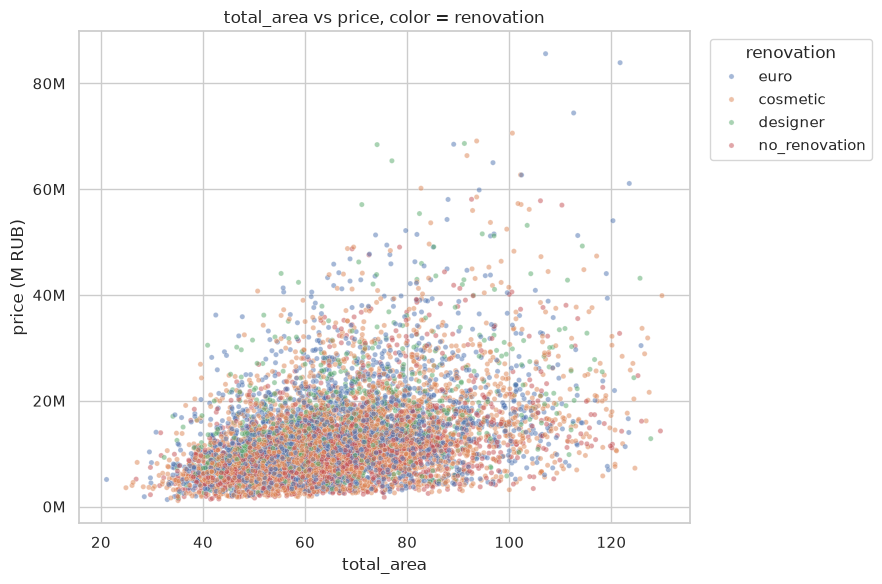

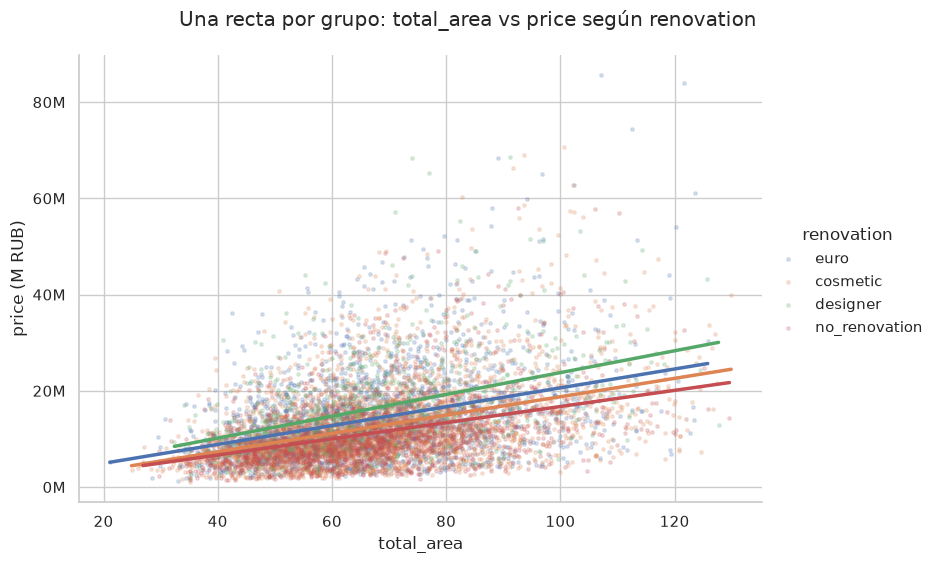

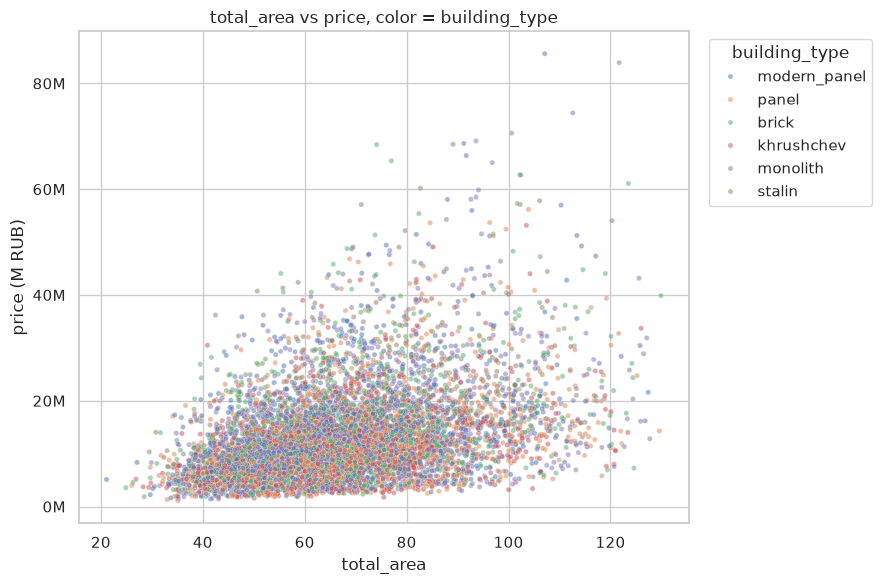

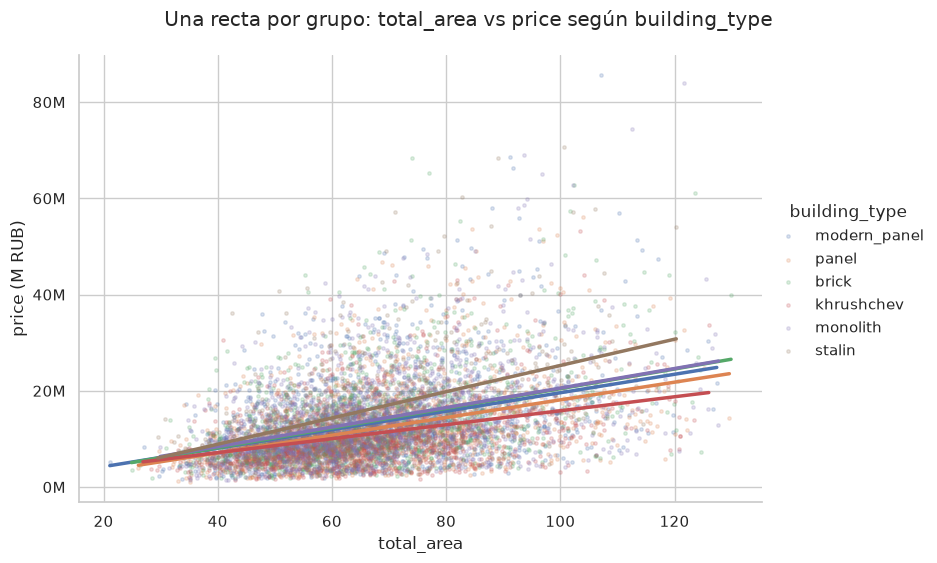

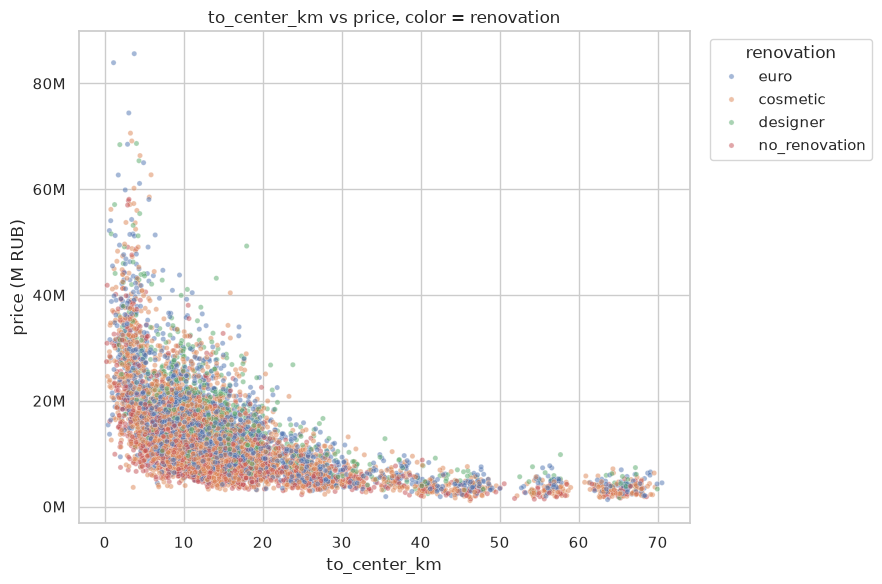

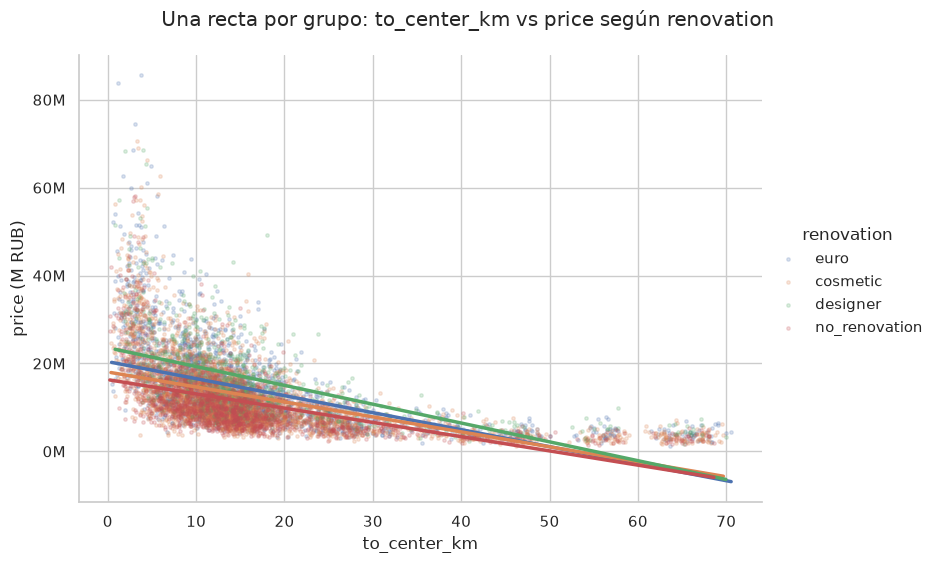

Prueba de interacción (H0: la pendiente de X vs precio es la misma en todos los grupos)


gl_interacción       F   p_valor
x            grupo                                          
total_area   renovation                3.0  51.000  6.66e-33
             building_type             5.0  25.074  2.46e-25
to_center_km renovation                3.0  99.095  5.96e-64

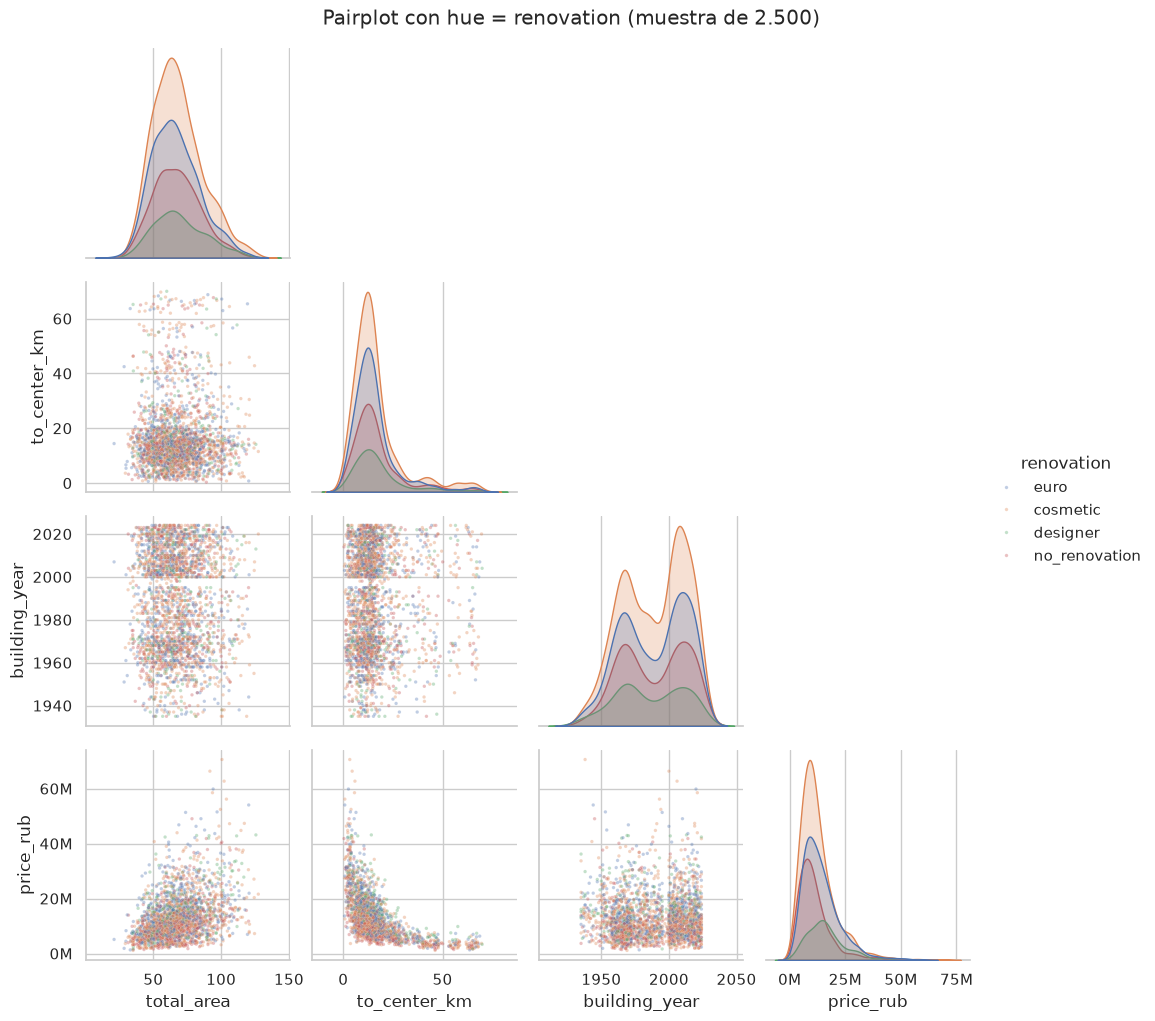

In [18]:
# Pares (numérica X, categórica de hue) a analizar. Editá la lista a gusto (conviene hue con <= 6 niveles).
PARES_HUE = [("total_area", "renovation"),
             ("total_area", "building_type"),
             ("to_center_km", "renovation")]
HUE_PAIRPLOT = "renovation"

samp = eda.sample(SAMPLE_N, random_state=SEED)
res = []
for x, cat in PARES_HUE:
    # Gráfico principal: scatter con hue
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.scatterplot(data=samp, x=x, y=TARGET, hue=cat, s=14, alpha=0.5, ax=ax)
    ax.set(ylabel="price (M RUB)", title=f"{x} vs price, color = {cat}")
    millions(ax, "y")
    ax.legend(title=cat, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    # Complemento: lmplot, una recta por grupo
    g = sns.lmplot(data=samp, x=x, y=TARGET, hue=cat, ci=None, height=5.5, aspect=1.4,
                   scatter_kws={"s": 6, "alpha": 0.2}, line_kws={"lw": 2.5})
    millions(g.ax, "y")
    g.ax.set_ylabel("price (M RUB)")
    g.figure.suptitle(f"Una recta por grupo: {x} vs price según {cat}", y=1.02)
    plt.show()

    # Prueba: ¿difieren las pendientes entre grupos? (F de interacción, con TODOS los datos)
    m0 = smf_ols(f"price_rub ~ {x} + C({cat})", data=eda).fit()
    m1 = smf_ols(f"price_rub ~ {x} * C({cat})", data=eda).fit()
    a = anova_lm(m0, m1)
    res.append({"x": x, "grupo": cat, "gl_interacción": a["df_diff"].iloc[1],
                "F": a["F"].iloc[1], "p_valor": a["Pr(>F)"].iloc[1]})

print("Prueba de interacción (H0: la pendiente de X vs precio es la misma en todos los grupos)")
show(pd.DataFrame(res).set_index(["x", "grupo"]), p_cols=["p_valor"])

# Complemento: pairplot con hue
pp_cols = ["total_area", "to_center_km", "building_year", TARGET]
pp = sns.pairplot(eda.sample(2500, random_state=SEED)[pp_cols + [HUE_PAIRPLOT]],
                  hue=HUE_PAIRPLOT, corner=True, diag_kind="kde", plot_kws={"s": 6, "alpha": 0.35})
millones_pairplot(pp)
pp.figure.suptitle(f"Pairplot con hue = {HUE_PAIRPLOT} (muestra de 2.500)", y=1.02)
plt.show()

### EDA-9: numérica × categórica

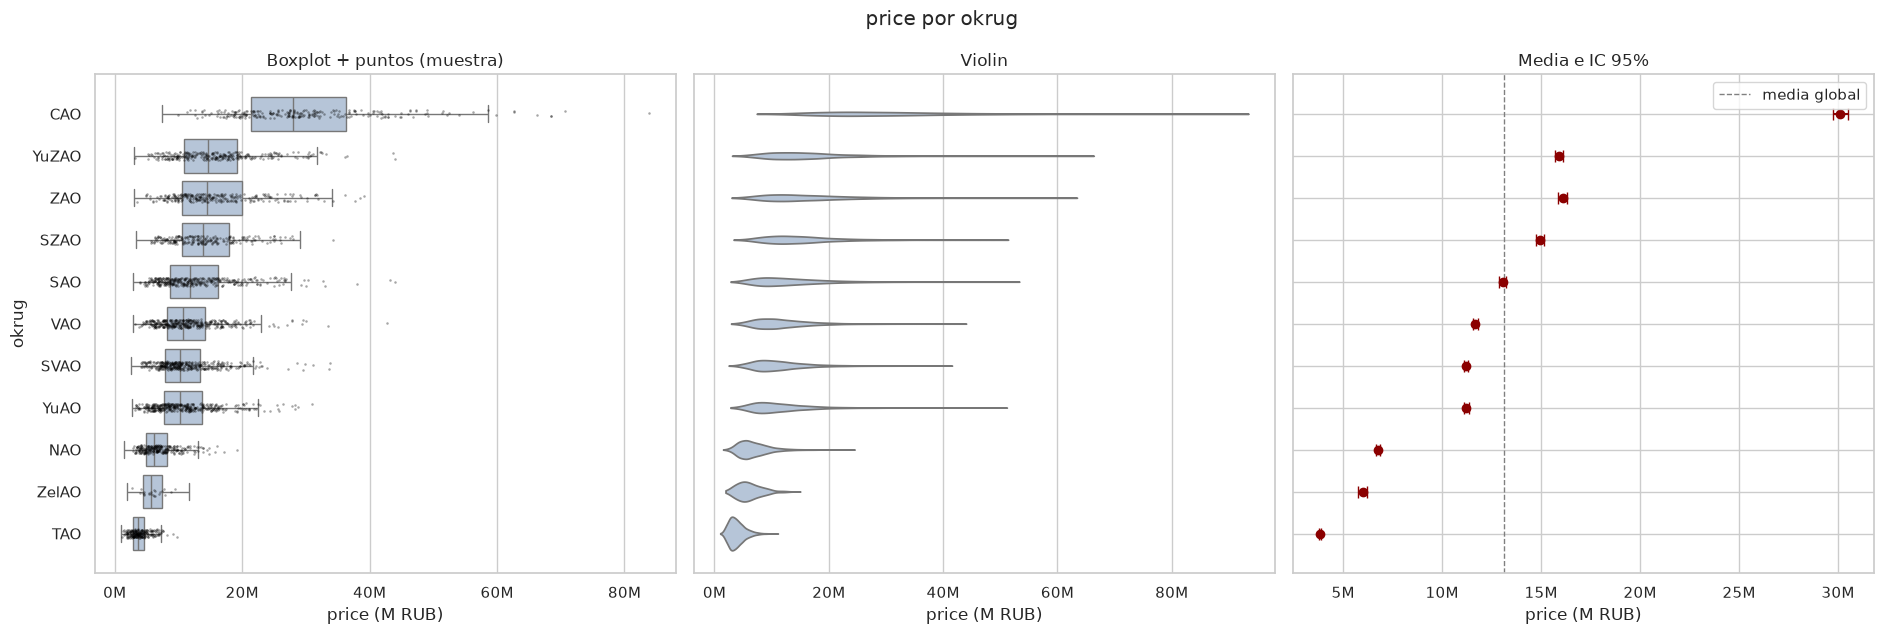

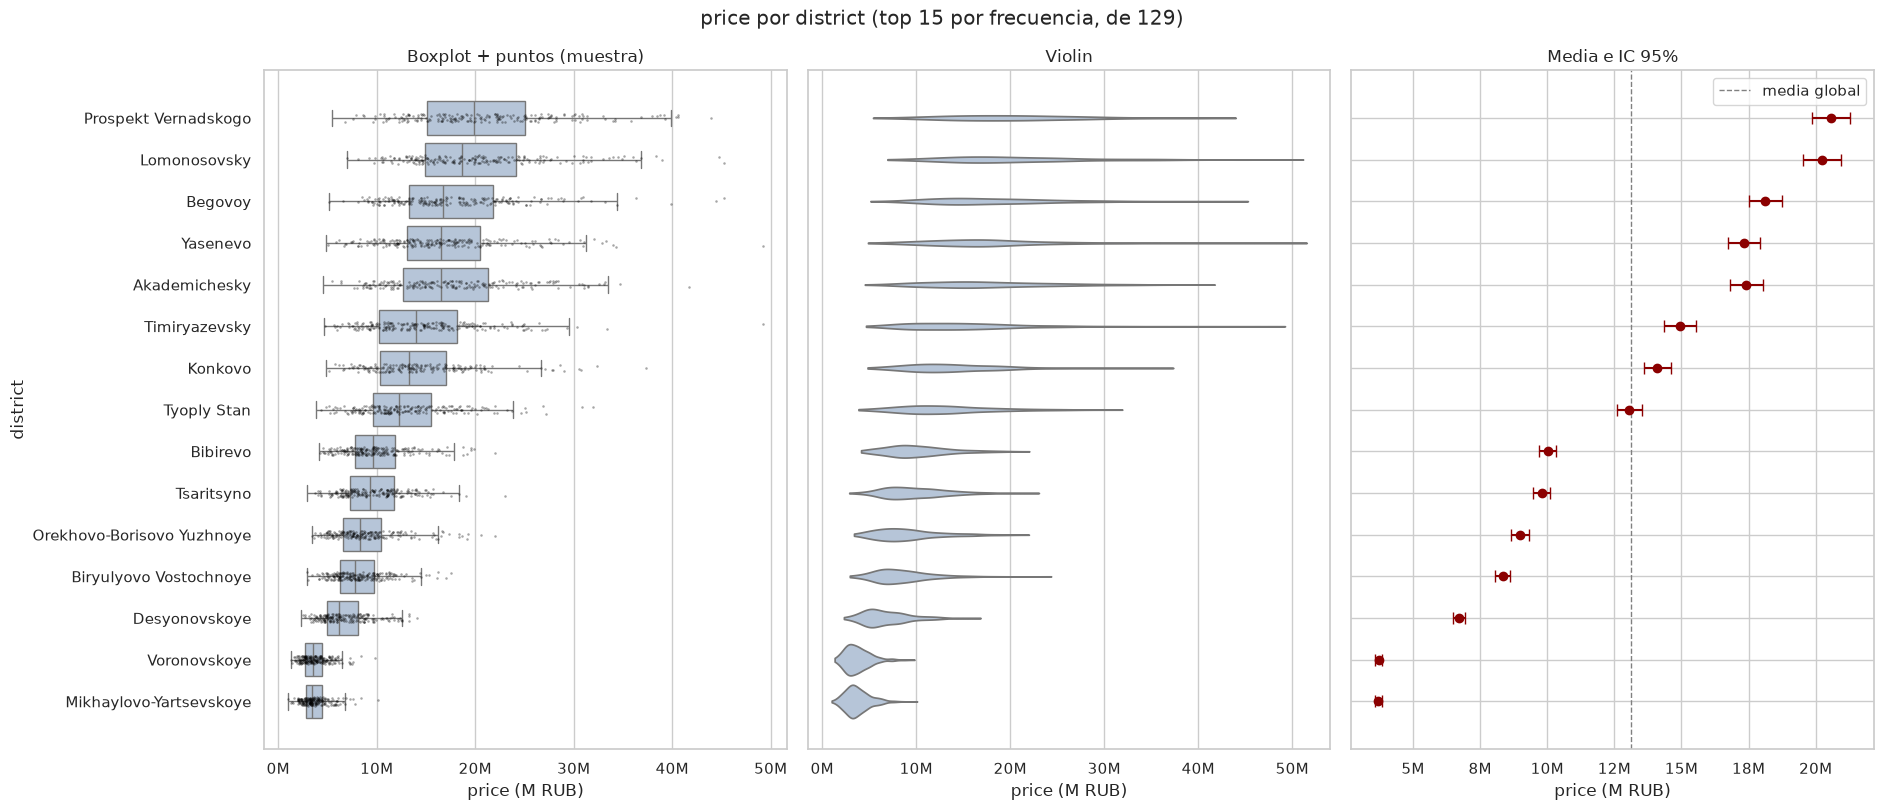

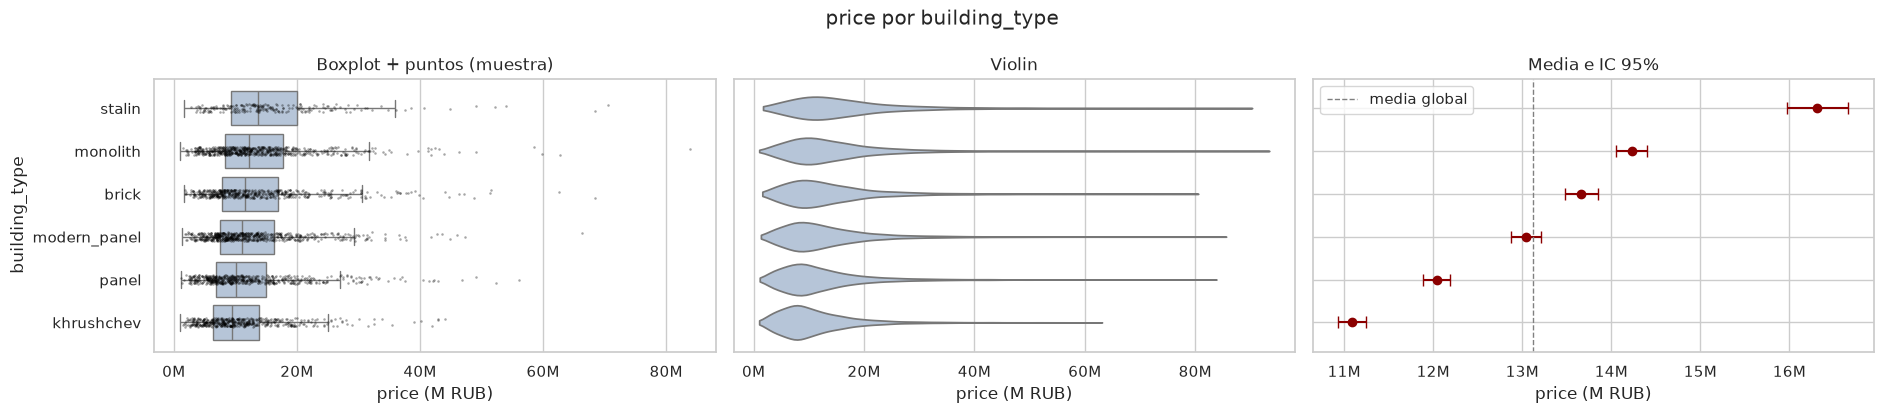

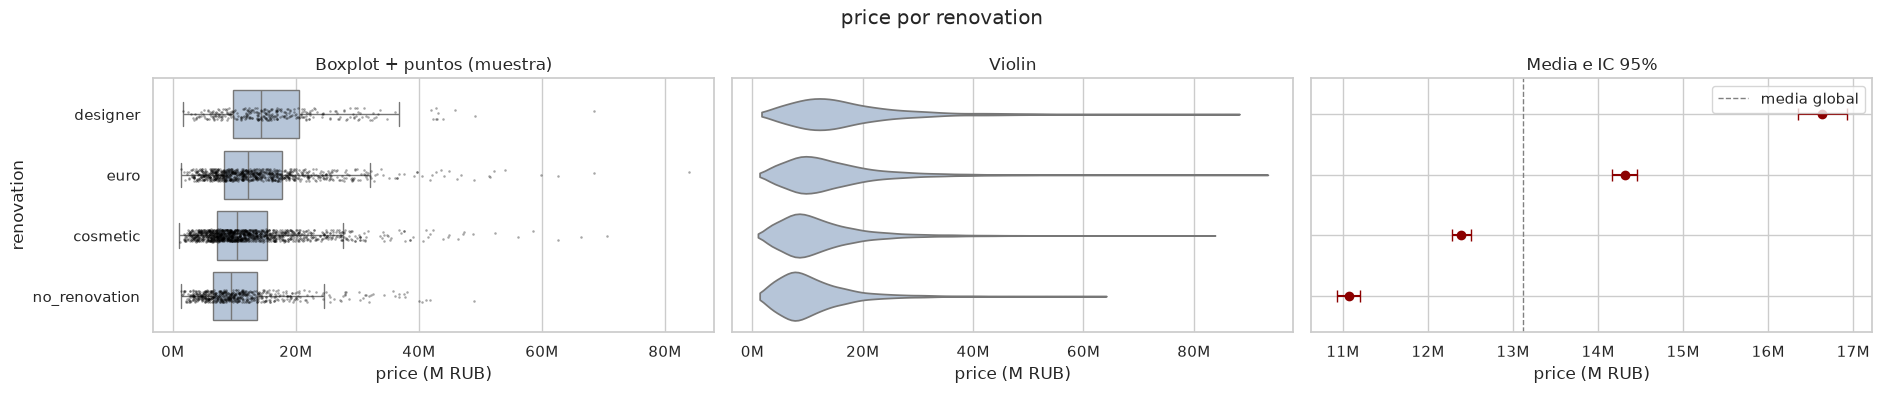

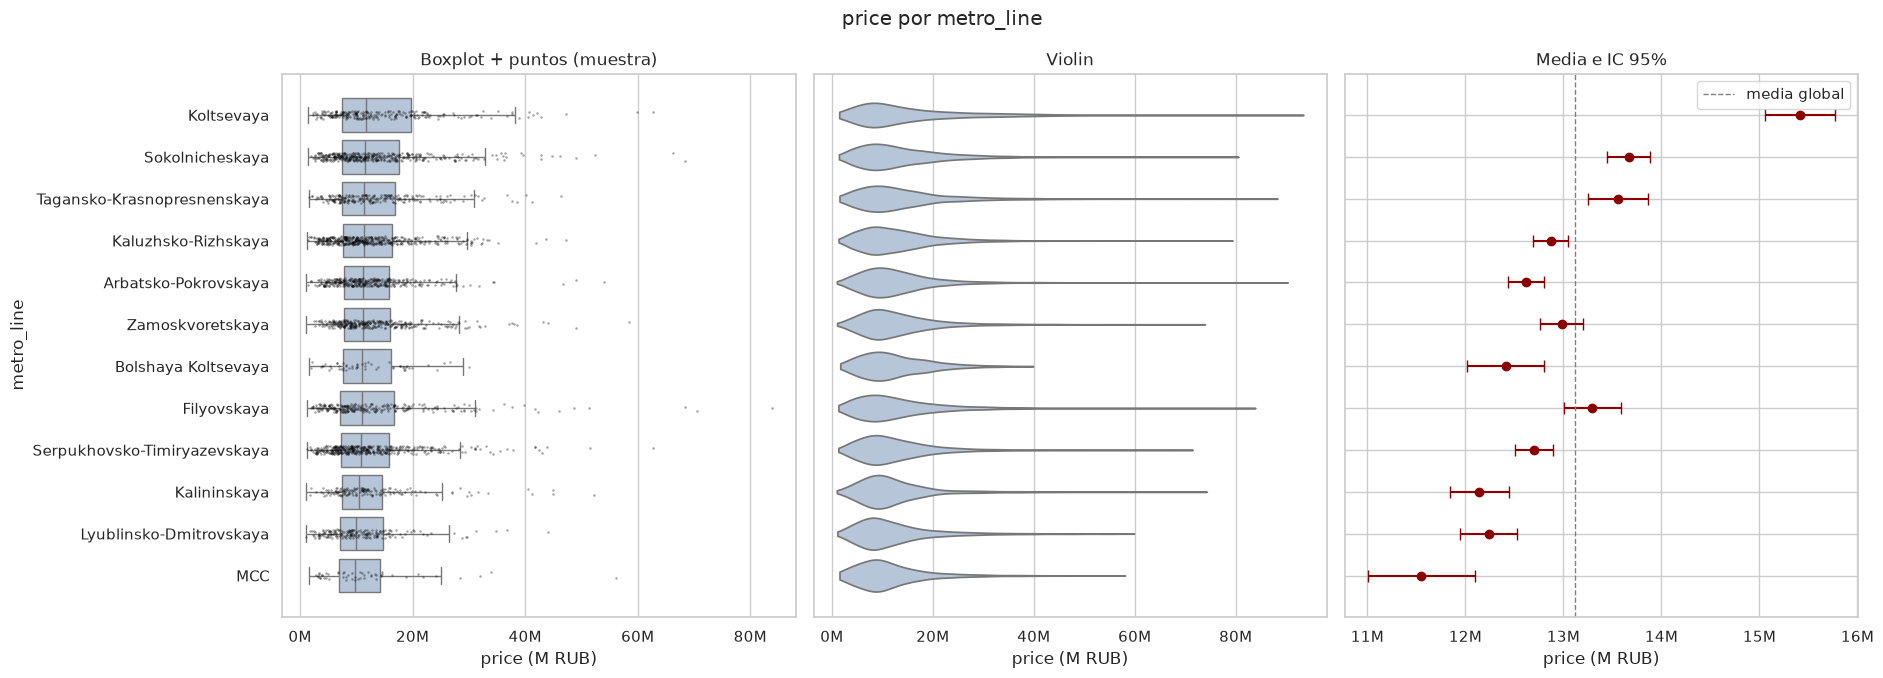

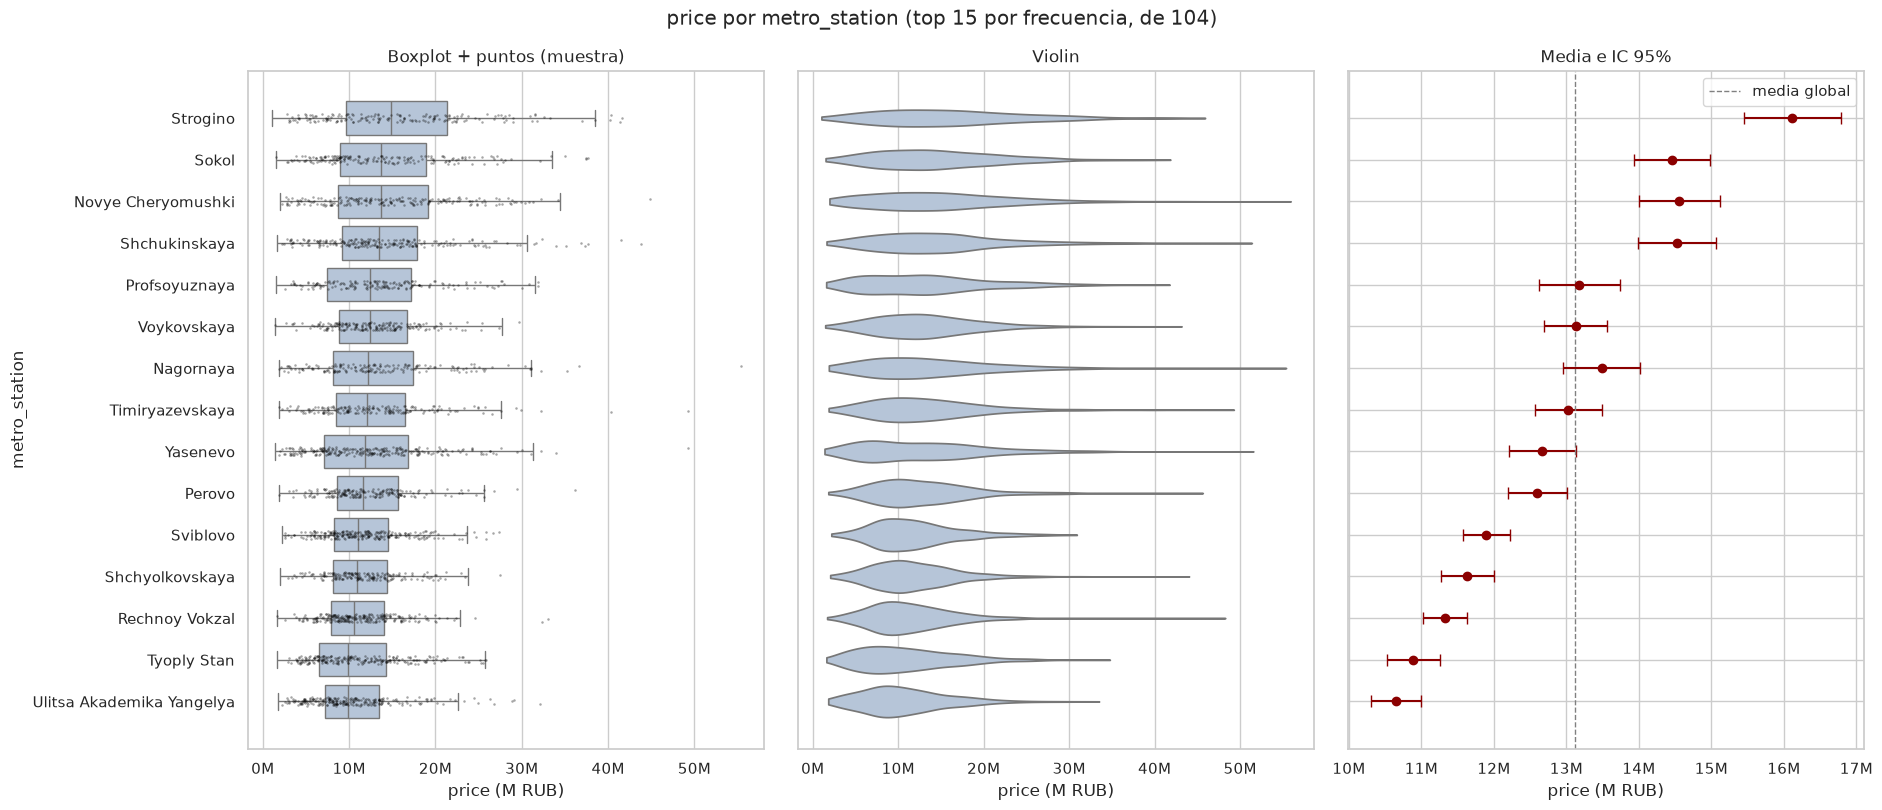

Pruebas precio ~ categórica (H0: el precio es igual en todas las categorías). η² = proporción de la varianza del precio explicada por la variable


,n_categorias,F_anova,p_anova,H_kruskal,p_kruskal,eta2
variable,,,,,,
okrug,11,4815.079,0.00e+00,24408.158,0.00e+00,0.491
district,129,599.063,0.00e+00,31101.611,0.00e+00,0.606
building_type,6,261.967,2.09e-277,1424.653,6.26e-306,0.026
renovation,4,639.119,0.00e+00,2042.382,0.00e+00,0.037
metro_line,12,43.472,4.26e-95,204.788,7.54e-38,0.009
metro_station,104,20.796,0.00e+00,1333.331,5.98e-213,0.041


In [19]:
res = []
mu_total = eda[TARGET].mean()
ss_total = ((eda[TARGET] - mu_total) ** 2).sum()

for col in CAT_NOM:
    d = eda[[col, TARGET]]
    n_cat = d[col].nunique()

    # Si hay muchas categorías, se dibujan las TOP_N más frecuentes, ordenadas por mediana de precio
    frecuentes = d[col].value_counts().head(TOP_N).index
    dd = d[d[col].isin(frecuentes)]
    order = dd.groupby(col)[TARGET].median().sort_values(ascending=False).index.tolist()
    k = len(order)

    fig, axes = plt.subplots(1, 3, figsize=(19, max(4, 0.45 * k + 1.5)), sharey=True)
    # Principal: boxplot + puntos
    sns.boxplot(data=dd, x=TARGET, y=col, order=order, showfliers=False,
                color="lightsteelblue", ax=axes[0])
    sns.stripplot(data=dd.sample(min(len(dd), 3000), random_state=SEED), x=TARGET, y=col,
                  order=order, size=1.8, alpha=0.35, color="black", ax=axes[0])
    axes[0].set_title("Boxplot + puntos (muestra)")
    # Complemento: violin
    sns.violinplot(data=dd, x=TARGET, y=col, order=order, cut=0, inner=None,
                   color="lightsteelblue", ax=axes[1])
    axes[1].set_title("Violin")
    # Complemento: media con IC 95%
    g = dd.groupby(col)[TARGET].agg(["mean", "sem", "count"]).loc[order]
    ci = stats.t.ppf(0.975, g["count"] - 1) * g["sem"]
    axes[2].errorbar(g["mean"], np.arange(k), xerr=ci, fmt="o", capsize=4, color="darkred")
    axes[2].axvline(eda[TARGET].mean(), color="gray", ls="--", lw=1, label="media global")
    axes[2].legend()
    axes[2].set_title("Media e IC 95%")
    for ax in axes:
        millions(ax, "x")
        ax.set_xlabel("price (M RUB)")
    sub = f" (top {TOP_N} por frecuencia, de {n_cat})" if n_cat > TOP_N else ""
    fig.suptitle(f"price por {col}{sub}")
    plt.tight_layout()
    plt.show()

    # Pruebas con TODAS las categorías: ANOVA, Kruskal-Wallis y η²
    groups = [g_[TARGET].values for _, g_ in d.groupby(col)]
    F, p_a = stats.f_oneway(*groups)
    H, p_k = stats.kruskal(*groups)
    ss_b = sum(len(x) * (x.mean() - mu_total) ** 2 for x in groups)
    res.append({"variable": col, "n_categorias": len(groups), "F_anova": F, "p_anova": p_a,
                "H_kruskal": H, "p_kruskal": p_k, "eta2": ss_b / ss_total})

print("Pruebas precio ~ categórica (H0: el precio es igual en todas las categorías). "
      "η² = proporción de la varianza del precio explicada por la variable")
show(pd.DataFrame(res).set_index("variable"), p_cols=["p_anova", "p_kruskal"])

### EDA-10: numérica × binaria

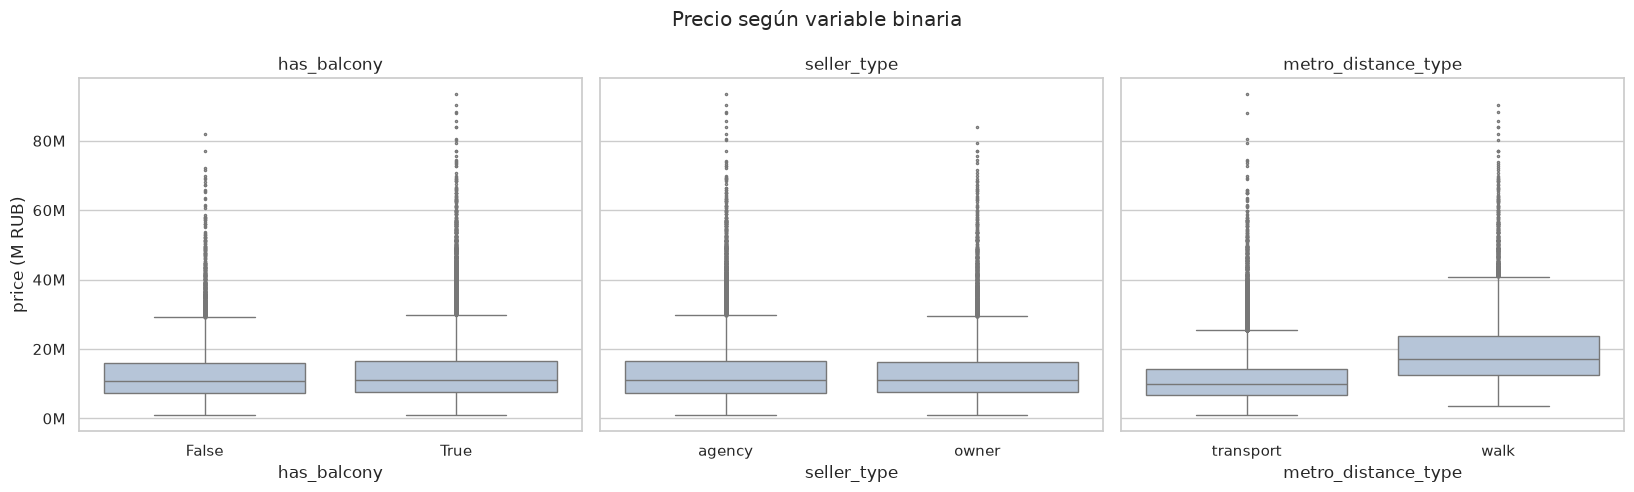

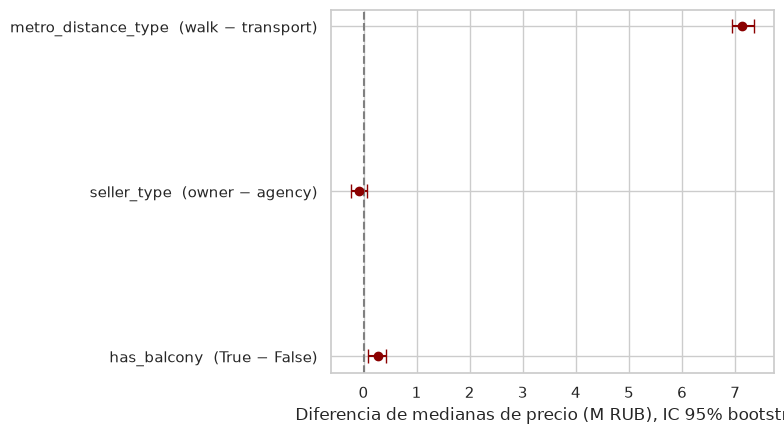

Diferencia de medianas (B − A) y pruebas (Mann-Whitney y t de Welch)


,grupo_A,grupo_B,n_A,n_B,mediana_A,mediana_B,dif_medianas,dif_%,ic95_inf,ic95_sup,p_mannwhitney,p_welch
variable,,,,,,,,,,,,
has_balcony,False,True,12510,37490,10878500.0,11152500.0,274000.0,2.52,91487.5,424512.5,5.13e-05,1.91e-05
seller_type,agency,owner,32701,17299,11112000.0,11028000.0,-84000.0,-0.76,-236075.0,64000.0,5.03e-01,9.44e-01
metro_distance_type,transport,walk,39771,10229,9897000.0,17029000.0,7132000.0,72.06,6933900.0,7351050.0,0.00e+00,0.00e+00


In [20]:
B = 1000   # remuestreos bootstrap para el IC de la diferencia de medianas

# --- Gráfico principal: boxplots por valor (small multiples, una columna por binaria) ---
plot_df = eda[BIN + [TARGET]].astype({c: str for c in BIN})
fig, axes = plt.subplots(1, len(BIN), figsize=(5.5 * len(BIN), 5), sharey=True)
for ax, col in zip(axes, BIN):
    sns.boxplot(data=plot_df, x=col, y=TARGET, order=sorted(plot_df[col].unique()),
                color="lightsteelblue", fliersize=1.5, ax=ax)
    ax.set(title=col, ylabel="price (M RUB)")
    millions(ax, "y")
fig.suptitle("Precio según variable binaria")
plt.tight_layout()
plt.show()

# --- Complemento: diferencia de medianas (grupo B - grupo A) + pruebas ---
res = []
for col in BIN:
    val_a, val_b = sorted(eda[col].unique())
    a = eda.loc[eda[col] == val_a, TARGET].values
    b = eda.loc[eda[col] == val_b, TARGET].values
    med_a, med_b = np.median(a), np.median(b)
    boots = np.array([np.median(RNG.choice(b, len(b))) - np.median(RNG.choice(a, len(a)))
                      for _ in range(B)])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    _, p_mw = stats.mannwhitneyu(b, a, alternative="two-sided")
    _, p_t = stats.ttest_ind(b, a, equal_var=False)
    res.append({"variable": col, "grupo_A": str(val_a), "grupo_B": str(val_b),
                "n_A": len(a), "n_B": len(b), "mediana_A": med_a, "mediana_B": med_b,
                "dif_medianas": med_b - med_a, "dif_%": 100 * (med_b - med_a) / med_a,
                "ic95_inf": lo, "ic95_sup": hi, "p_mannwhitney": p_mw, "p_welch": p_t})
tbl_bin = pd.DataFrame(res).set_index("variable")

fig, ax = plt.subplots(figsize=(8, 3 + 0.5 * len(BIN)))
y = np.arange(len(tbl_bin))
ax.errorbar(tbl_bin["dif_medianas"] / 1e6, y, fmt="o", color="darkred", capsize=5,
            xerr=[(tbl_bin["dif_medianas"] - tbl_bin["ic95_inf"]) / 1e6,
                  (tbl_bin["ic95_sup"] - tbl_bin["dif_medianas"]) / 1e6])
ax.axvline(0, color="gray", ls="--")
ax.set_yticks(y)
ax.set_yticklabels([f"{v}  ({r.grupo_B} − {r.grupo_A})" for v, r in tbl_bin.iterrows()])
ax.set(xlabel="Diferencia de medianas de precio (M RUB), IC 95% bootstrap")
plt.tight_layout()
plt.show()

print("Diferencia de medianas (B − A) y pruebas (Mann-Whitney y t de Welch)")
show(tbl_bin, p_cols=["p_mannwhitney", "p_welch"], dec=2)

### EDA-11: categórica × categórica (usa `M` de EDA-6)

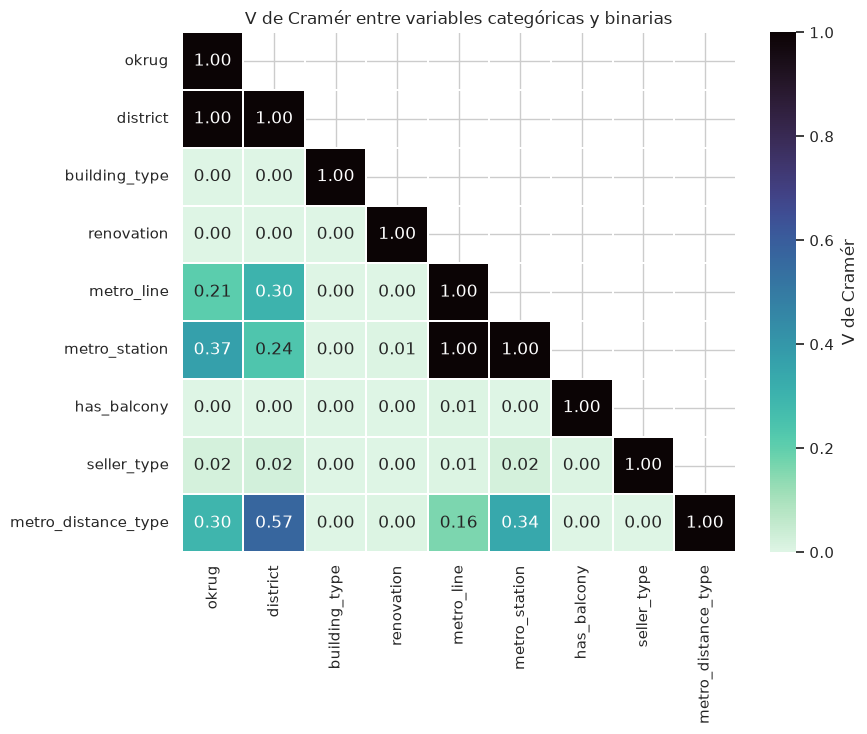


Tabla de contingencia: okrug × metro_distance_type


metro_distance_type,transport,walk,Total
okrug,,,
CAO,2107,1792,3899
NAO,3947,220,4167
SAO,4529,1327,5856
SVAO,5944,718,6662
SZAO,2452,969,3421
TAO,3950,0,3950
VAO,4350,1741,6091
YuAO,5068,1150,6218
YuZAO,3293,1465,4758


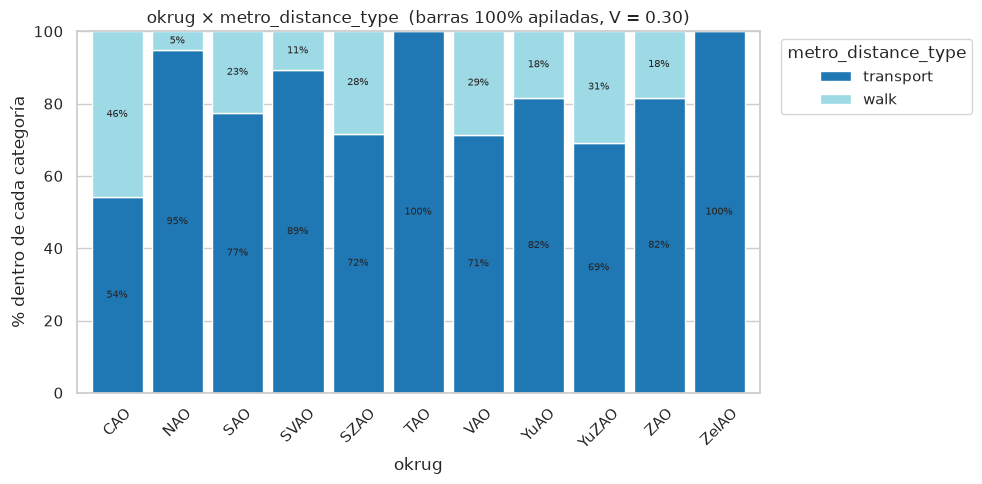


Tabla de contingencia: okrug × metro_line


metro_line,Arbatsko-Pokrovskaya,Bolshaya Koltsevaya,Filyovskaya,Kalininskaya,Kaluzhsko-Rizhskaya,Koltsevaya,Lyublinsko-Dmitrovskaya,MCC,Serpukhovsko-Timiryazevskaya,Sokolnicheskaya,Tagansko-Krasnopresnenskaya,Zamoskvoretskaya,Total
okrug,,,,,,,,,,,,,
CAO,214,17,364,162,307,911,371,30,470,464,289,300,3899
NAO,370,101,387,113,900,282,218,73,595,617,231,280,4167
SAO,408,246,434,91,378,484,277,63,652,361,636,1826,5856
SVAO,542,97,429,206,1616,668,513,72,776,708,444,591,6662
SZAO,1051,53,314,44,151,181,108,40,196,201,592,490,3421
TAO,391,81,427,163,511,364,271,78,528,537,284,315,3950
VAO,1605,44,180,1233,344,363,372,55,317,1141,240,197,6091
YuAO,293,242,321,206,686,349,539,181,2042,485,296,578,6218
YuZAO,172,165,253,73,1812,240,179,40,785,730,143,166,4758


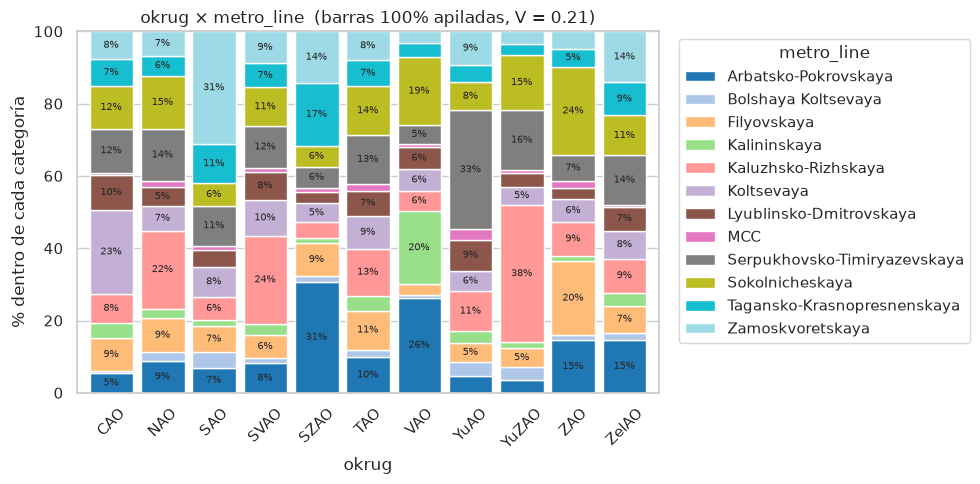


Tabla de contingencia: metro_line × metro_distance_type


metro_distance_type,transport,walk,Total
metro_line,,,
Arbatsko-Pokrovskaya,4355,1415,5770
Bolshaya Koltsevaya,894,225,1119
Filyovskaya,3716,365,4081
Kalininskaya,1661,714,2375
Kaluzhsko-Rizhskaya,5173,1992,7165
Koltsevaya,3448,721,4169
Lyublinsko-Dmitrovskaya,2810,196,3006
MCC,681,44,725
Serpukhovsko-Timiryazevskaya,5164,1581,6745


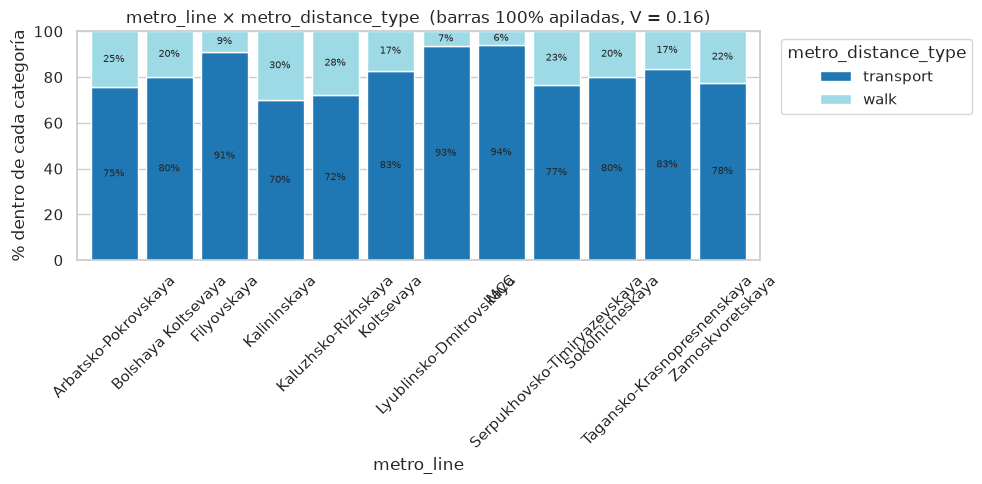

Prueba chi-cuadrado de independencia (H0: las dos variables son independientes)


chi2   gl    p_valor  V_Cramér
var_1      var_2                                                   
okrug      metro_distance_type   4374.929   10   0.00e+00     0.295
           metro_line           21642.954  110   0.00e+00     0.208
metro_line metro_distance_type   1320.574   11  1.64e-276     0.162

In [21]:
# --- Gráfico principal: heatmap de V de Cramér (reusa la matriz M de la celda de asociación mixta) ---
V = M.loc[CAT_ALL, CAT_ALL]
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(V, mask=np.triu(np.ones_like(V, dtype=bool), k=1), vmin=0, vmax=1, cmap="mako_r",
            annot=True, fmt=".2f", linewidths=0.3, cbar_kws={"label": "V de Cramér"}, ax=ax)
ax.set_title("V de Cramér entre variables categóricas y binarias")
plt.tight_layout()
plt.show()

# --- Complemento: los 3 pares más asociados (con <= 12 niveles cada uno, para que se lea bien) ---
cand = []
for i, a in enumerate(CAT_ALL):
    for b in CAT_ALL[i + 1:]:
        if eda[a].nunique() <= 12 and eda[b].nunique() <= 12:
            cand.append((V.loc[a, b], a, b))
top_pairs = sorted(cand, reverse=True)[:3]

res = []
for v, a, b in top_pairs:
    ct = pd.crosstab(eda[a], eda[b])
    print(f"\nTabla de contingencia: {a} × {b}")
    display(pd.crosstab(eda[a], eda[b], margins=True, margins_name="Total"))

    pct = pd.crosstab(eda[a], eda[b], normalize="index") * 100
    fig, ax = plt.subplots(figsize=(10, 5))
    pct.plot(kind="bar", stacked=True, ax=ax, colormap="tab20", width=0.85)
    for c in ax.containers:
        ax.bar_label(c, labels=[f"{h:.0f}%" if h >= 5 else "" for h in c.datavalues],
                     label_type="center", fontsize=7)
    ax.set(ylabel="% dentro de cada categoría", ylim=(0, 100),
           title=f"{a} × {b}  (barras 100% apiladas, V = {v:.2f})")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title=b, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    chi2, p, dof, _ = chi2_contingency(ct)
    res.append({"var_1": a, "var_2": b, "chi2": chi2, "gl": dof, "p_valor": p, "V_Cramér": v})

print("Prueba chi-cuadrado de independencia (H0: las dos variables son independientes)")
show(pd.DataFrame(res).set_index(["var_1", "var_2"]), p_cols=["p_valor"])

### EDA-12 (opcional): chi² de cada categórica contra el precio

In [22]:
# EDA-12 (opcional): chi² de independencia de cada categórica contra el precio en 5 tramos (quintiles).
# Los tramos existen solo dentro de la función: no se agrega nada a df.
def chi2_filtro(data, target, cat_cols, bins=5):
    tramos = pd.qcut(data[target], bins, labels=False)
    filas = []
    for c in cat_cols:
        ct = pd.crosstab(data[c], tramos)
        chi2, p, gl, esp = chi2_contingency(ct)
        n, r, k = ct.values.sum(), *ct.shape
        phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
        rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
        filas.append({"variable": c, "niveles": r, "chi2": chi2, "gl": gl, "p_valor": p,
                      "V_Cramér": np.sqrt(phi2c / min(kc - 1, rc - 1)),
                      "%celdas_esp<5": 100 * (esp < 5).mean()})
    return pd.DataFrame(filas).set_index("variable").sort_values("V_Cramér", ascending=False)

t = chi2_filtro(eda, TARGET, ["district", "okrug", "metro_distance_type", "metro_station", "renovation",
                              "building_type", "metro_line", "has_balcony", "seller_type"])
t["p_valor"] = t["p_valor"].map(lambda v: f"{v:.2e}")
print("Con 50.000 filas casi todo da p ≈ 0: mirar el tamaño del efecto (V de Cramér). Solo importa el orden relativo.")
show(t, dec=3)

Con 50.000 filas casi todo da p ≈ 0: mirar el tamaño del efecto (V de Cramér). Solo importa el orden relativo.


,niveles,chi2,gl,p_valor,V_Cramér,%celdas_esp<5
variable,,,,,,
district,129,47623.682,512,0.00e+00,0.485,0.0
okrug,11,37218.137,40,0.00e+00,0.431,0.0
metro_distance_type,2,7449.604,4,0.00e+00,0.386,0.0
metro_station,104,3161.790,412,0.00e+00,0.117,0.0
renovation,4,1997.003,12,0.00e+00,0.115,0.0
building_type,6,1360.134,20,3.89e-276,0.082,0.0
metro_line,12,642.001,44,3.54e-107,0.055,0.0
has_balcony,2,18.949,4,8.04e-04,0.017,0.0
seller_type,2,5.048,4,2.82e-01,0.005,0.0


## 4. Outliers

Primero se documenta **cuántos son y en qué parte del precio caen** (con todos los datos). Después se aplica el criterio y se verifica que el dataset no se distorsione.

### 4.1 Análisis: cuántos son y dónde caen respecto del precio

Outliers por variable (regla 1,5×IQR) y posición de su precio. Percentil 50 = precio típico; cerca de 0 = anuncios baratos; cerca de 100 = caros


,n_bajo,n_alto,n_outliers,%_del_dataset,n_extremos (3×IQR),precio_med_outliers (M),precio_med_resto (M),percentil_precio_outliers
variable,,,,,,,,
price_rub,0,2459,2459,4.92,604,36.09,10.69,97.54
total_area,0,687,687,1.37,0,20.78,11.00,85.98
living_area,0,767,767,1.53,0,18.80,11.00,82.00
kitchen_area,0,287,287,0.57,0,16.65,11.06,75.85
building_year,0,0,0,0.00,0,NaN,11.09,NaN
metro_distance_min,0,3893,3893,7.79,1659,3.68,11.72,5.01
to_center_km,0,4672,4672,9.34,2683,3.84,11.86,5.57
lat,1632,0,1632,3.26,0,3.41,11.35,4.00
lon,1906,0,1906,3.81,443,3.66,11.39,4.93


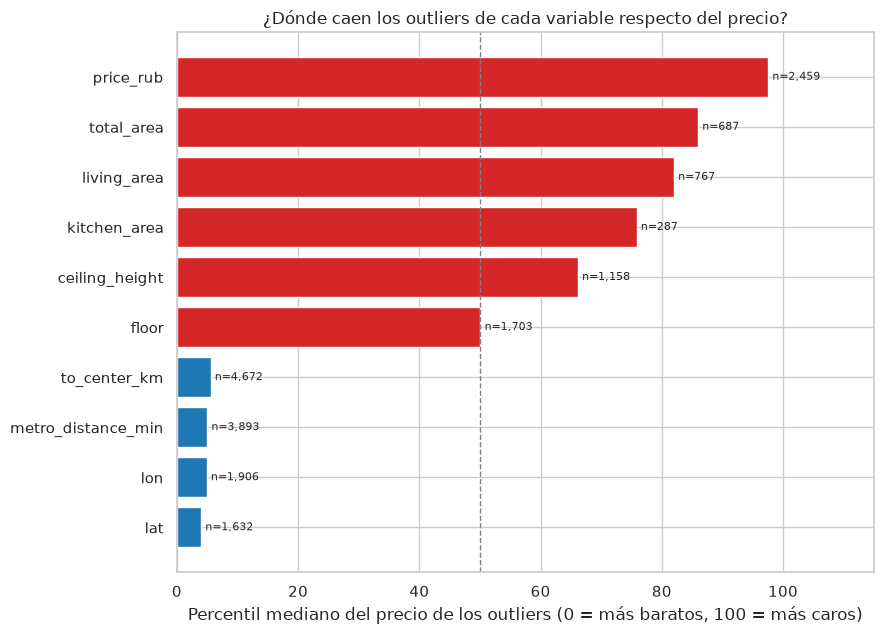


Precio: corte 1,5×IQR = 29.7 M → 2,459 anuncios (4.9 %)
        corte 3×IQR   = 43.1 M → 604 anuncios (1.21 %)
Percentiles del precio (M): {50: np.float64(11.1), 90: np.float64(23.6), 95: np.float64(29.6), 99: np.float64(44.7), 99.9: np.float64(65.6), 100: np.float64(93.4)}

Outliers de precio por tramo (M RUB):


,anuncios
price_rub,
"(29, 35]",1071
"(35, 40]",557
"(40, 50]",549
"(50, 60]",189
"(60, 100]",93


Dónde están (okrug):


,% de los outliers,% del dataset
okrug,,
CAO,70.1,7.8
ZAO,10.7,9.2
YuZAO,8.5,9.5
SZAO,3.9,6.8
SAO,3.7,11.7
VAO,1.2,12.2
SVAO,1.0,13.3
YuAO,0.9,12.4
NAO,0.0,8.3


Los 100 precios más altos: de 59.6 M a 93.4 M | okrug: {'CAO': 96, 'ZAO': 3, 'YuZAO': 1} | superficie mediana 98 m²
Efecto de esas 100 filas en el precio: media 13.12 M → 13.01 M | mediana 11.09 M → 11.07 M

Anuncios según en cuántas variables son outlier: {0: 39730, 1: 5980, 2: 3999, 3: 283, 4: 8}
≥1 variable: 10,270 (20.5 %) | ≥2: 4,290 (8.6 %)


In [23]:
# ---- Outliers: cuántos son y en qué parte del precio caen (no se agrega ninguna columna a eda) ----
pr = eda[TARGET].rank(pct=True) * 100            # percentil del precio de cada fila (serie local)
VARS_OUT = [c for c in NUM_CONT + NUM_DISC if c != "price_per_sqm"]

filas, flags = [], {}
for c in VARS_OUT:
    s = eda[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    bajo, alto = s < q1 - 1.5 * iqr, s > q3 + 1.5 * iqr
    out = bajo | alto
    flags[c] = out
    filas.append({"variable": c, "n_bajo": int(bajo.sum()), "n_alto": int(alto.sum()),
                  "n_outliers": int(out.sum()), "%_del_dataset": 100 * out.mean(),
                  "n_extremos (3×IQR)": int(((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).sum()),
                  "precio_med_outliers (M)": eda.loc[out, TARGET].median() / 1e6 if out.any() else np.nan,
                  "precio_med_resto (M)": eda.loc[~out, TARGET].median() / 1e6,
                  "percentil_precio_outliers": pr[out].median() if out.any() else np.nan})
tabla_out = pd.DataFrame(filas).set_index("variable")
print("Outliers por variable (regla 1,5×IQR) y posición de su precio. Percentil 50 = precio típico; cerca de 0 = anuncios baratos; cerca de 100 = caros")
show(tabla_out, dec=2)

# Gráfico: ¿en qué parte de la distribución del precio caen los outliers de cada variable?
g = tabla_out.dropna(subset=["percentil_precio_outliers"]).sort_values("percentil_precio_outliers")
fig, ax = plt.subplots(figsize=(9, 0.5 * len(g) + 1.5))
bars = ax.barh(g.index, g["percentil_precio_outliers"],
               color=["tab:red" if v > 50 else "tab:blue" for v in g["percentil_precio_outliers"]])
ax.axvline(50, color="gray", ls="--", lw=1)
ax.bar_label(bars, labels=[f"n={n:,}" for n in g["n_outliers"]], padding=3, fontsize=8)
ax.set(xlim=(0, 115), xlabel="Percentil mediano del precio de los outliers (0 = más baratos, 100 = más caros)",
       title="¿Dónde caen los outliers de cada variable respecto del precio?")
plt.tight_layout()
plt.show()

# ---- Outliers del precio: cuántos son y cómo se reparten ----
q1, q3 = eda[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
corte15, corte3 = q3 + 1.5 * iqr, q3 + 3 * iqr
po = eda[TARGET] > corte15
print(f"\nPrecio: corte 1,5×IQR = {corte15/1e6:.1f} M → {int(po.sum()):,} anuncios ({100*po.mean():.1f} %)")
print(f"        corte 3×IQR   = {corte3/1e6:.1f} M → {int((eda[TARGET] > corte3).sum()):,} anuncios ({100*(eda[TARGET] > corte3).mean():.2f} %)")
print("Percentiles del precio (M):", {p: round(eda[TARGET].quantile(p / 100) / 1e6, 1) for p in [50, 90, 95, 99, 99.9, 100]})

tramos = pd.cut(eda.loc[po, TARGET] / 1e6, [29, 35, 40, 50, 60, 100]).value_counts().sort_index()
print("\nOutliers de precio por tramo (M RUB):")
show(tramos.rename("anuncios").to_frame(), dec=0)

zona = pd.concat([eda.loc[po, "okrug"].value_counts(normalize=True).mul(100),
                  eda["okrug"].value_counts(normalize=True).mul(100)], axis=1,
                 keys=["% de los outliers", "% del dataset"]).fillna(0).sort_values("% de los outliers", ascending=False)
print("Dónde están (okrug):")
show(zona, dec=1)

top = eda.nlargest(100, TARGET)
print(f"Los 100 precios más altos: de {top[TARGET].min()/1e6:.1f} M a {top[TARGET].max()/1e6:.1f} M | "
      f"okrug: {top['okrug'].value_counts().to_dict()} | superficie mediana {top['total_area'].median():.0f} m²")
sin_top = eda.drop(top.index)
print(f"Efecto de esas 100 filas en el precio: media {eda[TARGET].mean()/1e6:.2f} M → {sin_top[TARGET].mean()/1e6:.2f} M "
      f"| mediana {eda[TARGET].median()/1e6:.2f} M → {sin_top[TARGET].median()/1e6:.2f} M")

# ---- Solapamiento: ¿son los mismos anuncios los que salen como outliers en varias variables? ----
indep = [c for c in VARS_OUT if c not in ("lat", "lon", "living_area")]   # lat/lon/living_area repiten a otras
k = pd.DataFrame({c: flags[c] for c in indep}).sum(axis=1)
print("\nAnuncios según en cuántas variables son outlier:", k.value_counts().sort_index().to_dict())
print(f"≥1 variable: {int((k >= 1).sum()):,} ({100*(k >= 1).mean():.1f} %) | ≥2: {int((k >= 2).sum()):,} ({100*(k >= 2).mean():.1f} %)")

### 4.2 Funciones para marcar y comparar outliers

In [24]:
def mascara_outliers(data, target, criterio, k=1.5, grupo=None, z=3.0, cols_modelo=None, cats_modelo=None, pct=99, log_target=False):
    """Devuelve una máscara booleana (True = outlier). No agrega columnas a `data`.
    criterio:
      'iqr'        regla k·IQR sobre el target, global
      'iqr_grupo'  regla k·IQR sobre el target DENTRO de cada categoría de `grupo` (ej. 'okrug')
      'percentil'  precios por encima del percentil `pct`
      'residuo'    |residuo studentizado| > z en un OLS del target (usa cols_modelo y cats_modelo)
    """
    s = data[target]
    if criterio == "iqr":
        q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
        return (s < q1 - k * i) | (s > q3 + k * i)
    if criterio == "iqr_grupo":
        g = s.groupby(data[grupo])
        q1, q3 = g.transform(lambda x: x.quantile(0.25)), g.transform(lambda x: x.quantile(0.75))
        return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))
    if criterio == "percentil":
        return s > s.quantile(pct / 100)
    if criterio == "residuo":
        X = sm.add_constant(pd.concat([data[cols_modelo].astype(float),
                                       pd.get_dummies(data[cats_modelo], drop_first=True, dtype=float)], axis=1))
        y = np.log(s) if log_target else s.astype(float)
        r = sm.OLS(y, X).fit()
        return pd.Series(np.abs(r.get_influence().resid_studentized_internal) > z, index=data.index)
    raise ValueError("criterio no reconocido")

def resumen_outliers(data, target, mask, nombre="criterio"):
    """Cuántos son, dónde están y en qué parte del precio caen."""
    n = int(mask.sum())
    print(f"{nombre}: {n:,} observaciones ({100*n/len(data):.2f} % del dataset)")
    if n == 0:
        return
    print(f"  precio de los marcados: {data.loc[mask, target].min()/1e6:.1f} M a {data.loc[mask, target].max()/1e6:.1f} M "
          f"| percentil mediano del precio: {data[target].rank(pct=True)[mask].median()*100:.0f}")
    z = pd.concat([data.loc[mask, "okrug"].value_counts(normalize=True).mul(100),
                   data["okrug"].value_counts(normalize=True).mul(100)], axis=1,
                  keys=["% de los marcados", "% del dataset"]).fillna(0).round(1)
    show(z.sort_values("% de los marcados", ascending=False).T, dec=1)

def comparar_sin_outliers(data, target, mask, num_feats, cat_feats, log_target=False):
    """Ajusta el OLS con todas las filas y sin los outliers, y compara."""
    def ajustar(d):
        X = sm.add_constant(pd.concat([d[num_feats].astype(float),
                                       pd.get_dummies(d[cat_feats], drop_first=True, dtype=float)], axis=1))
        y = np.log(d[target]) if log_target else d[target].astype(float)
        return sm.OLS(y, X).fit()
    a, b = ajustar(data), ajustar(data.loc[~mask])
    t = pd.DataFrame({"todas": a.params[num_feats], "sin outliers": b.params[num_feats]})
    t["cambio_%"] = 100 * (t["sin outliers"] / t["todas"] - 1)
    print(f"R² ajustado: {a.rsquared_adj:.4f} → {b.rsquared_adj:.4f} | observaciones: {int(a.nobs):,} → {int(b.nobs):,}")
    show(t, dec=4)

### 4.3 Criterio elegido y su efecto en el baseline

Precio > Q3 + 1,5·IQR **dentro de cada okrug**. Alternativas en `mascara_outliers`: `"iqr_grupo"` con `k=3` (más conservador, ~142 anuncios), `"iqr"` global, `"percentil"` o `"residuo"`.

In [25]:
# Variables del baseline (se usan también para medir el efecto de la limpieza)
NUM_BASE = ["total_area", "metro_distance_min", "mortgage_rate_at_listing"]
CAT_BASE = ["renovation", "building_type", "metro_distance_type", "district"]

# Criterio: precio > Q3 + 1,5·IQR calculado DENTRO de cada okrug (una sola pasada, solo sobre el precio)
mask = mascara_outliers(df, TARGET, "iqr_grupo", k=1.5, grupo="okrug")
resumen_outliers(df, TARGET, mask, nombre="Outliers (precio > Q3 + 1,5·IQR dentro de su okrug)")

# Cuánto pierde cada okrug (que ninguna zona quede desproporcionadamente recortada)
perd = pd.concat([df[mask].groupby("okrug").size(), df.groupby("okrug").size()],
                 axis=1, keys=["quitadas", "total"]).fillna(0)
perd["% del okrug"] = 100 * perd["quitadas"] / perd["total"]
print("\nAnuncios quitados por okrug:")
show(perd.sort_values("% del okrug").T, dec=1)

# Efecto sobre los coeficientes del baseline (OLS sin log), con y sin esos anuncios
print("\nCoeficientes del baseline con y sin los outliers:")
comparar_sin_outliers(df, TARGET, mask, NUM_BASE, CAT_BASE)

Outliers (precio > Q3 + 1,5·IQR dentro de su okrug): 1,436 observaciones (2.87 % del dataset)
  precio de los marcados: 7.4 M a 93.4 M | percentil mediano del precio: 95


okrug,SVAO,YuAO,VAO,SAO,YuZAO,ZAO,NAO,SZAO,CAO,TAO,ZelAO
% de los marcados,14.8,13.8,12.3,10.9,10.0,9.1,8.3,7.4,7.2,5.8,0.4
% del dataset,13.3,12.4,12.2,11.7,9.5,9.2,8.3,6.8,7.8,7.9,0.7



Anuncios quitados por okrug:


okrug,ZelAO,TAO,CAO,SAO,ZAO,NAO,VAO,YuZAO,SZAO,YuAO,SVAO
quitadas,6.0,84.0,103.0,157.0,131.0,119.0,176.0,143.0,106.0,198.0,213.0
total,361.0,3950.0,3899.0,5856.0,4617.0,4167.0,6091.0,4758.0,3421.0,6218.0,6662.0
% del okrug,1.7,2.1,2.6,2.7,2.8,2.9,2.9,3.0,3.1,3.2,3.2



Coeficientes del baseline con y sin los outliers:
R² ajustado: 0.8622 → 0.8773 | observaciones: 50,000 → 48,564


,todas,sin outliers,cambio_%
total_area,195676.1242,177280.4885,-9.4011
metro_distance_min,-25761.0128,-23108.2535,-10.2976
mortgage_rate_at_listing,221701.6218,205876.8258,-7.1379


### 4.4 Aplicar el filtro

Se filtran filas (no se crean columnas). Desde acá `df` es el dataset **sin outliers** y `df_completo` guarda todos los anuncios. `eda` sigue apuntando al dataset completo, así que el EDA de arriba queda documentado con todos los datos.

In [26]:
# Aplicar el filtro (se filtran FILAS, no se crean columnas). Es seguro correr esta celda más de una vez.
if "df_completo" not in globals():
    df_completo = df.copy()                       # copia con TODOS los anuncios (para la comparación de sensibilidad)
mask = mascara_outliers(df_completo, TARGET, "iqr_grupo", k=1.5, grupo="okrug")
df = df_completo.loc[~mask].reset_index(drop=True)
print(f"Dataset completo: {len(df_completo):,} → sin outliers: {len(df):,}  (se quitaron {int(mask.sum()):,}, {100*mask.mean():.2f} %)")
print(f"Precio máximo que queda: {df[TARGET].max()/1e6:.1f} M (dominio del modelo)")
print("Precio máximo que queda por okrug (M):", (df.groupby('okrug')[TARGET].max() / 1e6).round(1).sort_values(ascending=False).to_dict())

Dataset completo: 50,000 → sin outliers: 48,564  (se quitaron 1,436, 2.87 %)
Precio máximo que queda: 58.6 M (dominio del modelo)
Precio máximo que queda por okrug (M): {'CAO': 58.6, 'ZAO': 34.1, 'YuZAO': 31.7, 'SZAO': 29.1, 'SAO': 27.6, 'VAO': 23.0, 'YuAO': 22.5, 'SVAO': 21.7, 'NAO': 13.0, 'ZelAO': 11.6, 'TAO': 7.3}


### 4.5 Verificación tras la limpieza

In [27]:
# Verificación tras la limpieza: que no se haya distorsionado el dataset (df_completo vs df)
def resumen_precio(d):
    s = d[TARGET]
    return {"filas": len(d), "media (M)": s.mean() / 1e6, "mediana (M)": s.median() / 1e6,
            "máximo (M)": s.max() / 1e6, "asimetría": s.skew(), "curtosis": s.kurt()}
show(pd.DataFrame({"completo": resumen_precio(df_completo), "sin outliers": resumen_precio(df)}), dec=2)

for c in ["renovation", "building_type", "okrug"]:
    comp = pd.concat([df_completo[c].value_counts(normalize=True).mul(100),
                      df[c].value_counts(normalize=True).mul(100)], axis=1, keys=["% completo", "% sin outliers"])
    print(f"\nComposición de {c}:")
    show(comp.T, dec=1)

asoc = {}
for c in NUM_BASE:
    asoc[c] = {"Spearman completo": stats.spearmanr(df_completo[c], df_completo[TARGET])[0],
               "Spearman sin outliers": stats.spearmanr(df[c], df[TARGET])[0]}
print("\nAsociación de las numéricas del baseline con el precio:")
show(pd.DataFrame(asoc).T, dec=3)

,completo,sin outliers
filas,50000.00,48564.00
media (M),13.12,12.60
mediana (M),11.09,10.88
máximo (M),93.44,58.55
asimetría,2.00,1.76
curtosis,6.56,4.76



Composición de renovation:


renovation,cosmetic,euro,no_renovation,designer
% completo,40.1,29.9,20.1,9.9
% sin outliers,40.6,29.6,20.5,9.3



Composición de building_type:


building_type,panel,monolith,modern_panel,brick,khrushchev,stalin
% completo,20.3,20.0,20.0,17.7,15.1,7.0
% sin outliers,20.6,19.7,20.0,17.6,15.4,6.7



Composición de okrug:


okrug,SVAO,YuAO,VAO,SAO,YuZAO,ZAO,NAO,TAO,CAO,SZAO,ZelAO
% completo,13.3,12.4,12.2,11.7,9.5,9.2,8.3,7.9,7.8,6.8,0.7
% sin outliers,13.3,12.4,12.2,11.7,9.5,9.2,8.3,8.0,7.8,6.8,0.7



Asociación de las numéricas del baseline con el precio:


,Spearman completo,Spearman sin outliers
total_area,0.421,0.394
metro_distance_min,-0.652,-0.643
mortgage_rate_at_listing,0.164,0.154


## 5. Baseline con MLflow

Variables: `total_area`, `to_center_km`, `metro_distance_min`, `mortgage_rate_at_listing` + `okrug`, `renovation`, `building_type`, `metro_distance_type`.

Cada corrida guarda parámetros, métricas, `summary.txt`, `coefficients.csv` y 6 gráficos de residuos (MLflow: corrida → Artifacts → `plots/`). Para abrir la interfaz, desde la terminal de la VM: `mlflow ui --backend-store-uri sqlite:////home/facucasa/Regresion_parcial/mlflow.db`

### 5.1 Colinealidad entre las predictoras (VIF)

In [28]:
# Colinealidad entre las predictoras del baseline (VIF; solo mira las X, no el target)
from statsmodels.stats.outliers_influence import variance_inflation_factor
Xv = sm.add_constant(pd.concat([df[NUM_BASE].astype(float),
                                pd.get_dummies(df[CAT_BASE], drop_first=True, dtype=float)], axis=1))
vif = pd.Series({c: variance_inflation_factor(Xv.to_numpy(), i) for i, c in enumerate(Xv.columns) if c != "const"})
print("VIF de las numéricas (referencia: < 5 sin problema, 5-10 moderado, > 10 alto):")
show(vif[NUM_BASE].round(2).to_frame("VIF"), dec=2)
print(f"VIF máximo entre las dummies: {vif.drop(NUM_BASE).max():.2f} ({vif.drop(NUM_BASE).idxmax()})")

VIF de las numéricas (referencia: < 5 sin problema, 5-10 moderado, > 10 alto):


,VIF
total_area,1.01
metro_distance_min,8.66
mortgage_rate_at_listing,1.00


VIF máximo entre las dummies: 3.31 (district_Kievsky)


### 5.2 Funciones de modelado

In [34]:
def build_X(df, num_feats, cat_feats):
    """Numéricas + dummies (drop_first) de las categóricas + constante."""
    X = df[num_feats].astype(float).copy()   # bool -> 0/1 también
    if cat_feats:
        dummies = pd.get_dummies(df[cat_feats], drop_first=True, dtype=float)
        X = pd.concat([X, dummies], axis=1)
    return sm.add_constant(X, has_constant="add")

def residual_plots(res, X, num_feats):
    """Devuelve {nombre_archivo: figura} con los gráficos de residuos."""
    infl = res.get_influence()
    fitted = res.fittedvalues
    resid = res.resid
    stud = infl.resid_studentized_internal
    figs = {}

    # 1) Residuos vs ajustados
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(fitted, resid, s=4, alpha=0.2)
    ax.axhline(0, color="red", lw=1)
    ax.set(xlabel="Valores ajustados", ylabel="Residuos", title="Residuos vs ajustados")
    figs["resid_vs_fitted"] = fig

    # 2) QQ-plot
    fig, ax = plt.subplots(figsize=(6, 6))
    sm.qqplot(stud, line="45", ax=ax, markersize=2, alpha=0.3)
    ax.set_title("QQ-plot (residuos studentizados)")
    figs["qq_plot"] = fig

    # 3) Histograma de residuos
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(resid, bins=80, density=True, alpha=0.7)
    xs = np.linspace(resid.min(), resid.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), color="red", lw=1)
    ax.set(xlabel="Residuos", ylabel="Densidad", title="Distribución de residuos")
    figs["resid_hist"] = fig

    # 4) Scale-location (homocedasticidad)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(fitted, np.sqrt(np.abs(stud)), s=4, alpha=0.2)
    ax.set(xlabel="Valores ajustados", ylabel="√|residuo studentizado|", title="Scale-Location")
    figs["scale_location"] = fig

    # 5) Leverage vs residuos studentizados
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(infl.hat_matrix_diag, stud, s=4, alpha=0.2)
    ax.axhline(0, color="red", lw=1)
    ax.set(xlabel="Leverage", ylabel="Residuo studentizado", title="Leverage vs residuos")
    figs["leverage_vs_resid"] = fig

    # 6) Residuos vs cada variable numérica
    n = len(num_feats)
    if n:
        cols = 3
        rows = int(np.ceil(n / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.5 * rows), squeeze=False)
        for ax, feat in zip(axes.ravel(), num_feats):
            ax.scatter(X[feat], resid, s=3, alpha=0.15)
            ax.axhline(0, color="red", lw=1)
            ax.set(xlabel=feat, ylabel="Residuos")
        for ax in axes.ravel()[n:]:
            ax.axis("off")
        fig.suptitle("Residuos vs predictoras numéricas")
        fig.tight_layout()
        figs["resid_vs_features"] = fig

    return figs

def run_ols(num_feats, cat_feats=(), run_name=None, log_target=False, notes=None):
    num_feats, cat_feats = list(num_feats), list(cat_feats)

    X = build_X(df, num_feats, cat_feats)
    y = np.log(df[TARGET]) if log_target else df[TARGET].astype(float)

    with mlflow.start_run(run_name=run_name) as run:
        res = sm.OLS(y, X).fit()

        # ---------- Parámetros de la corrida ----------
        mlflow.log_params({
            "target": TARGET,
            "log_target": log_target,
            "num_features": ", ".join(num_feats),
            "cat_features": ", ".join(cat_feats),
            "n_features_total": X.shape[1] - 1,   # sin constante
        })
        mlflow.set_tag("model_type", "OLS")
        if notes:
            mlflow.set_tag("notes", notes)

        # ---------- Métricas del summary() ----------
        omni, omni_p = omni_normtest(res.resid)
        jb, jb_p, skew, kurt = jarque_bera(res.resid)
        metrics = {
            "r2": res.rsquared,
            "r2_adj": res.rsquared_adj,
            "f_statistic": res.fvalue,
            "f_pvalue": res.f_pvalue,
            "log_likelihood": res.llf,
            "aic": res.aic,
            "bic": res.bic,
            "nobs": res.nobs,
            "df_model": res.df_model,
            "df_resid": res.df_resid,
            "omnibus": omni,
            "omnibus_pvalue": omni_p,
            "durbin_watson": durbin_watson(res.resid),
            "jarque_bera": jb,
            "jarque_bera_pvalue": jb_p,
            "skew": skew,
            "kurtosis": kurt,
            "cond_no": res.condition_number,
        }

        # ---------- Métricas de error (escala original, en RUB) ----------
        pred = res.predict(X)
        if log_target:
            pred = np.exp(pred)
        y_orig = df[TARGET]
        mse = mean_squared_error(y_orig, pred)
        metrics.update({
            "mse": mse,
            "rmse": np.sqrt(mse),
            "mae": mean_absolute_error(y_orig, pred),
            "rss": float(np.sum((y_orig - pred) ** 2)),
        })
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})

        # ---------- Artefactos: summary completo + tabla de coeficientes ----------
        mlflow.log_text(str(res.summary()), "summary.txt")
        coef_table = pd.concat(
            [res.params, res.bse, res.tvalues, res.pvalues, res.conf_int()], axis=1
        )
        coef_table.columns = ["coef", "std_err", "t", "p_value", "ci_low", "ci_high"]
        mlflow.log_text(coef_table.to_csv(), "coefficients.csv")

        # ---------- Gráficos de residuos ----------
        figs = residual_plots(res, X, num_feats)
        for fname, fig in figs.items():
            mlflow.log_figure(fig, f"plots/{fname}.png")
            plt.close(fig)

        print(f"Run {run.info.run_id} | R2={res.rsquared:.4f} | "
              f"R2adj={res.rsquared_adj:.4f} | RMSE={metrics['rmse']:,.0f}")
    return res

### 5.3 Corrida del baseline (sin outliers)

In [35]:
res_baseline = run_ols(NUM_BASE, CAT_BASE, run_name="Sin to center km y con log", log_target=True,
                       notes="LO unico que hacemos es aplicar transformacion logaritmica a nuestra variable objetivo para ver que tanto mejora la asimetria y los residuos")

Run 9451de87c9364e5e9dbb3d29823e7e21 | R2=0.9466 | R2adj=0.9464 | RMSE=2,291,828


### 5.4 Errores estándar robustos y resumen

Sin log, el error crece con el precio: los errores estándar clásicos pueden no ser fiables, por eso se comparan con los robustos (HC3).

In [ ]:
# Errores estándar clásicos vs robustos (HC3): con residuos de varianza desigual, los clásicos no son fiables
rob = res_baseline.get_robustcov_results(cov_type="HC3")
tse = pd.DataFrame({"coef": res_baseline.params, "ee_clásico": res_baseline.bse,
                    "ee_HC3": pd.Series(rob.bse, index=res_baseline.params.index)})
tse["cambio_%"] = 100 * (tse["ee_HC3"] / tse["ee_clásico"] - 1)
show(tse.loc[["const"] + NUM_BASE], dec=4)
print("Resumen del baseline:")
print(res_baseline.summary())

### 5.5 Sensibilidad: el mismo baseline con todos los anuncios

Se registra en MLflow para comparar con y sin la limpieza de outliers.

In [33]:
# Sensibilidad: el mismo baseline con TODOS los anuncios (incluye los outliers) para comparar en MLflow
df_limpio = df
df = df_completo
res_baseline_completo = run_ols(NUM_BASE, CAT_BASE, run_name="baseline_con_outliers", log_target=False,
                                notes="Baseline con todos los anuncios (incluye outliers)")
df = df_limpio

Run ff1f0b866812421481e8eb51a9d71280 | R2=0.8085 | R2adj=0.8085 | RMSE=3,747,184


In [38]:
from sklearn.model_selection import KFold

def cv_rmse(num, cat, k=5, log_target=False):
    kf = KFold(k, shuffle=True, random_state=SEED)
    X = build_X(df, num, cat)           # dummies sobre todo df: evita columnas faltantes por fold
    y = np.log(df[TARGET]) if log_target else df[TARGET].astype(float)
    errs = []
    for tr, te in kf.split(X):
        m = sm.OLS(y.iloc[tr], X.iloc[tr]).fit()
        p = m.predict(X.iloc[te])
        p = np.exp(p) if log_target else p
        errs.append(np.sqrt(np.mean((df[TARGET].iloc[te] - p) ** 2)))
    return np.mean(errs), np.std(errs)

CAT_DIST = [c if c != "okrug" else "district" for c in CAT_BASE]
print("okrug   :", cv_rmse(NUM_BASE, CAT_BASE))
print("district:", cv_rmse(NUM_BASE, CAT_DIST))

okrug   : (np.float64(2728188.1655972004), np.float64(24457.036450219926))
district: (np.float64(2728188.1655972004), np.float64(24457.036450219926))
